In [1]:
import importlib
importlib.reload(importlib.import_module('analysis_utils_msr'))
import warnings
import pandas as pd
import numpy as np
from analysis_utils_msr import sum_individual_mutation_scores, assess_grouped_spearman, assess_grouped_gain, assess_grouped_ndcg, assess_classification_metric, add_additive_predictions, unify_similar_columns
import pandas as pd
import numpy as np
from functools import partial

# notebook display options
warnings.filterwarnings('ignore')

# Get all raw predictions
dataset = 'hyperopt_splits-test'
base_path = f'~/software/esm-msr/analysis_notebooks/predictions/{dataset}'
base_path_2 = f'~/software/esm-msr-release/analysis_notebooks/predictions/{dataset}'

msr_base_1 = f'{base_path_2}/msr_dual_ensemble_small_large_release/lora_seed1_last.safetensors'
msr_base_2 = f'{base_path_2}/msr_dual_ensemble_small_large_release/lora_seed2.safetensors'
msr_base_3 = f'{base_path_2}/msr_dual_ensemble_small_large_release/lora_seed3.safetensors'

chain_base_1 = f'{base_path}/msr_dual_ensemble_small_large_chain/1/epoch=04-val_rho_combined_avg=0.818.ckpt'
chain_base_2 = f'{base_path}/msr_dual_ensemble_small_large_chain/2/epoch=01-val_rho_combined_avg=0.816.ckpt'
chain_base_3 = f'{base_path}/msr_dual_ensemble_small_large_chain/3/epoch=02-val_rho_combined_avg=0.817.ckpt'

mm_base_1 = f'{base_path}/msr_dual_ensemble_small_large_mm/1/epoch=02-val_rho_combined_avg=0.808.ckpt'
mm_base_2 = f'{base_path}/msr_dual_ensemble_small_large_mm/2/epoch=02-val_rho_combined_avg=0.811.ckpt'
mm_base_3 = f'{base_path}/msr_dual_ensemble_small_large_mm/3/epoch=02-val_rho_combined_avg=0.807.ckpt'

single_base_1 = f'{base_path}/msr_dual_ensemble_small_large_singles/1/epoch=05-val_rho_combined_avg=0.809.ckpt'
single_base_2 = f'{base_path}/msr_dual_ensemble_small_large_singles/2/epoch=05-val_rho_combined_avg=0.810.ckpt'
single_base_3 = f'{base_path}/msr_dual_ensemble_small_large_singles/3/epoch=03-val_rho_combined_avg=0.809.ckpt'

reg_base_1 = f'{base_path}/msr_dual_ensemble_small_large_norank_mse20/1/epoch=03-val_rho_combined_avg=0.809.ckpt'
reg_base_2 = f'{base_path}/msr_dual_ensemble_small_large_norank_mse20/2/epoch=06-val_rho_combined_avg=0.812.ckpt'
reg_base_3 = f'{base_path}/msr_dual_ensemble_small_large_norank_mse20/3/epoch=06-val_rho_combined_avg=0.812.ckpt'

#hybrid_base = f'{base_path}/msr_dual_ensemble_masked_ss12/1/epoch=03-val_rho_combined_avg=0.818.ckpt'

full_alpha = '16.0'
med_alpha = '8.0'
low_alpha = '4.0'

full_sigma = '1'
med_sigma = '0.5'
low_sigma = '1.25'

In [2]:
# ================= THERMOMPNN =================

# 1. Load Single Model Predictions (for single mutants)
df_tm_1_single = pd.read_csv(f'{base_path}/thermompnnd/single_hyperopt_splits_correct_bb_1_epoch=99_val_ddG_spearman=0.73.ckpt_singles.csv', index_col=0)
df_tm_2_single = pd.read_csv(f'{base_path}/thermompnnd/single_hyperopt_splits_correct_bb_2_epoch=98_val_ddG_spearman=0.73.ckpt_singles.csv', index_col=0)
df_tm_3_single = pd.read_csv(f'{base_path}/thermompnnd/single_hyperopt_splits_correct_bb_3_epoch=99_val_ddG_spearman=0.73.ckpt_singles.csv', index_col=0)

# 2. Load Epistatic Model Predictions (for multimutants)
df_tm_1_epistatic = pd.read_csv(f'{base_path}/thermompnnd/epistatic_hyperopt_splits_correct_bb_1_epoch=84_val_ddG_spearman=0.74.ckpt.csv', index_col=0)
df_tm_2_epistatic = pd.read_csv(f'{base_path}/thermompnnd/epistatic_hyperopt_splits_correct_bb_2_epoch=56_val_ddG_spearman=0.73.ckpt.csv', index_col=0)
df_tm_3_epistatic = pd.read_csv(f'{base_path}/thermompnnd/epistatic_hyperopt_splits_correct_bb_3_epoch=95_val_ddG_spearman=0.73.ckpt.csv', index_col=0)

# 3. Load Additive Model Predictions (for multimutant baseline)
df_tm_1_additive = pd.read_csv(f'{base_path}/thermompnnd/additive_single_hyperopt_splits_correct_bb_1_epoch=99_val_ddG_spearman=0.73.ckpt.csv', index_col=0).dropna(subset='ddG_pred_additive')
df_tm_2_additive = pd.read_csv(f'{base_path}/thermompnnd/additive_single_hyperopt_splits_correct_bb_2_epoch=98_val_ddG_spearman=0.73.ckpt.csv', index_col=0).dropna(subset='ddG_pred_additive')
df_tm_3_additive = pd.read_csv(f'{base_path}/thermompnnd/additive_single_hyperopt_splits_correct_bb_3_epoch=99_val_ddG_spearman=0.73.ckpt.csv', index_col=0).dropna(subset='ddG_pred_additive')

# --- Construct ThermoMPNN column (Singles + Additive Multimutants) ---
df_tm_1_add_col = pd.concat([df_tm_1_single['ddG_pred'], df_tm_1_additive['ddG_pred_additive']]).to_frame('ThermoMPNN_1')
df_tm_2_add_col = pd.concat([df_tm_2_single['ddG_pred'], df_tm_2_additive['ddG_pred_additive']]).to_frame('ThermoMPNN_2')
df_tm_3_add_col = pd.concat([df_tm_3_single['ddG_pred'], df_tm_3_additive['ddG_pred_additive']]).to_frame('ThermoMPNN_3')

# --- Construct ThermoMPNN(-D) column (Epistatic Multimutants filled with Singles) ---
# FLAW: We must strictly filter the single model to only include non-colon indices 
# to prevent "additive" leaking into the "epistatic" column per prompt instructions.
df_tm_1_epi_col = df_tm_1_epistatic['ddG_pred'].rename('ThermoMPNN(-D)_1')
df_tm_1_epi_col = df_tm_1_epi_col.combine_first(df_tm_1_single.loc[~df_tm_1_single.index.str.contains(':'), 'ddG_pred'].rename('ThermoMPNN(-D)_1'))

df_tm_2_epi_col = df_tm_2_epistatic['ddG_pred'].rename('ThermoMPNN(-D)_2')
df_tm_2_epi_col = df_tm_2_epi_col.combine_first(df_tm_2_single.loc[~df_tm_2_single.index.str.contains(':'), 'ddG_pred'].rename('ThermoMPNN(-D)_2'))

df_tm_3_epi_col = df_tm_3_epistatic['ddG_pred'].rename('ThermoMPNN(-D)_3')
df_tm_3_epi_col = df_tm_3_epi_col.combine_first(df_tm_3_single.loc[~df_tm_3_single.index.str.contains(':'), 'ddG_pred'].rename('ThermoMPNN(-D)_3'))

# Assemble Thermo Ensemble
df_thermo = df_tm_1_add_col.join([df_tm_1_epi_col, df_tm_2_add_col, df_tm_2_epi_col, df_tm_3_add_col, df_tm_3_epi_col], how='inner')
# Attach ground truth from the first replicate
df_thermo = df_thermo.join(df_tm_1_single[['code', 'mut_type', 'ddG_true']].rename(columns={'ddG_true': 'ddG_ML_thermo'}))
df_thermo['ThermoMPNN(-D)_additive_1'] = df_thermo['ThermoMPNN_1']
df_thermo['ThermoMPNN(-D)_additive_2'] = df_thermo['ThermoMPNN_2']
df_thermo['ThermoMPNN(-D)_additive_3'] = df_thermo['ThermoMPNN_3']

# ================= SPURS =================

df_spurs_single_1 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.69_single_seed1.ckpt_single_predictions.csv', index_col=0)
df_spurs_single_1 = df_spurs_single_1.rename(columns={'ddg_pred': 'SPURS_additive_1'})
df_spurs_single_2 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.68_single_seed2.ckpt_single_predictions.csv', index_col=0)
df_spurs_single_2 = df_spurs_single_2.rename(columns={'ddg_pred': 'SPURS_additive_2'})
df_spurs_single_3 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.69_single_seed3.ckpt_single_predictions.csv', index_col=0)
df_spurs_single_3 = df_spurs_single_3.rename(columns={'ddg_pred': 'SPURS_additive_3'})

df_spurs_multi_1 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.77_multi_seed1.ckpt_multi_predictions.csv', index_col=0)
df_spurs_multi_1 = df_spurs_multi_1.rename(columns={'ddg_pred': 'SPURS_1'})
df_spurs_multi_2 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.77_multi_seed2.ckpt_multi_predictions.csv', index_col=0)
df_spurs_multi_2 = df_spurs_multi_2.rename(columns={'ddg_pred': 'SPURS_2'})
df_spurs_multi_3 = pd.read_csv(f'{base_path}/SPURS/step_0-val_rho_avg_spearman_0.75_multi_seed3.ckpt_multi_predictions.csv', index_col=0)
df_spurs_multi_3 = df_spurs_multi_3.rename(columns={'ddg_pred': 'SPURS_3'})

df_spurs_single = pd.concat([df_spurs_single_1, df_spurs_single_2[[c for c in df_spurs_single_2.columns if 'SPURS' in c]], df_spurs_single_3[[c for c in df_spurs_single_3.columns if 'SPURS' in c]]], axis=1)
df_spurs_multi = pd.concat([df_spurs_multi_1[[c for c in df_spurs_multi_1.columns if 'SPURS' in c]], df_spurs_multi_2[[c for c in df_spurs_multi_2.columns if 'SPURS' in c]], df_spurs_multi_3[[c for c in df_spurs_multi_3.columns if 'SPURS' in c]]], axis=1)
df_spurs = df_spurs_single.join(df_spurs_multi)

# ================= MUTATE EVERYTHING =================

df_me_1 = pd.read_csv(f'{base_path}/mutate_everything/af_double_hyperopt_splits_1_checkpoint-99.csv', index_col=0)
df_me_1['MutateEverything_1'] = df_me_1['ddG_pred']
df_me_1['ddG_ML_me'] = df_me_1['ddG_true']
df_me_2 = pd.read_csv(f'{base_path}/mutate_everything/af_double_hyperopt_splits_2_checkpoint-99.csv', index_col=0)
df_me_2['MutateEverything_2'] = df_me_2['ddG_pred']
df_me_3 = pd.read_csv(f'{base_path}/mutate_everything/af_double_hyperopt_splits_3_checkpoint-99.csv', index_col=0)
df_me_3['MutateEverything_3'] = df_me_3['ddG_pred']

df_me = df_me_1[['code', 'mut_type', 'MutateEverything_1', 'ddG_ML_me']].join(df_me_2[['MutateEverything_2']], how='inner').join(df_me_3[['MutateEverything_3']], how='inner')

assert len(df_me) == len(df_me_1)

df_me_additive_1 = pd.read_csv(f'{base_path}/mutate_everything/af_single_additive_hyperopt_splits_1_checkpoint-19.csv', index_col=0)
df_me_additive_1 = add_additive_predictions(df_me_additive_1, df_me)
df_me_additive_1 = df_me_additive_1[['code', 'mut_type', 'ddG_pred_additive']].rename(columns={'ddG_pred_additive': 'MutateEverything_additive_1'})

df_me_additive_2 = pd.read_csv(f'{base_path}/mutate_everything/af_single_additive_hyperopt_splits_2_checkpoint-19.csv', index_col=0)
df_me_additive_2 = add_additive_predictions(df_me_additive_2, df_me)[['code', 'mut_type', 'ddG_pred_additive']].rename(columns={'ddG_pred_additive': 'MutateEverything_additive_2'})

df_me_additive_3 = pd.read_csv(f'{base_path}/mutate_everything/af_single_additive_hyperopt_splits_3_checkpoint-19.csv', index_col=0)
df_me_additive_3 = add_additive_predictions(df_me_additive_3, df_me)[['code', 'mut_type', 'ddG_pred_additive']].rename(columns={'ddG_pred_additive': 'MutateEverything_additive_3'})

df_me_additive = df_me_additive_1[['MutateEverything_additive_1']].join(df_me_additive_2[['MutateEverything_additive_2']], how='inner').join(df_me_additive_3[['MutateEverything_additive_3']], how='inner')
assert len(df_me_additive) == len(df_me)
df_me = df_me.join(df_me_additive)
df_me['uid'] = df_me['code'] + '_' + df_me['mut_type']
df_me = df_me.set_index('uid')

# ================= ZERO SHOT & BASELINES =================

df_zero_sm = pd.read_csv(f'{base_path}/esm3_forge/zero_shot/esm3-small-2024-08/predictions_unmasked.csv', index_col=0).rename(columns={'esm3_score': 'ESM3-small', 'pred_additive': 'ESM3-small_additive'})
df_zero_sm = df_zero_sm.reset_index(drop=True)
df_zero_sm['uid'] = df_zero_sm['code'] + '_' + df_zero_sm['mut_type']
df_zero_sm = df_zero_sm.set_index('uid')
df_zero_med = pd.read_csv(f'{base_path}/esm3_forge/zero_shot/esm3-medium-2024-08/predictions_unmasked.csv', index_col=0).rename(columns={'esm3_score': 'ESM3-medium', 'pred_additive': 'ESM3-medium_additive'})
df_zero_med = df_zero_med.reset_index(drop=True)
df_zero_med['uid'] = df_zero_med['code'] + '_' + df_zero_med['mut_type']
df_zero_med = df_zero_med.set_index('uid')
df_zero_lg = pd.read_csv(f'{base_path}/esm3_forge/zero_shot/esm3-large-2024-03/predictions_unmasked.csv', index_col=0).rename(columns={'esm3_score': 'ESM3-large', 'pred_additive': 'ESM3-large_additive'})
df_zero_lg = df_zero_lg.reset_index(drop=True)
df_zero_lg['uid'] = df_zero_lg['code'] + '_' + df_zero_lg['mut_type']
df_zero_lg = df_zero_lg.set_index('uid')

df_mpnn = pd.read_csv(f'{base_path}/proteinmpnn/proteinmpnn_020_unmasked.csv', index_col=0).reset_index(drop=True).rename(columns={'mpnn_score': 'ProteinMPNN', 'mpnn_score_additive': 'ProteinMPNN_additive', 'uid.1': 'uid'}).set_index('uid')
#df_mpnn = pd.read_csv(f'{base_path}/proteinmpnn/proteinmpnn_020.csv', index_col=0).reset_index(drop=True).rename(columns={'mpnn_score': 'ProteinMPNN', 'mpnn_score_additive': 'ProteinMPNN_additive', 'uid.1': 'uid'}).set_index('uid')

# Rosetta Cartesian DDG
df_ros = pd.read_csv('/home/sareeves/software/esm-msr/analysis_notebooks/predictions/hyperopt_splits-test/rosetta/cartesian_ddg.csv', index_col=0)
df_ros['code'] = df_ros.index.to_series().apply(lambda x: x.split('_')[0])
df_ros['mut_type'] = df_ros.index.to_series().apply(lambda x: '_'.join(x.split('_')[1:]))
df_ros['Rosetta Cartesian DDG_1'] = df_ros['cartesian_ddg_1'] / 2.94
df_ros['ddG_pred'] = df_ros['cartesian_ddg_1'] / 2.94
df_ros = add_additive_predictions(df_ros, df_ros)
df_ros = df_ros.rename(columns={'ddG_pred_additive': 'Rosetta Cartesian DDG_additive_1'})
df_ros['Rosetta Cartesian DDG_2'] = df_ros['cartesian_ddg_2'] / 2.94
df_ros['ddG_pred'] = df_ros['cartesian_ddg_2'] / 2.94
df_ros = add_additive_predictions(df_ros, df_ros)
df_ros = df_ros.rename(columns={'ddG_pred_additive': 'Rosetta Cartesian DDG_additive_2'})
df_ros['Rosetta Cartesian DDG_3'] = df_ros['cartesian_ddg_3'] / 2.94
df_ros['ddG_pred'] = df_ros['cartesian_ddg_3'] / 2.94
df_ros = add_additive_predictions(df_ros, df_ros)
df_ros = df_ros.rename(columns={'ddG_pred_additive': 'Rosetta Cartesian DDG_additive_3'})

df_ros.index.name = 'uid'
df_ros = df_ros.reset_index()
df_ros['code'] = df_ros['uid'].apply(lambda x: x.split('_')[0])
df_ros['mut_type'] = df_ros['uid'].apply(lambda x: x.split('_')[-1])
df_ros = df_ros.set_index('uid')

# ================= ESM-MSR =================

truth = 'ddG_ML'

df_esm_1 = pd.read_csv(f'{msr_base_1}_sigma{full_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_1.loc[~df_esm_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_1.loc[~df_esm_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_1['ESM-MSR_1'] = df_esm_1['combined_pred']
df_esm_1['ESM-MSR_additive_1'] = df_esm_1['combined_pred_additive']
df_esm_1['ddG_ML_esm'] = df_esm_1[truth]

df_esm_2 = pd.read_csv(f'{msr_base_2}_sigma{full_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_2.loc[~df_esm_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_2.loc[~df_esm_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_2['ESM-MSR_2'] = df_esm_2['combined_pred']
df_esm_2['ESM-MSR_additive_2'] = df_esm_2['combined_pred_additive']

df_esm_3 = pd.read_csv(f'{msr_base_3}_sigma{full_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_3.loc[~df_esm_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_3.loc[~df_esm_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_3['ESM-MSR_3'] = df_esm_3['combined_pred']
df_esm_3['ESM-MSR_additive_3'] = df_esm_3['combined_pred_additive']

df_esm = pd.concat([df_esm_1, df_esm_2[[c for c in df_esm_2.columns if 'MSR' in c]], df_esm_3[[c for c in df_esm_3.columns if 'MSR' in c]]], axis=1)

df_esm_alpha_med_1 = pd.read_csv(f'{msr_base_1}_sigma{med_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_med_1.loc[~df_esm_alpha_med_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_med_1.loc[~df_esm_alpha_med_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_med_1['ESM-MSR_alpha_med_1'] = df_esm_alpha_med_1['combined_pred']
df_esm_alpha_med_1['ESM-MSR_alpha_med_additive_1'] = df_esm_alpha_med_1['combined_pred_additive']
df_esm_alpha_med_1['ddG_ML_esm'] = df_esm_alpha_med_1[truth]

df_esm_alpha_med_2 = pd.read_csv(f'{msr_base_2}_sigma{med_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_med_2.loc[~df_esm_alpha_med_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_med_2.loc[~df_esm_alpha_med_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_med_2['ESM-MSR_alpha_med_2'] = df_esm_alpha_med_2['combined_pred']
df_esm_alpha_med_2['ESM-MSR_alpha_med_additive_2'] = df_esm_alpha_med_2['combined_pred_additive']

df_esm_alpha_med_3 = pd.read_csv(f'{msr_base_3}_sigma{med_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_med_3.loc[~df_esm_alpha_med_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_med_3.loc[~df_esm_alpha_med_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_med_3['ESM-MSR_alpha_med_3'] = df_esm_alpha_med_3['combined_pred']
df_esm_alpha_med_3['ESM-MSR_alpha_med_additive_3'] = df_esm_alpha_med_3['combined_pred_additive']

df_esm_alpha_med = pd.concat([df_esm_alpha_med_1, df_esm_alpha_med_2[[c for c in df_esm_alpha_med_2.columns if 'MSR' in c]], df_esm_alpha_med_3[[c for c in df_esm_alpha_med_3.columns if 'MSR' in c]]], axis=1)

df_esm_alpha_low_1 = pd.read_csv(f'{msr_base_1}_sigma{low_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_low_1.loc[~df_esm_alpha_low_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_low_1.loc[~df_esm_alpha_low_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_low_1['ESM-MSR_alpha_low_1'] = df_esm_alpha_low_1['combined_pred']
df_esm_alpha_low_1['ESM-MSR_alpha_low_additive_1'] = df_esm_alpha_low_1['combined_pred_additive']
df_esm_alpha_low_1['ddG_ML_esm'] = df_esm_alpha_low_1[truth]

df_esm_alpha_low_2 = pd.read_csv(f'{msr_base_2}_sigma{low_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_low_2.loc[~df_esm_alpha_low_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_low_2.loc[~df_esm_alpha_low_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_low_2['ESM-MSR_alpha_low_2'] = df_esm_alpha_low_2['combined_pred']
df_esm_alpha_low_2['ESM-MSR_alpha_low_additive_2'] = df_esm_alpha_low_2['combined_pred_additive']

df_esm_alpha_low_3 = pd.read_csv(f'{msr_base_3}_sigma{low_sigma}_unmasked_predictions.csv', index_col=0)
#df_esm_alpha_low_3.loc[~df_esm_alpha_low_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_alpha_low_3.loc[~df_esm_alpha_low_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_alpha_low_3['ESM-MSR_alpha_low_3'] = df_esm_alpha_low_3['combined_pred']
df_esm_alpha_low_3['ESM-MSR_alpha_low_additive_3'] = df_esm_alpha_low_3['combined_pred_additive']

df_esm_alpha_low = pd.concat([df_esm_alpha_low_1, df_esm_alpha_low_2[[c for c in df_esm_alpha_low_2.columns if 'MSR' in c]], df_esm_alpha_low_3[[c for c in df_esm_alpha_low_3.columns if 'MSR' in c]]], axis=1)

df_esm_zs = pd.read_csv(f'{base_path}/zeroshot_alpha0_predictions.csv', index_col=0).sort_index()
df_esm_zs['ESM3-small-open'] = df_esm_zs['combined_pred']
df_esm_zs['ESM3-small-open_additive'] = df_esm_zs['combined_pred_additive']

df_esm_single_1 = pd.read_csv(f'{single_base_1}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_single_1.loc[~df_esm_single_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_single_1.loc[~df_esm_single_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_single_1['ESM-MSR_single_1'] = df_esm_single_1['combined_pred']
df_esm_single_1['ESM-MSR_single_additive_1'] = df_esm_single_1['combined_pred_additive']
df_esm_single_1['ddG_ML_esm'] = df_esm_single_1[truth]

df_esm_single_2 = pd.read_csv(f'{single_base_2}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_single_2.loc[~df_esm_single_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_single_2.loc[~df_esm_single_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_single_2['ESM-MSR_single_2'] = df_esm_single_2['combined_pred']
df_esm_single_2['ESM-MSR_single_additive_2'] = df_esm_single_2['combined_pred_additive']

df_esm_single_3 = pd.read_csv(f'{single_base_3}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_single_3.loc[~df_esm_single_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_single_3.loc[~df_esm_single_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_single_3['ESM-MSR_single_3'] = df_esm_single_3['combined_pred']
df_esm_single_3['ESM-MSR_single_additive_3'] = df_esm_single_3['combined_pred_additive']

df_esm_single = pd.concat([df_esm_single_1, df_esm_single_2[[c for c in df_esm_single_2.columns if 'MSR' in c]], df_esm_single_3[[c for c in df_esm_single_3.columns if 'MSR' in c]]], axis=1)

df_esm_reg_1 = pd.read_csv(f'{reg_base_1}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_reg_1.loc[~df_esm_reg_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_reg_1.loc[~df_esm_reg_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_reg_1['ESM-MSR_reg_1'] = df_esm_reg_1['combined_pred']
df_esm_reg_1['ESM-MSR_reg_additive_1'] = df_esm_reg_1['combined_pred_additive']
df_esm_reg_1['ddG_ML_esm'] = df_esm_reg_1[truth]

df_esm_reg_2 = pd.read_csv(f'{reg_base_2}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_reg_2.loc[~df_esm_reg_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_reg_2.loc[~df_esm_reg_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_reg_2['ESM-MSR_reg_2'] = df_esm_reg_2['combined_pred']
df_esm_reg_2['ESM-MSR_reg_additive_2'] = df_esm_reg_2['combined_pred_additive']

df_esm_reg_3 = pd.read_csv(f'{reg_base_3}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_reg_3.loc[~df_esm_reg_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_reg_3.loc[~df_esm_reg_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_reg_3['ESM-MSR_reg_3'] = df_esm_reg_3['combined_pred']
df_esm_reg_3['ESM-MSR_reg_additive_3'] = df_esm_reg_3['combined_pred_additive']

df_esm_reg = pd.concat([df_esm_reg_1, df_esm_reg_2[[c for c in df_esm_reg_2.columns if 'MSR' in c]], df_esm_reg_3[[c for c in df_esm_reg_3.columns if 'MSR' in c]]], axis=1)

#df_esm_hybrid = pd.read_csv(f'{reg_base_3}_alpha{full_alpha}_predictions.csv', index_col=0)
#df_esm_hybrid.loc[~df_esm_hybrid['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_hybrid.loc[~df_esm_hybrid['mut_type'].str.contains(':'), 'combined_pred']
#df_esm_hybrid['ESM-MSR_hybrid'] = df_esm_hybrid['combined_pred']
#df_esm_hybrid['ESM-MSR_hybrid_additive'] = df_esm_hybrid['combined_pred_additive']

df_esm_masked_1 = pd.read_csv(f'{mm_base_1}_alpha{int(float(full_alpha))}.0_marginal_predictions.csv', index_col=0)
#df_esm_masked_1.loc[~df_esm_masked_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_masked_1.loc[~df_esm_masked_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_masked_1['ESM-MSR_masked_1'] = df_esm_masked_1['combined_pred']
df_esm_masked_1['ESM-MSR_masked_additive_1'] = df_esm_masked_1['combined_pred_additive']
df_esm_masked_1['ddG_ML_esm'] = df_esm_masked_1[truth]

df_esm_masked_2 = pd.read_csv(f'{mm_base_2}_alpha{int(float(full_alpha))}.0_marginal_predictions.csv', index_col=0)
#df_esm_masked_2.loc[~df_esm_masked_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_masked_2.loc[~df_esm_masked_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_masked_2['ESM-MSR_masked_2'] = df_esm_masked_2['combined_pred']
df_esm_masked_2['ESM-MSR_masked_additive_2'] = df_esm_masked_2['combined_pred_additive']

df_esm_masked_3 = pd.read_csv(f'{mm_base_3}_alpha{int(float(full_alpha))}.0_marginal_predictions.csv', index_col=0)
#df_esm_masked_3.loc[~df_esm_masked_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_masked_3.loc[~df_esm_masked_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_masked_3['ESM-MSR_masked_3'] = df_esm_masked_3['combined_pred']
df_esm_masked_3['ESM-MSR_masked_additive_3'] = df_esm_masked_3['combined_pred_additive']

df_esm_masked = pd.concat([df_esm_masked_1, df_esm_masked_2[[c for c in df_esm_masked_2.columns if 'MSR' in c]], df_esm_masked_3[[c for c in df_esm_masked_3.columns if 'MSR' in c]]], axis=1)


df_esm_chain_1 = pd.read_csv(f'{chain_base_1}_alpha{int(float(full_alpha))}.0_chain_predictions.csv', index_col=0)
#df_esm_chain_1.loc[~df_esm_chain_1['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_chain_1.loc[~df_esm_chain_1['mut_type'].str.contains(':'), 'combined_pred']
df_esm_chain_1['ESM-MSR_chain_1'] = df_esm_chain_1['combined_pred']
df_esm_chain_1['ESM-MSR_chain_additive_1'] = df_esm_chain_1['combined_pred_additive']
df_esm_chain_1['ddG_ML_esm'] = df_esm_chain_1[truth]

df_esm_chain_2 = pd.read_csv(f'{chain_base_2}_alpha{int(float(full_alpha))}.0_chain_predictions.csv', index_col=0)
#df_esm_chain_2.loc[~df_esm_chain_2['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_chain_2.loc[~df_esm_chain_2['mut_type'].str.contains(':'), 'combined_pred']
df_esm_chain_2['ESM-MSR_chain_2'] = df_esm_chain_2['combined_pred']
df_esm_chain_2['ESM-MSR_chain_additive_2'] = df_esm_chain_2['combined_pred_additive']

df_esm_chain_3 = pd.read_csv(f'{chain_base_3}_alpha{int(float(full_alpha))}.0_chain_predictions.csv', index_col=0)
#df_esm_chain_3.loc[~df_esm_chain_3['mut_type'].str.contains(':'), 'ddg_pred'] = df_esm_chain_3.loc[~df_esm_chain_3['mut_type'].str.contains(':'), 'combined_pred']
df_esm_chain_3['ESM-MSR_chain_3'] = df_esm_chain_3['combined_pred']
df_esm_chain_3['ESM-MSR_chain_additive_3'] = df_esm_chain_3['combined_pred_additive']

df_esm_chain = pd.concat([df_esm_chain_1, df_esm_chain_2[[c for c in df_esm_chain_2.columns if 'MSR' in c]], df_esm_chain_3[[c for c in df_esm_chain_3.columns if 'MSR' in c]]], axis=1)

# ESM3 Zero Shot
df_esm_zs_masked = pd.read_csv(f'{base_path}/None_alpha0chain_rule_avg_masked.csv', index_col=0).sort_index()
df_esm_zs_masked['ESM3-small-open_chain'] = df_esm_zs_masked['ddg_pred']
df_esm_zs_masked.loc[~df_esm_zs_masked['mut_type'].str.contains(':'), 'ddg_pred_additive'] = df_esm_zs_masked.loc[~df_esm_zs_masked['mut_type'].str.contains(':'), 'ddg_pred']
df_esm_zs_masked['ESM3-small-open_chain_additive'] = df_esm_zs_masked['ddg_pred_additive']

# ================= FINAL JOIN =================

df = df_thermo[[c for c in df_thermo.columns if 'ThermoMPNN' in c] + ['ddG_ML_thermo']].join( #, how='left')
    df_me[[c for c in df_me.columns if 'MutateEverything' in c] + ['ddG_ML_me']], how='left').join(
    df_zero_sm[[c for c in df_zero_sm.columns if 'ESM3' in c]], how='left').join(
    df_zero_med[[c for c in df_zero_med.columns if 'ESM3' in c]], how='left').join(
    df_zero_lg[[c for c in df_zero_lg.columns if 'ESM3' in c]], how='left').join(
    df_spurs[[c for c in df_spurs.columns if 'SPURS' in c]], how='left').join(
    df_ros[[c for c in df_ros.columns if 'Rosetta' in c]], how='left').join(
    df_mpnn[[c for c in df_mpnn.columns if 'ProteinMPNN' in c]], how='left'
)

df = df.join(df_esm[[c for c in df_esm.columns if 'MSR' in c]+['code', 'mut_type', 'ddG_ML_esm']], how='left')
df = df.join(df_esm_alpha_med[[c for c in df_esm_alpha_med.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_alpha_low[[c for c in df_esm_alpha_low.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_zs[['ESM3-small-open', 'ESM3-small-open_additive']], how='left')
df = df.join(df_esm_single[[c for c in df_esm_single.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_reg[[c for c in df_esm_reg.columns if 'MSR' in c]], how='left')
#df = df.join(df_esm_hybrid[[c for c in df_esm_hybrid.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_masked[[c for c in df_esm_masked.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_chain[[c for c in df_esm_chain.columns if 'MSR' in c]], how='left')
df = df.join(df_esm_zs_masked[['ESM3-small-open_chain', 'ESM3-small-open_chain_additive']], how='left')

df = df.rename(columns={'ddG_ML_esm': 'ddG'})

# Estimated measurement error and noise for Tsuboyama analysis
df['random_1'] = np.random.rand(len(df))
df['random_2'] = np.random.rand(len(df))
df['random_3'] = np.random.rand(len(df))

df['ddG_1'] = df['ddG'] + np.random.normal(0, 0.14, size=len(df))
df['ddG_2'] = df['ddG'] + np.random.normal(0, 0.14, size=len(df))
df['ddG_3'] = df['ddG'] + np.random.normal(0, 0.14, size=len(df))

In [3]:
dd = df.drop(df['Rosetta Cartesian DDG_1'].dropna().index)

idx_missing = df.drop(df.dropna(subset='Rosetta Cartesian DDG_1').index).index
df_missing = pd.DataFrame(index=idx_missing)
df_missing = df_missing.reset_index()
df_missing['code'] = df_missing['uid'].apply(lambda x: '_'.join(x.split('_')[:-1]))
df_missing['chain'] = 'A'
df_missing['mut_type'] = df_missing['uid'].apply(lambda x: x.split('_')[-1])
df_missing = df_missing[['code', 'chain', 'mut_type']]
df_missing

idx_missing_additive = df.drop(df.dropna(subset='Rosetta Cartesian DDG_additive_1').index).index
df_missing_additive = pd.DataFrame(index=idx_missing_additive)
df_missing_additive = df_missing_additive.reset_index()
df_missing_additive['code'] = df_missing_additive['uid'].apply(lambda x: '_'.join(x.split('_')[:-1]))
df_missing_additive['chain'] = 'A'
df_missing_additive['mut_type'] = df_missing_additive['uid'].apply(lambda x: x.split('_')[-1])
# Split "A1G:T2C" -> ["A1G", "T2C"]
df_missing_additive['single_mut'] = df_missing_additive['mut_type'].str.split(':')

# Explode into separate rows: one row per single mutation
df_missing_additive = df_missing_additive.explode('single_mut')
df_missing_additive = df_missing_additive[['code', 'chain', 'single_mut']]
df_missing_additive = df_missing_additive.rename(columns={'single_mut': 'mut_type'})

df_missing_all = pd.concat([df_missing, df_missing_additive], axis=0)
df_missing_all['mut_structure'] = ''

df_missing_all.to_csv('missing_tsuboyama.csv', index=False)
df_missing_all

,code,chain,mut_type,mut_structure
0,2RU9,A,R10D,
0,2RU9,A,E42F,
1,2RU9,A,R10E,
1,2RU9,A,E42F,
2,2RU9,A,R10L,
...,...,...,...,...
30,HHH_rd1_0949,A,E36T,
31,HHH_rd1_0949,A,R10C,
31,HHH_rd1_0949,A,E36V,
32,HHH_rd1_0949,A,R10C,


In [4]:
def assess_all_models(df_preds, df_scores, func, 
                      splits=('hyperopt_splits-S-test', 'hyperopt_splits-D-test', 'hyperopt_splits-test'),
                      models=('ESM-MSR_1', 'ESM-MSR_2', 'ESM-MSR_3', 
                              'ESM-MSR_alpha_med_1', 'ESM-MSR_alpha_med_2', 'ESM-MSR_alpha_med_3', 
                              'ESM-MSR_alpha_low_1', 'ESM-MSR_alpha_low_2', 'ESM-MSR_alpha_low_3',
                              'ESM-MSR_single_1', 'ESM-MSR_single_2', 'ESM-MSR_single_3', 
                              'ESM-MSR_reg_1', 'ESM-MSR_reg_2', 'ESM-MSR_reg_3',
                              #'ESM-MSR_hybrid', 
                              'ESM-MSR_masked_1', 'ESM-MSR_masked_2', 'ESM-MSR_masked_3',
                              'ESM-MSR_chain_1', 'ESM-MSR_chain_2', 'ESM-MSR_chain_3', 
                              'SPURS_1', 'SPURS_2', 'SPURS_3', 
                              'ThermoMPNN(-D)_1', 'ThermoMPNN(-D)_2', 'ThermoMPNN(-D)_3', 
                              'MutateEverything_1', 'MutateEverything_2', 'MutateEverything_3', 
                              'ESM3-small-open', 'ESM3-small-open_chain',
                              'ESM3-small', 'ESM3-medium', 'ESM3-large', 
                              'Rosetta Cartesian DDG_1', 'Rosetta Cartesian DDG_2', 'Rosetta Cartesian DDG_3', 
                              'ProteinMPNN'),
                      add_suffix=''
                     ):
    
    for model in models:
        # We start with the original name
        target_model = model
        
        if add_suffix != '':
            # Identify if it's a replicate model (ends in _1, _2, _3)
            # We check the penultimate character for '_'
            if len(model) > 2 and model[-2] == '_':
                orig_suffix = model[-2:]  # e.g., "_1"
                model_base = model[:-2]   # e.g., "ESM-MSR" or "ThermoMPNN(-D)"
                
                # Check if the suffix is already there to avoid "_additive_additive"
                if not model_base.endswith(add_suffix):
                    target_model = f"{model_base}{add_suffix}{orig_suffix}"
            else:
                # Standard model without _N suffix
                if not model.endswith(add_suffix):
                    target_model = model + add_suffix

        # Filtering logic per your requirements
        if '_additive_additive' in target_model:
            continue

        # Validation: Ensure the column actually exists in your data
        if target_model not in df_preds.columns:
            print(f"Error: Calculated model name '{target_model}' not found in df_preds.")
            # Raising error as requested instead of silent failure
            raise AssertionError(f"Column {target_model} missing from input DataFrame.")

        for split in splits:
            if split == 'hyperopt_splits-S-test':
                df_subset = df_preds.loc[~df_preds['mut_type'].str.contains(':')]
            elif split == 'hyperopt_splits-D-test':
                df_subset = df_preds.loc[df_preds['mut_type'].str.contains(':')]
            else:             
                df_subset = df_preds
            
            # Using target_model for both the model identifier and the column name
            df_scores = func(df_subset, df_scores, target_model, split, pred_col=target_model, label='ddG')

    return df_scores

In [5]:
df_scores_cls = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped']]))

assess_auprc = partial(assess_classification_metric, metric_name='auprc')
df_scores_cls = assess_all_models(df, df_scores_cls, assess_auprc)

df_scores_cls

,,ESM-MSR_1,ESM-MSR_1_n,ESM-MSR_2,ESM-MSR_2_n,ESM-MSR_3,ESM-MSR_3_n,ESM-MSR_alpha_med_1,ESM-MSR_alpha_med_1_n,ESM-MSR_alpha_med_2,ESM-MSR_alpha_med_2_n,...,ESM3-large,ESM3-large_n,Rosetta Cartesian DDG_1,Rosetta Cartesian DDG_1_n,Rosetta Cartesian DDG_2,Rosetta Cartesian DDG_2_n,Rosetta Cartesian DDG_3,Rosetta Cartesian DDG_3_n,ProteinMPNN,ProteinMPNN_n
hyperopt_splits-S-test,ungrouped,0.616872,32968.0,0.62538,32968.0,0.629108,32968.0,0.578264,32968.0,0.589360,32968.0,...,0.375548,32968.0,0.437829,32968.0,0.441035,32968.0,0.440614,32968.0,0.397539,32968.0
hyperopt_splits-D-test,ungrouped,0.525355,10732.0,0.52960,10732.0,0.482899,10732.0,0.380062,10732.0,0.387361,10732.0,...,0.194500,10732.0,0.333697,10732.0,0.329933,10732.0,0.326603,10732.0,0.077283,10732.0
hyperopt_splits-test,ungrouped,0.597977,43700.0,0.60495,43700.0,0.610449,43700.0,0.563587,43700.0,0.573567,43700.0,...,0.369480,43700.0,0.412392,43700.0,0.415183,43700.0,0.414138,43700.0,0.371622,43700.0


(<Figure size 1600x800 with 1 Axes>, <Axes: ylabel='Average AUPRC'>)

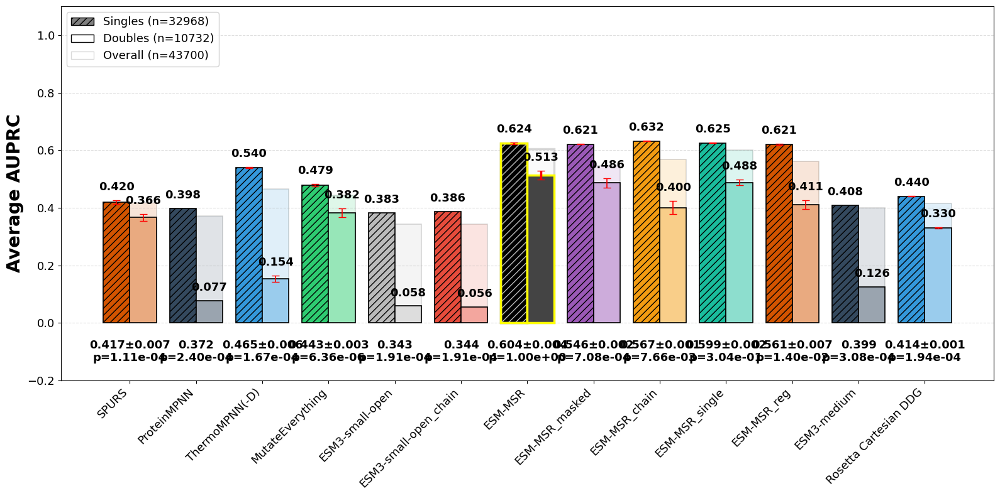

In [6]:
import analysis_utils_msr

analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_scores_cls.loc[('hyperopt_splits-S-test', 'ungrouped')], 
                                      series_bar2=df_scores_cls.loc[('hyperopt_splits-D-test', 'ungrouped')], 
                                      series_overall=df_scores_cls.loc[('hyperopt_splits-test', 'ungrouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_chain', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_chain', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], # 'ESM3-small','ESM3-large',
                                      title=None, y_label='Average AUPRC', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,1.1), figsize=(16,8), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left', is_grouped=False)

In [7]:
df_scores = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores = assess_all_models(df, df_scores, assess_grouped_spearman)

df_scores

ESM-MSR_1   ESM-MSR_1_n  ESM-MSR_1_groups  \
hyperopt_splits-S-test ungrouped   0.755461  32968.000000               NaN   
                       grouped     0.812046    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.367617  10732.000000               NaN   
                       grouped     0.799099   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.715575  43700.000000               NaN   
                       grouped     0.803615   1213.888889              36.0   

                                  ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-S-test ungrouped   0.765301  32968.000000               NaN   
                       grouped     0.813591    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.344472  10732.000000               NaN   
                       grouped     0.806849   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.713720  43700.000000               NaN   
                       grouped     0.805955   1213.888889              36.0   

                                  ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-S-test ungrouped   0.774775  32968.000000               NaN   
                       grouped     0.814873    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.380763  10732.000000               NaN   
                       grouped     0.806826   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.736382  43700.000000               NaN   
                       grouped     0.806365   1213.888889              36.0   

                                  ESM-MSR_alpha_med_1  ...  \
hyperopt_splits-S-test ungrouped             0.754444  ...   
                       grouped               0.783598  ...   
hyperopt_splits-D-test ungrouped             0.346260  ...   
                       grouped               0.727298  ...   
hyperopt_splits-test   ungrouped             0.739151  ...   
                       grouped               0.775102  ...   

                                  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-S-test ungrouped                             NaN   
                       grouped                              36.0   
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   
hyperopt_splits-test   ungrouped                             NaN   
                       grouped                              36.0   

                                  Rosetta Cartesian DDG_2  \
hyperopt_splits-S-test ungrouped                 0.621393   
                       grouped                   0.645911   
hyperopt_splits-D-test ungrouped                 0.481485   
                       grouped                   0.461834   
hyperopt_splits-test   ungrouped                 0.657570   
                       grouped                   0.634463   

                                  Rosetta Cartesian DDG_2_n  \
hyperopt_splits-S-test ungrouped               32968.000000   
                       grouped                   915.777778   
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   
hyperopt_splits-test   ungrouped               43700.000000   
                       grouped                  1213.888889   

                                  Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-S-test ungrouped                             NaN   
                       grouped                              36.0   
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   
hyperopt_splits-test   ungrouped                             NaN   
                       grouped                              36.0   

                                  Rosetta Cartesian DDG_3  \
hyperopt_splits-S-test ungrouped                 0.6

In [8]:
df_scores[[c for c in df_scores.columns if '_n' in c]].iloc[:,:15]

ESM-MSR_1_n   ESM-MSR_2_n   ESM-MSR_3_n  \
hyperopt_splits-S-test ungrouped  32968.000000  32968.000000  32968.000000   
                       grouped      915.777778    915.777778    915.777778   
hyperopt_splits-D-test ungrouped  10732.000000  10732.000000  10732.000000   
                       grouped     1533.142857   1533.142857   1533.142857   
hyperopt_splits-test   ungrouped  43700.000000  43700.000000  43700.000000   
                       grouped     1213.888889   1213.888889   1213.888889   

                                  ESM-MSR_alpha_med_1_n  \
hyperopt_splits-S-test ungrouped           32968.000000   
                       grouped               915.777778   
hyperopt_splits-D-test ungrouped           10732.000000   
                       grouped              1533.142857   
hyperopt_splits-test   ungrouped           43700.000000   
                       grouped              1213.888889   

                                  ESM-MSR_alpha_med_2_n  \
hyperopt_splits-S-test ungrouped           32968.000000   
                       grouped               915.777778   
hyperopt_splits-D-test ungrouped           10732.000000   
                       grouped              1533.142857   
hyperopt_splits-test   ungrouped           43700.000000   
                       grouped              1213.888889   

                                  ESM-MSR_alpha_med_3_n  \
hyperopt_splits-S-test ungrouped           32968.000000   
                       grouped               915.777778   
hyperopt_splits-D-test ungrouped           10732.000000   
                       grouped              1533.142857   
hyperopt_splits-test   ungrouped           43700.000000   
                       grouped              1213.888889   

                                  ESM-MSR_alpha_low_1_n  \
hyperopt_splits-S-test ungrouped           32968.000000   
                       grouped               915.777778   
hyperopt_splits-D-test ungrouped           10732.000000   
                       grouped              1533.142857   
hyperopt_splits-test   ungrouped           43700.000000   
                       grouped              1213.888889   

                                  ESM-MSR_alpha_low_2_n  \
hyperopt_splits-S-test ungrouped           32968.000000   
                       grouped               915.777778   
hyperopt_splits-D-test ungrouped           10732.000000   
                       grouped              1533.142857   
hyperopt_splits-test   ungrouped           43700.000000   
                       grouped              1213.888889   

                                  ESM-MSR_alpha_low_3_n  ESM-MSR_single_1_n  \
hyperopt_splits-S-test ungrouped           32968.000000        32968.000000   
                       grouped               915.777778          915.777778   
hyperopt_splits-D-test ungrouped           10732.000000        10732.000000   
                       grouped              1533.142857         1533.142857   
hyperopt_splits-test   ungrouped           43700.000000        43700.000000   
                       grouped              1213.888889         1213.888889   

                                  ESM-MSR_single_2_n  ESM-MSR_single_3_n  \
hyperopt_splits-S-test ungrouped        32968.000000        32968.000000   
                       grouped            915.777778          915.777778   
hyperopt_splits-D-test ungrouped        10732.000000        10732.000000   
                       grouped           1533.142857         1533.142857   
hyperopt_splits-test   ungrouped        43700.000000        43700.000000   
                       grouped           1213.888889         1213.888889   

                                  ESM-MSR_reg_1_n  ESM-MSR_reg_2_n  \
hyperopt_splits-S-test ungrouped     32968.000000     32968.000000   
                       grouped         915.777778       915.777778   
hyperopt_splits-D-test ungrouped     10732.000000     10732.000000   
                       grouped        1533.142857  

In [9]:
df_scores[[c for c in df_scores.columns if '_n' in c]].iloc[:,15:]

ESM-MSR_masked_1_n  ESM-MSR_masked_2_n  \
hyperopt_splits-S-test ungrouped        32968.000000        32968.000000   
                       grouped            915.777778          915.777778   
hyperopt_splits-D-test ungrouped        10732.000000        10732.000000   
                       grouped           1533.142857         1533.142857   
hyperopt_splits-test   ungrouped        43700.000000        43700.000000   
                       grouped           1213.888889         1213.888889   

                                  ESM-MSR_masked_3_n  ESM-MSR_chain_1_n  \
hyperopt_splits-S-test ungrouped        32968.000000       32968.000000   
                       grouped            915.777778         915.777778   
hyperopt_splits-D-test ungrouped        10732.000000       10732.000000   
                       grouped           1533.142857        1533.142857   
hyperopt_splits-test   ungrouped        43700.000000       43700.000000   
                       grouped           1213.888889        1213.888889   

                                  ESM-MSR_chain_2_n  ESM-MSR_chain_3_n  \
hyperopt_splits-S-test ungrouped       32968.000000       32968.000000   
                       grouped           915.777778         915.777778   
hyperopt_splits-D-test ungrouped       10732.000000       10732.000000   
                       grouped          1533.142857        1533.142857   
hyperopt_splits-test   ungrouped       43700.000000       43700.000000   
                       grouped          1213.888889        1213.888889   

                                     SPURS_1_n     SPURS_2_n     SPURS_3_n  \
hyperopt_splits-S-test ungrouped  32968.000000  32968.000000  32968.000000   
                       grouped      915.777778    915.777778    915.777778   
hyperopt_splits-D-test ungrouped  10732.000000  10732.000000  10732.000000   
                       grouped     1533.142857   1533.142857   1533.142857   
hyperopt_splits-test   ungrouped  43700.000000  43700.000000  43700.000000   
                       grouped     1213.888889   1213.888889   1213.888889   

                                  ThermoMPNN(-D)_1_n  ...  \
hyperopt_splits-S-test ungrouped        32968.000000  ...   
                       grouped            915.777778  ...   
hyperopt_splits-D-test ungrouped        10732.000000  ...   
                       grouped           1533.142857  ...   
hyperopt_splits-test   ungrouped        43700.000000  ...   
                       grouped           1213.888889  ...   

                                  MutateEverything_3_n  ESM3-small-open_n  \
hyperopt_splits-S-test ungrouped          32968.000000       32968.000000   
                       grouped              915.777778         915.777778   
hyperopt_splits-D-test ungrouped          10732.000000       10732.000000   
                       grouped             1533.142857        1533.142857   
hyperopt_splits-test   ungrouped          43700.000000       43700.000000   
                       grouped             1213.888889        1213.888889   

                                  ESM3-small-open_chain_n  ESM3-small_n  \
hyperopt_splits-S-test ungrouped             32968.000000  32968.000000   
                       grouped                 915.777778    915.777778   
hyperopt_splits-D-test ungrouped             10732.000000  10732.000000   
                       grouped                1533.142857   1533.142857   
hyperopt_splits-test   ungrouped             43700.000000  43700.000000   
                       grouped                1213.888889   1213.888889   

                                  ESM3-medium_n  ESM3-large_n  \
hyperopt_splits-S-test ungrouped   32968.000000  32968.000000   
                       grouped       915.777778    915.777778   
hyperopt_splits-D-test ungrouped   10732.000000  10732.000000   
                       grouped      1533.142857   1533.142857   
hyperopt_splits-test   ungrouped   43700.000000  43700.000000   
                       gr

In [10]:
df_scores[[c for c in df_scores.columns if not '_n' in c]].iloc[:,:15]

ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped   0.755461               NaN   0.765301   
                       grouped     0.812046              36.0   0.813591   
hyperopt_splits-D-test ungrouped   0.367617               NaN   0.344472   
                       grouped     0.799099               7.0   0.806849   
hyperopt_splits-test   ungrouped   0.715575               NaN   0.713720   
                       grouped     0.803615              36.0   0.805955   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN   0.774775   
                       grouped                36.0   0.814873   
hyperopt_splits-D-test ungrouped               NaN   0.380763   
                       grouped                 7.0   0.806826   
hyperopt_splits-test   ungrouped               NaN   0.736382   
                       grouped                36.0   0.806365   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN             0.754444   
                       grouped                36.0             0.783598   
hyperopt_splits-D-test ungrouped               NaN             0.346260   
                       grouped                 7.0             0.727298   
hyperopt_splits-test   ungrouped               NaN             0.739151   
                       grouped                36.0             0.775102   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped             0.759571   
                       grouped               0.789164   
hyperopt_splits-D-test ungrouped             0.348025   
                       grouped               0.732282   
hyperopt_splits-test   ungrouped             0.739249   
                       grouped               0.780570   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped             0.752522   
                       grouped               0.780909   
hyperopt_splits-D-test ungrouped             0.344550   
                       grouped               0.719671   
hyperopt_splits-test   ungrouped             0.737998   
                       grouped               0.772467   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped             0.736361   
                       grouped               0.801942   
hyperopt_splits-D-test ungrouped             0.355652   
                       grouped               0.789424   
hyperopt_splits-test   ungrouped             0.684816   
                       grouped

In [11]:
df_scores[[c for c in df_scores.columns if not '_n' in c]].iloc[:,15:]

ESM-MSR_alpha_low_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_3  \
hyperopt_splits-S-test ungrouped             0.761922   
                       grouped               0.806201   
hyperopt_splits-D-test ungrouped             0.340820   
                       grouped               0.796533   
hyperopt_splits-test   ungrouped             0.708539   
                       grouped               0.795812   

                                  ESM-MSR_alpha_low_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_single_1  ESM-MSR_single_1_groups  \
hyperopt_splits-S-test ungrouped          0.764079                      NaN   
                       grouped            0.812860                     36.0   
hyperopt_splits-D-test ungrouped          0.383233                      NaN   
                       grouped            0.791393                      7.0   
hyperopt_splits-test   ungrouped          0.723485                      NaN   
                       grouped            0.801578                     36.0   

                                  ESM-MSR_single_2  ESM-MSR_single_2_groups  \
hyperopt_splits-S-test ungrouped          0.763628                      NaN   
                       grouped            0.812314                     36.0   
hyperopt_splits-D-test ungrouped          0.382767                      NaN   
                       grouped            0.802892                      7.0   
hyperopt_splits-test   ungrouped          0.732909                      NaN   
                       grouped            0.802269                     36.0   

                                  ESM-MSR_single_3  ESM-MSR_single_3_groups  \
hyperopt_splits-S-test ungrouped          0.764995                      NaN   
                       grouped            0.811082                     36.0   
hyperopt_splits-D-test ungrouped          0.393018                      NaN   
                       grouped            0.814073                      7.0   
hyperopt_splits-test   ungrouped          0.736331                      NaN   
                       grouped            0.803208                     36.0   

                                  ESM-MSR_reg_1  ...  ESM3-large  \
hyperopt_splits-S-test ungrouped       0.778391  ...    0.538818   
                       grouped         0.810031  ...    0.555275   
hyperopt_splits-D-test ungrouped       0.395173  ...    0.459736   
                       grouped         0.801675  ...    0.401859   
hyperopt_splits-test   ungrouped       0.730832  ...    0.681085   
                       grouped         0.802059  ...    0.552881   

                                  ESM3-large_groups  Rosetta Cartesian DDG_1  \
hyperopt_splits-S-test ungrouped                NaN                 0.620096   
                       grouped                 36.0                 0.644948   
hyperopt_splits-D-test ungrouped                NaN                 0.482709   
                       grouped                  7.0                 0.472595   
hyperopt_splits-test   ungrouped                NaN                 0.657212   
                       grouped                 36.0                 0.633905   

                                  Ro

(<Figure size 1600x800 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

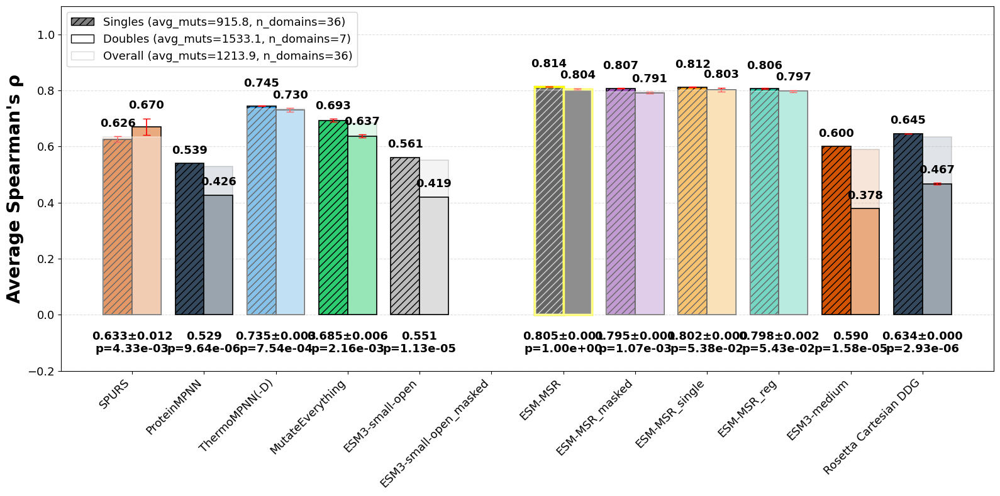

In [12]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_scores.loc[('hyperopt_splits-S-test', 'grouped')], 
                                      series_bar2=df_scores.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_scores.loc[('hyperopt_splits-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], # 'ESM3-small','ESM3-large',
                                      title=None, y_label='Average Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,1.1), figsize=(16,8), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left')

In [13]:
df_gain = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))
df_gain = assess_all_models(df, df_gain, assess_grouped_gain)
df_gain
df_gain[[c for c in df_gain.columns if not '_n' in c]].iloc[:,:15]

ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped  67.453423               NaN  62.698139   
                       grouped    24.744988              36.0  25.234329   
hyperopt_splits-D-test ungrouped  54.557159               NaN  56.971730   
                       grouped    17.929289               7.0  17.881766   
hyperopt_splits-test   ungrouped  73.696935               NaN  72.982431   
                       grouped    25.570964              36.0  25.900584   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN  80.878119   
                       grouped                36.0  25.237642   
hyperopt_splits-D-test ungrouped               NaN  55.043544   
                       grouped                 7.0  17.715548   
hyperopt_splits-test   ungrouped               NaN  86.464264   
                       grouped                36.0  25.820715   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN            71.911207   
                       grouped                36.0            21.688826   
hyperopt_splits-D-test ungrouped               NaN            45.709780   
                       grouped                 7.0            15.661989   
hyperopt_splits-test   ungrouped               NaN            75.952454   
                       grouped                36.0            22.171381   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped            71.908702   
                       grouped              22.096123   
hyperopt_splits-D-test ungrouped            48.211725   
                       grouped              15.912265   
hyperopt_splits-test   ungrouped            74.378807   
                       grouped              22.768392   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped            74.990857   
                       grouped              21.522285   
hyperopt_splits-D-test ungrouped            40.810974   
                       grouped              14.687552   
hyperopt_splits-test   ungrouped            75.604783   
                       grouped              22.112445   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped            57.225924   
                       grouped              24.280466   
hyperopt_splits-D-test ungrouped            49.881767   
                       grouped              17.023649   
hyperopt_splits-test   ungrouped            63.246479   
                       grouped

In [14]:
df_ndcg24 = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

# 1. Freeze the top_n argument into a new callable
assess_ndcg_24 = partial(assess_grouped_ndcg, top_n=24)

# 2. Pass the frozen function into your wrapper
df_ndcg24 = assess_all_models(df, df_ndcg24, assess_ndcg_24)

df_ndcg24
df_ndcg24[[c for c in df_ndcg24.columns if not '_n' in c]].iloc[:,:15]

ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped   0.457032               NaN   0.431926   
                       grouped     0.495423              36.0   0.511531   
hyperopt_splits-D-test ungrouped   0.646549               NaN   0.709104   
                       grouped     0.699972               7.0   0.691583   
hyperopt_splits-test   ungrouped   0.464433               NaN   0.433302   
                       grouped     0.490076              36.0   0.506345   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN   0.413257   
                       grouped                36.0   0.497990   
hyperopt_splits-D-test ungrouped               NaN   0.679287   
                       grouped                 7.0   0.737371   
hyperopt_splits-test   ungrouped               NaN   0.422471   
                       grouped                36.0   0.492715   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN             0.620760   
                       grouped                36.0             0.439027   
hyperopt_splits-D-test ungrouped               NaN             0.588931   
                       grouped                 7.0             0.551570   
hyperopt_splits-test   ungrouped               NaN             0.617655   
                       grouped                36.0             0.434778   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped             0.648574   
                       grouped               0.447968   
hyperopt_splits-D-test ungrouped             0.669768   
                       grouped               0.551502   
hyperopt_splits-test   ungrouped             0.645330   
                       grouped               0.443164   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped             0.653205   
                       grouped               0.437995   
hyperopt_splits-D-test ungrouped             0.506203   
                       grouped               0.507672   
hyperopt_splits-test   ungrouped             0.649939   
                       grouped               0.432441   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped             0.400258   
                       grouped               0.476307   
hyperopt_splits-D-test ungrouped             0.582439   
                       grouped               0.604225   
hyperopt_splits-test   ungrouped             0.420539   
                       grouped

(<Figure size 1600x800 with 1 Axes>, <Axes: ylabel='Average NDCG@k=24'>)

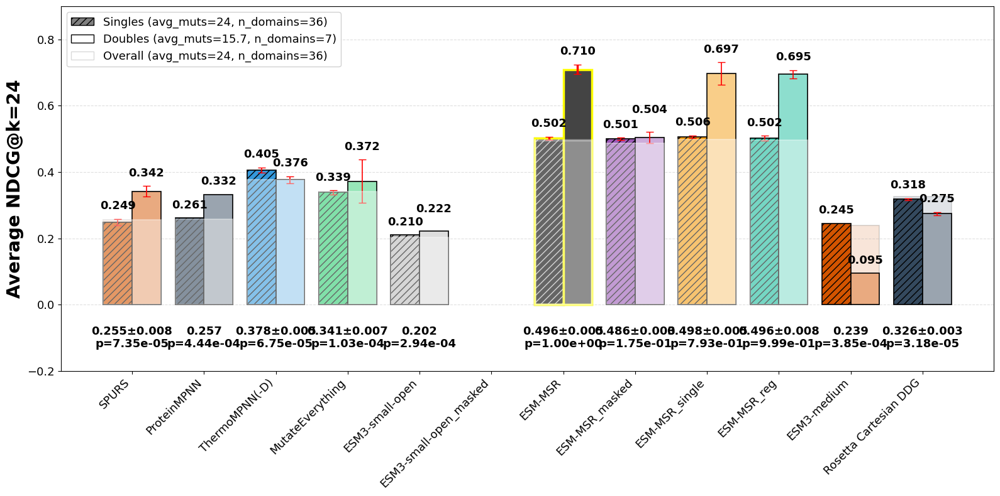

In [15]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_ndcg24.loc[('hyperopt_splits-S-test', 'grouped')], 
                                      series_bar2=df_ndcg24.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_ndcg24.loc[('hyperopt_splits-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], # 'ESM3-small','ESM3-large',
                                      title=None, y_label='Average NDCG@k=24', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,0.9), figsize=(16,8), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left')

In [16]:
df_ndcg96 = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

# 1. Freeze the top_n argument into a new callable
assess_ndcg_96 = partial(assess_grouped_ndcg, top_n=96)

# 2. Pass the frozen function into your wrapper
df_ndcg96 = assess_all_models(df, df_ndcg96, assess_ndcg_96)

df_ndcg96
df_ndcg96[[c for c in df_ndcg96.columns if not '_n' in c]].iloc[:,:15]

ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped   0.440718               NaN   0.411941   
                       grouped     0.546093              36.0   0.558810   
hyperopt_splits-D-test ungrouped   0.639321               NaN   0.676269   
                       grouped     0.757080               7.0   0.745434   
hyperopt_splits-test   ungrouped   0.465341               NaN   0.450764   
                       grouped     0.541560              36.0   0.553667   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN   0.486733   
                       grouped                36.0   0.545938   
hyperopt_splits-D-test ungrouped               NaN   0.655424   
                       grouped                 7.0   0.800180   
hyperopt_splits-test   ungrouped               NaN   0.504220   
                       grouped                36.0   0.539290   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN             0.516410   
                       grouped                36.0             0.478840   
hyperopt_splits-D-test ungrouped               NaN             0.575238   
                       grouped                 7.0             0.619872   
hyperopt_splits-test   ungrouped               NaN             0.526261   
                       grouped                36.0             0.472445   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped             0.527657   
                       grouped               0.491423   
hyperopt_splits-D-test ungrouped             0.599063   
                       grouped               0.616729   
hyperopt_splits-test   ungrouped             0.532201   
                       grouped               0.486392   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped             0.544036   
                       grouped               0.475826   
hyperopt_splits-D-test ungrouped             0.508386   
                       grouped               0.572115   
hyperopt_splits-test   ungrouped             0.537933   
                       grouped               0.470256   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped             0.377506   
                       grouped               0.535921   
hyperopt_splits-D-test ungrouped             0.585639   
                       grouped               0.672599   
hyperopt_splits-test   ungrouped             0.400085   
                       grouped

In [17]:
df_ndcg96[[c for c in df_ndcg96.columns if '_n' in c]].iloc[:,:15]

ESM-MSR_1_n  ESM-MSR_2_n  ESM-MSR_3_n  \
hyperopt_splits-S-test ungrouped    96.000000    96.000000    96.000000   
                       grouped      95.111111    95.111111    95.111111   
hyperopt_splits-D-test ungrouped    96.000000    96.000000    96.000000   
                       grouped      44.857143    44.857143    44.857143   
hyperopt_splits-test   ungrouped    96.000000    96.000000    96.000000   
                       grouped      95.111111    95.111111    95.111111   

                                  ESM-MSR_alpha_med_1_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                95.111111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                44.857143   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                95.111111   

                                  ESM-MSR_alpha_med_2_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                95.111111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                44.857143   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                95.111111   

                                  ESM-MSR_alpha_med_3_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                95.111111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                44.857143   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                95.111111   

                                  ESM-MSR_alpha_low_1_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                95.111111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                44.857143   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                95.111111   

                                  ESM-MSR_alpha_low_2_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                95.111111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                44.857143   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                95.111111   

                                  ESM-MSR_alpha_low_3_n  ESM-MSR_single_1_n  \
hyperopt_splits-S-test ungrouped              96.000000           96.000000   
                       grouped                95.111111           95.111111   
hyperopt_splits-D-test ungrouped              96.000000           96.000000   
                       grouped                44.857143           44.857143   
hyperopt_splits-test   ungrouped              96.000000           96.000000   
                       grouped                95.111111           95.111111   

                                  ESM-MSR_single_2_n  ESM-MSR_single_3_n  \
hyperopt_splits-S-test ungrouped           96.000000           96.000000   
                       grouped             95.111111           95.111111   
hyperopt_splits-D-test ungrouped           96.000000           96.000000   
                       grouped             44.857143           44.857143   
hyperopt_splits-test   ungrouped           96.000000           96.000000   
                       grouped             95.111111           95.111111   

                                  ESM-MSR_reg_1_n  ESM-MSR_reg_2_n  \
hyperopt_splits-S-test ungrouped        96.000000        96.000000   
                       grouped          95.111111        95.111111   
hyperopt_splits-D-test ungrouped        96.000000        96.000000   
                       grouped          44.857143        44.857143   
h

In [18]:
df_ndcg96_no_cys = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))
df_no_cys = df.loc[~df.index.str.endswith('C')]
df_ndcg96_no_cys = assess_all_models(df_no_cys, df_ndcg96_no_cys, assess_ndcg_96)
df_ndcg96_no_cys
df_ndcg96_no_cys[[c for c in df_ndcg96_no_cys.columns if not '_n' in c]].iloc[:,:15]

ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped   0.443611               NaN   0.432527   
                       grouped     0.565208              36.0   0.583271   
hyperopt_splits-D-test ungrouped   0.670227               NaN   0.693816   
                       grouped     0.800994               7.0   0.781761   
hyperopt_splits-test   ungrouped   0.469044               NaN   0.461801   
                       grouped     0.561254              36.0   0.578312   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN   0.500928   
                       grouped                36.0   0.562217   
hyperopt_splits-D-test ungrouped               NaN   0.675133   
                       grouped                 7.0   0.769931   
hyperopt_splits-test   ungrouped               NaN   0.517624   
                       grouped                36.0   0.556503   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN             0.520903   
                       grouped                36.0             0.487003   
hyperopt_splits-D-test ungrouped               NaN             0.612861   
                       grouped                 7.0             0.734563   
hyperopt_splits-test   ungrouped               NaN             0.531124   
                       grouped                36.0             0.482144   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped             0.536963   
                       grouped               0.500478   
hyperopt_splits-D-test ungrouped             0.630325   
                       grouped               0.731428   
hyperopt_splits-test   ungrouped             0.541407   
                       grouped               0.495871   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped             0.550798   
                       grouped               0.483880   
hyperopt_splits-D-test ungrouped             0.532963   
                       grouped               0.677190   
hyperopt_splits-test   ungrouped             0.546308   
                       grouped               0.478183   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped             0.396475   
                       grouped               0.569326   
hyperopt_splits-D-test ungrouped             0.618668   
                       grouped               0.701027   
hyperopt_splits-test   ungrouped             0.411868   
                       grouped

In [19]:
df_ndcg96_no_cys[[c for c in df_ndcg96_no_cys.columns if '_n' in c]].iloc[:,:15]

ESM-MSR_1_n  ESM-MSR_2_n  ESM-MSR_3_n  \
hyperopt_splits-S-test ungrouped    96.000000    96.000000    96.000000   
                       grouped      94.611111    94.611111    94.611111   
hyperopt_splits-D-test ungrouped    96.000000    96.000000    96.000000   
                       grouped      42.142857    42.142857    42.142857   
hyperopt_splits-test   ungrouped    96.000000    96.000000    96.000000   
                       grouped      94.611111    94.611111    94.611111   

                                  ESM-MSR_alpha_med_1_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                94.611111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                42.142857   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                94.611111   

                                  ESM-MSR_alpha_med_2_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                94.611111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                42.142857   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                94.611111   

                                  ESM-MSR_alpha_med_3_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                94.611111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                42.142857   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                94.611111   

                                  ESM-MSR_alpha_low_1_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                94.611111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                42.142857   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                94.611111   

                                  ESM-MSR_alpha_low_2_n  \
hyperopt_splits-S-test ungrouped              96.000000   
                       grouped                94.611111   
hyperopt_splits-D-test ungrouped              96.000000   
                       grouped                42.142857   
hyperopt_splits-test   ungrouped              96.000000   
                       grouped                94.611111   

                                  ESM-MSR_alpha_low_3_n  ESM-MSR_single_1_n  \
hyperopt_splits-S-test ungrouped              96.000000           96.000000   
                       grouped                94.611111           94.611111   
hyperopt_splits-D-test ungrouped              96.000000           96.000000   
                       grouped                42.142857           42.142857   
hyperopt_splits-test   ungrouped              96.000000           96.000000   
                       grouped                94.611111           94.611111   

                                  ESM-MSR_single_2_n  ESM-MSR_single_3_n  \
hyperopt_splits-S-test ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   
hyperopt_splits-D-test ungrouped           96.000000           96.000000   
                       grouped             42.142857           42.142857   
hyperopt_splits-test   ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   

                                  ESM-MSR_reg_1_n  ESM-MSR_reg_2_n  \
hyperopt_splits-S-test ungrouped        96.000000        96.000000   
                       grouped          94.611111        94.611111   
hyperopt_splits-D-test ungrouped        96.000000        96.000000   
                       grouped          42.142857        42.142857   
h

In [20]:
df_ndcg96_no_cys[[c for c in df_ndcg96_no_cys.columns if '_group' in c]].iloc[:,:15]

ESM-MSR_1_groups  ESM-MSR_2_groups  \
hyperopt_splits-S-test ungrouped               NaN               NaN   
                       grouped                36.0              36.0   
hyperopt_splits-D-test ungrouped               NaN               NaN   
                       grouped                 7.0               7.0   
hyperopt_splits-test   ungrouped               NaN               NaN   
                       grouped                36.0              36.0   

                                  ESM-MSR_3_groups  \
hyperopt_splits-S-test ungrouped               NaN   
                       grouped                36.0   
hyperopt_splits-D-test ungrouped               NaN   
                       grouped                 7.0   
hyperopt_splits-test   ungrouped               NaN   
                       grouped                36.0   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_single_1_groups  \
hyperopt_splits-S-test ungrouped                      NaN   
                       grouped                       36.0   
hyperopt_splits-D-test ungrouped                      NaN   
                       grouped                        7.0   
hyperopt_splits-test   ungrouped                      NaN   
                       grouped                       36.0   

                            

In [21]:
df_ndcg96_no_cys[[c for c in df_ndcg96_no_cys.columns if '_n' in c]].iloc[:,15:30]

ESM-MSR_masked_1_n  ESM-MSR_masked_2_n  \
hyperopt_splits-S-test ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   
hyperopt_splits-D-test ungrouped           96.000000           96.000000   
                       grouped             42.142857           42.142857   
hyperopt_splits-test   ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   

                                  ESM-MSR_masked_3_n  ESM-MSR_chain_1_n  \
hyperopt_splits-S-test ungrouped           96.000000          96.000000   
                       grouped             94.611111          94.611111   
hyperopt_splits-D-test ungrouped           96.000000          96.000000   
                       grouped             42.142857          42.142857   
hyperopt_splits-test   ungrouped           96.000000          96.000000   
                       grouped             94.611111          94.611111   

                                  ESM-MSR_chain_2_n  ESM-MSR_chain_3_n  \
hyperopt_splits-S-test ungrouped          96.000000          96.000000   
                       grouped            94.611111          94.611111   
hyperopt_splits-D-test ungrouped          96.000000          96.000000   
                       grouped            42.142857          42.142857   
hyperopt_splits-test   ungrouped          96.000000          96.000000   
                       grouped            94.611111          94.611111   

                                  SPURS_1_n  SPURS_2_n  SPURS_3_n  \
hyperopt_splits-S-test ungrouped  96.000000  96.000000  96.000000   
                       grouped    94.611111  94.611111  94.611111   
hyperopt_splits-D-test ungrouped  96.000000  96.000000  96.000000   
                       grouped    42.142857  42.142857  42.142857   
hyperopt_splits-test   ungrouped  96.000000  96.000000  96.000000   
                       grouped    94.611111  94.611111  94.611111   

                                  ThermoMPNN(-D)_1_n  ThermoMPNN(-D)_2_n  \
hyperopt_splits-S-test ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   
hyperopt_splits-D-test ungrouped           96.000000           96.000000   
                       grouped             42.142857           42.142857   
hyperopt_splits-test   ungrouped           96.000000           96.000000   
                       grouped             94.611111           94.611111   

                                  ThermoMPNN(-D)_3_n  MutateEverything_1_n  \
hyperopt_splits-S-test ungrouped           96.000000             96.000000   
                       grouped             94.611111             94.611111   
hyperopt_splits-D-test ungrouped           96.000000             96.000000   
                       grouped             42.142857             42.142857   
hyperopt_splits-test   ungrouped           96.000000             96.000000   
                       grouped             94.611111             94.611111   

                                  MutateEverything_2_n  MutateEverything_3_n  
hyperopt_splits-S-test ungrouped             96.000000             96.000000  
                       grouped               94.611111             94.611111  
hyperopt_splits-D-test ungrouped             96.000000             96.000000  
                       grouped               42.142857             42.142857  
hyperopt_splits-test   ungrouped             96.000000             96.000000  
                       grouped               94.611111             94.611111

(<Figure size 1600x800 with 1 Axes>, <Axes: ylabel='Average NDCG@k=96'>)

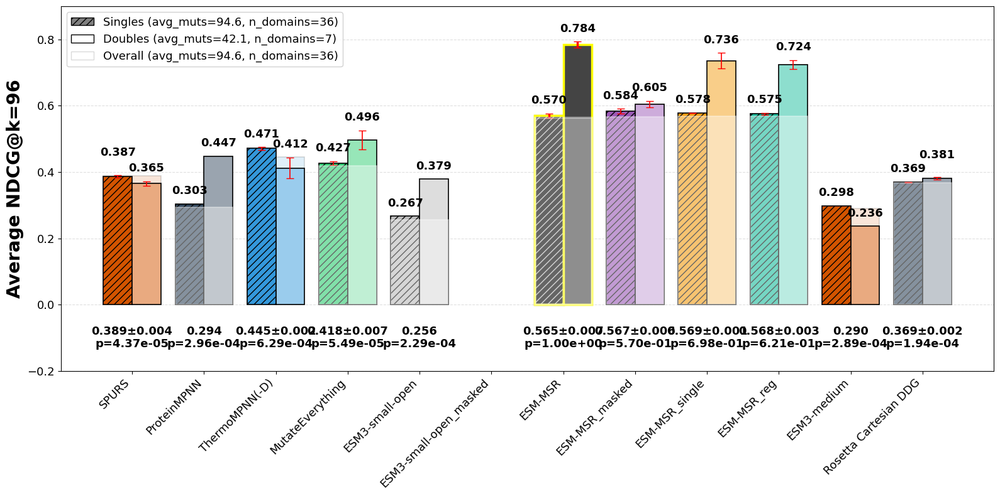

In [142]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)

analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_ndcg96_no_cys.loc[('hyperopt_splits-S-test', 'grouped')], 
                                      series_bar2=df_ndcg96_no_cys.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_ndcg96_no_cys.loc[('hyperopt_splits-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], # 'ESM3-small','ESM3-large',
                                      title=None, y_label='Average NDCG@k=96', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,0.9), figsize=(16,8), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left')

(<Figure size 1000x600 with 1 Axes>, <Axes: ylabel='Average NDCG@k=96'>)

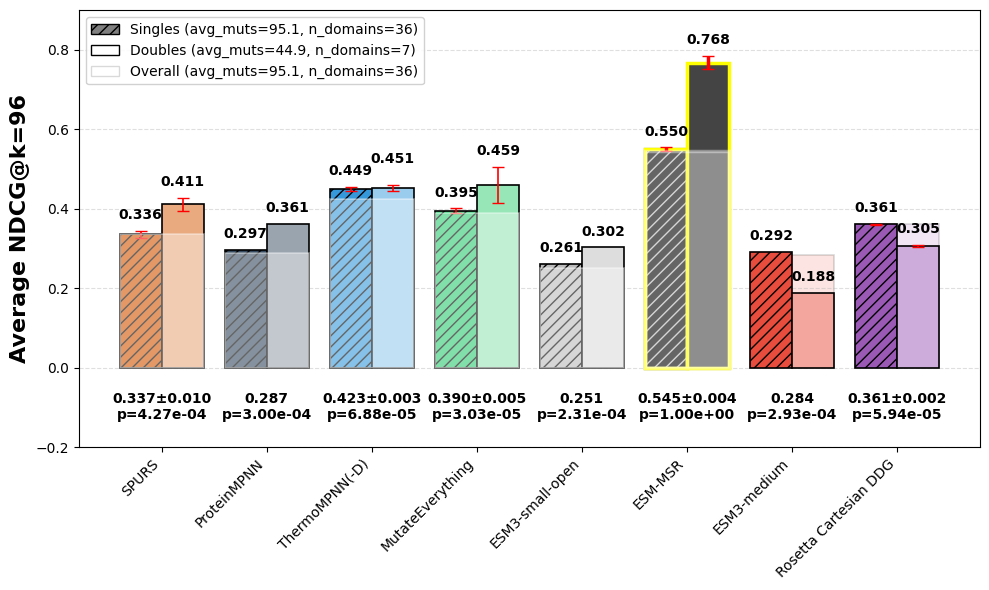

In [149]:
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_ndcg96.loc[('hyperopt_splits-S-test', 'grouped')], 
                                      series_bar2=df_ndcg96.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_ndcg96.loc[('hyperopt_splits-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large',
                                      title=None, y_label='Average NDCG@k=96', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,0.9), figsize=(10,6), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1., legend_loc='upper left')

In [24]:
df_ndcg_pos = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-S-test', 'hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

# 1. Freeze the top_n argument into a new callable
assess_ndcg_pos = partial(assess_grouped_ndcg, threshold=0)

# 2. Pass the frozen function into your wrapper
df_ndcg_pos = assess_all_models(df, df_ndcg_pos, assess_ndcg_pos)

df_ndcg_pos
df_ndcg_pos[[c for c in df_ndcg_pos.columns if not '_n' in c]].iloc[:,:15]


ESM-MSR_1  ESM-MSR_1_groups  ESM-MSR_2  \
hyperopt_splits-S-test ungrouped   0.844091               NaN   0.844208   
                       grouped     0.766177              36.0   0.772786   
hyperopt_splits-D-test ungrouped   0.812209               NaN   0.825618   
                       grouped     0.806212               7.0   0.798294   
hyperopt_splits-test   ungrouped   0.847743               NaN   0.847580   
                       grouped     0.764134              36.0   0.771503   

                                  ESM-MSR_2_groups  ESM-MSR_3  \
hyperopt_splits-S-test ungrouped               NaN   0.851208   
                       grouped                36.0   0.764780   
hyperopt_splits-D-test ungrouped               NaN   0.801869   
                       grouped                 7.0   0.859036   
hyperopt_splits-test   ungrouped               NaN   0.853131   
                       grouped                36.0   0.762634   

                                  ESM-MSR_3_groups  ESM-MSR_alpha_med_1  \
hyperopt_splits-S-test ungrouped               NaN             0.840553   
                       grouped                36.0             0.734259   
hyperopt_splits-D-test ungrouped               NaN             0.779506   
                       grouped                 7.0             0.701023   
hyperopt_splits-test   ungrouped               NaN             0.841166   
                       grouped                36.0             0.733039   

                                  ESM-MSR_alpha_med_1_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_2  \
hyperopt_splits-S-test ungrouped             0.846499   
                       grouped               0.741065   
hyperopt_splits-D-test ungrouped             0.783174   
                       grouped               0.697968   
hyperopt_splits-test   ungrouped             0.847299   
                       grouped               0.739705   

                                  ESM-MSR_alpha_med_2_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_med_3  \
hyperopt_splits-S-test ungrouped             0.843102   
                       grouped               0.732189   
hyperopt_splits-D-test ungrouped             0.745446   
                       grouped               0.673213   
hyperopt_splits-test   ungrouped             0.841884   
                       grouped               0.730518   

                                  ESM-MSR_alpha_med_3_groups  \
hyperopt_splits-S-test ungrouped                         NaN   
                       grouped                          36.0   
hyperopt_splits-D-test ungrouped                         NaN   
                       grouped                           7.0   
hyperopt_splits-test   ungrouped                         NaN   
                       grouped                          36.0   

                                  ESM-MSR_alpha_low_1  \
hyperopt_splits-S-test ungrouped             0.834711   
                       grouped               0.759553   
hyperopt_splits-D-test ungrouped             0.798128   
                       grouped               0.738887   
hyperopt_splits-test   ungrouped             0.837286   
                       grouped

(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel='Average NDCG'>)

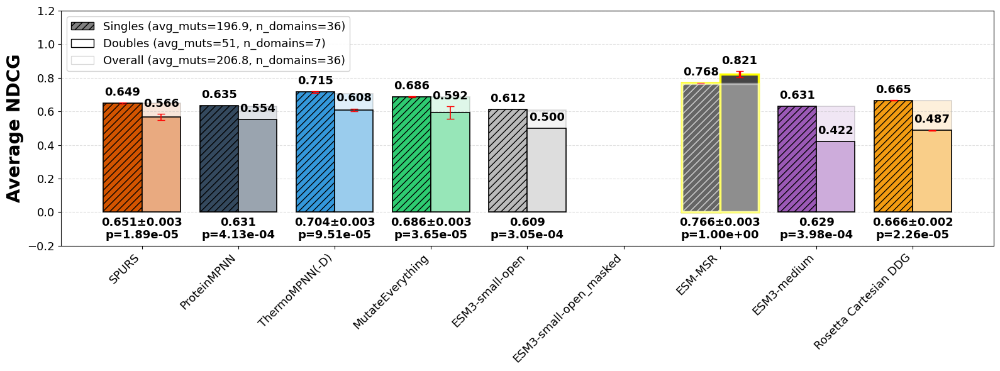

In [25]:
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_ndcg_pos.loc[('hyperopt_splits-S-test', 'grouped')], 
                                      series_bar2=df_ndcg_pos.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_ndcg_pos.loc[('hyperopt_splits-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR',  'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg',
                                      title=None, y_label='Average NDCG', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.2,1.2), figsize=(16,6), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left')

In [26]:
# add additive scores
# should be 556 mutants missing
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)
#from analysis_utils_msr import sum_individual_mutation_scores

#cols = df.columns.drop('code').drop('mut_type')
#cols = ['Rosetta Cartesian DDG_1', 'Rosetta Cartesian DDG_2', 'Rosetta Cartesian DDG_3', 'ddG_ML_me']
cols = ['ddG']
df_epistatic = df.copy(deep=True)

#print(len(df.loc[df['mut_type'].str.contains(':')]))
for c in cols:
    if not c.endswith('_n'):
        print(c)
        # synthesize additive mutation predictions and scores
        df_epistatic = sum_individual_mutation_scores(df_epistatic, c, new_score_column=None) #, df_missing, missing1, missing2

#df_epistatic = df_epistatic[[c for c in df_epistatic.columns if 'additive' in c] + ['code', 'ddG', 'mut_type']]
df_epistatic = df_epistatic[[c for c in df_epistatic.columns if not c.endswith('_n')]]
df_epistatic = df_epistatic.dropna(subset='ESM-MSR_1')
#df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN(-D)_1_additive'] = df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN_1']
#df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN(-D)_2_additive'] = df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN_2']
#df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN(-D)_3_additive'] = df_epistatic.loc[df_epistatic.index.str.contains(':'), 'ThermoMPNN_3']

#print(len(df_epistatic))
#df_epistatic['ThermoMPNN(-D)_1_additive'].dropna()

ddG


In [27]:
# Get all grouped and ungrouped ranking correlations for epistatic / combined mutants

df_scores_epistatic = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

assess_all_models(df_epistatic.loc[df_epistatic['mut_type'].str.contains(':')], df_scores_epistatic, assess_grouped_spearman, splits=['hyperopt_splits-D-test'])

df_scores_epistatic

ESM-MSR_1   ESM-MSR_1_n  ESM-MSR_1_groups  \
hyperopt_splits-D-test ungrouped   0.367617  10732.000000               NaN   
                       grouped     0.799099   1533.142857               7.0   

                                  ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-D-test ungrouped   0.344472  10732.000000               NaN   
                       grouped     0.806849   1533.142857               7.0   

                                  ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-D-test ungrouped   0.380763  10732.000000               NaN   
                       grouped     0.806826   1533.142857               7.0   

                                  ESM-MSR_alpha_med_1  ...  \
hyperopt_splits-D-test ungrouped             0.346260  ...   
                       grouped               0.727298  ...   

                                  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   

                                  Rosetta Cartesian DDG_2  \
hyperopt_splits-D-test ungrouped                 0.481485   
                       grouped                   0.461834   

                                  Rosetta Cartesian DDG_2_n  \
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   

                                  Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   

                                  Rosetta Cartesian DDG_3  \
hyperopt_splits-D-test ungrouped                 0.481839   
                       grouped                   0.466217   

                                  Rosetta Cartesian DDG_3_n  \
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   

                                  Rosetta Cartesian DDG_3_groups  ProteinMPNN  \
hyperopt_splits-D-test ungrouped                             NaN     0.211427   
                       grouped                               7.0     0.426416   

                                  ProteinMPNN_n  ProteinMPNN_groups  
hyperopt_splits-D-test ungrouped   10732.000000                 NaN  
                       grouped      1533.142857                 7.0  

[2 rows x 117 columns]

In [28]:
assess_all_models(df_epistatic.loc[df_epistatic['mut_type'].str.contains(':')], df_scores_epistatic, assess_grouped_spearman, splits=['hyperopt_splits-D-test'], add_suffix='_additive')
df_scores_epistatic = assess_grouped_spearman(df_epistatic.loc[df_epistatic['mut_type'].str.contains(':')], df_scores_epistatic, 'Negative_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG')

df_scores_epistatic

ESM-MSR_1   ESM-MSR_1_n  ESM-MSR_1_groups  \
hyperopt_splits-D-test ungrouped   0.367617  10732.000000               NaN   
                       grouped     0.799099   1533.142857               7.0   

                                  ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-D-test ungrouped   0.344472  10732.000000               NaN   
                       grouped     0.806849   1533.142857               7.0   

                                  ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-D-test ungrouped   0.380763  10732.000000               NaN   
                       grouped     0.806826   1533.142857               7.0   

                                  ESM-MSR_alpha_med_1  ...  \
hyperopt_splits-D-test ungrouped             0.346260  ...   
                       grouped               0.727298  ...   

                                  Rosetta Cartesian DDG_additive_2_groups  \
hyperopt_splits-D-test ungrouped                                      NaN   
                       grouped                                        7.0   

                                  Rosetta Cartesian DDG_additive_3  \
hyperopt_splits-D-test ungrouped                          0.393372   
                       grouped                            0.372765   

                                  Rosetta Cartesian DDG_additive_3_n  \
hyperopt_splits-D-test ungrouped                        10699.000000   
                       grouped                           1528.428571   

                                  Rosetta Cartesian DDG_additive_3_groups  \
hyperopt_splits-D-test ungrouped                                      NaN   
                       grouped                                        7.0   

                                  ProteinMPNN_additive  \
hyperopt_splits-D-test ungrouped              0.130812   
                       grouped                0.377328   

                                  ProteinMPNN_additive_n  \
hyperopt_splits-D-test ungrouped            10732.000000   
                       grouped               1533.142857   

                                  ProteinMPNN_additive_groups  \
hyperopt_splits-D-test ungrouped                          NaN   
                       grouped                            7.0   

                                  Negative_additive  Negative_additive_n  \
hyperopt_splits-D-test ungrouped           0.730326         10176.000000   
                       grouped             0.784848          1453.714286   

                                  Negative_additive_groups  
hyperopt_splits-D-test ungrouped                       NaN  
                       grouped                         7.0  

[2 rows x 237 columns]

In [29]:
# Peek at the additive correlations

df_scores_additive_2 = df_scores_epistatic[[c for c in df_scores_epistatic.columns if c.endswith('_additive')]]#.dropna()
df_scores_additive_2.columns = [c[:-9] for c in df_scores_additive_2.columns]
df_scores_additive_2

ESM3-small-open  ESM3-small-open_chain  \
hyperopt_splits-D-test ungrouped         0.065987               0.051884   
                       grouped           0.355787               0.365291   

                                  ESM3-small  ESM3-medium  ESM3-large  \
hyperopt_splits-D-test ungrouped    0.115948     0.357528    0.396180   
                       grouped      0.397451     0.339708    0.319223   

                                  ProteinMPNN  Negative  
hyperopt_splits-D-test ungrouped     0.130812  0.730326  
                       grouped       0.377328  0.784848

In [30]:
# compress replicates into mean and stdev
df_scores_std_2 = unify_similar_columns(df_scores_additive_2)
df_scores_std_2

ESM3-small-open  ESM3-small-open_chain  \
hyperopt_splits-D-test ungrouped         0.065987               0.051884   
                       grouped           0.355787               0.365291   

                                  ESM3-small  ESM3-medium  ESM3-large  \
hyperopt_splits-D-test ungrouped    0.115948     0.357528    0.396180   
                       grouped      0.397451     0.339708    0.319223   

                                  ProteinMPNN  Negative  
hyperopt_splits-D-test ungrouped     0.130812  0.730326  
                       grouped       0.377328  0.784848

In [129]:
df_scores_epistatic[[c for c in df_scores_epistatic if 'Rosetta' in c]]

Rosetta Cartesian DDG_1  \
hyperopt_splits-D-test ungrouped                 0.482709   
                       grouped                   0.472595   

                                  Rosetta Cartesian DDG_1_n  \
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   

                                  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   

                                  Rosetta Cartesian DDG_2  \
hyperopt_splits-D-test ungrouped                 0.481485   
                       grouped                   0.461834   

                                  Rosetta Cartesian DDG_2_n  \
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   

                                  Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   

                                  Rosetta Cartesian DDG_3  \
hyperopt_splits-D-test ungrouped                 0.481839   
                       grouped                   0.466217   

                                  Rosetta Cartesian DDG_3_n  \
hyperopt_splits-D-test ungrouped               10732.000000   
                       grouped                  1533.142857   

                                  Rosetta Cartesian DDG_3_groups  \
hyperopt_splits-D-test ungrouped                             NaN   
                       grouped                               7.0   

                                  Rosetta Cartesian DDG_additive_1  \
hyperopt_splits-D-test ungrouped                          0.389469   
                       grouped                            0.364759   

                                  Rosetta Cartesian DDG_additive_1_n  \
hyperopt_splits-D-test ungrouped                        10699.000000   
                       grouped                           1528.428571   

                                  Rosetta Cartesian DDG_additive_1_groups  \
hyperopt_splits-D-test ungrouped                                      NaN   
                       grouped                                        7.0   

                                  Rosetta Cartesian DDG_additive_2  \
hyperopt_splits-D-test ungrouped                          0.389130   
                       grouped                            0.349701   

                                  Rosetta Cartesian DDG_additive_2_n  \
hyperopt_splits-D-test ungrouped                        10699.000000   
                       grouped                           1528.428571   

                                  Rosetta Cartesian DDG_additive_2_groups  \
hyperopt_splits-D-test ungrouped                                      NaN   
                       grouped                                        7.0   

                                  Rosetta Cartesian DDG_additive_3  \
hyperopt_splits-D-test ungrouped                          0.393372   
                       grouped                            0.372765   

                                  Rosetta Cartesian DDG_additive_3_n  \
hyperopt_splits-D-test ungrouped                        10699.000000   
                       grouped                           1528.428571   

                                  Rosetta Cartesian DDG_additive_3_groups  
hyperopt_splits-D-test ungrouped                                      NaN  
                       grouped                                        7.0

(<Figure size 1000x600 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

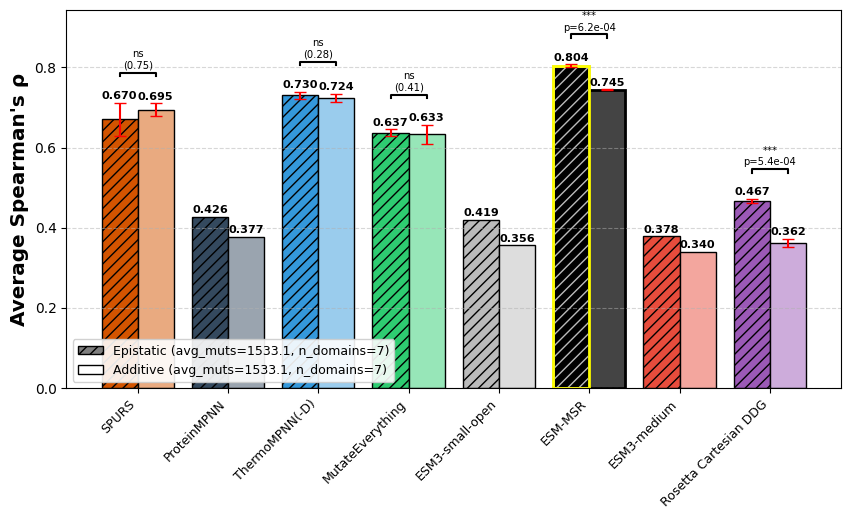

In [148]:
# For ~52,000 testing doubles, compare additive approximation to original (combined/epistatic) prediction (grouped by structure, then take mean)
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr)
analysis_utils_msr.create_metric_comparison_chart_epistatic(df_scores_epistatic.loc[('hyperopt_splits-D-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], highlighted_model='ESM-MSR', title=None, y_label='Average Spearman\'s ρ', figsize=(10,6), bracket_height_factor=0.05, fontsize_multiplier=.9, legend_loc='lower left') # 'ESM3-small-open_masked','ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM-MSR_hybrid',

(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel="Pooled Spearman's ρ">)

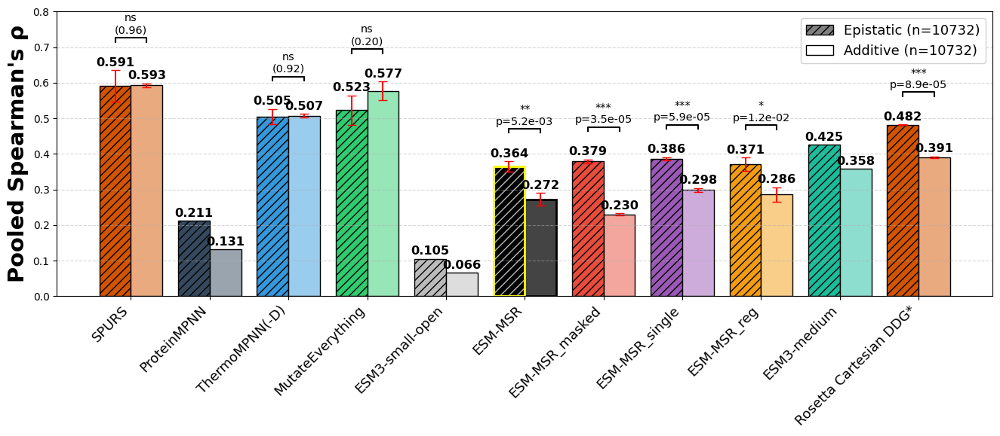

In [32]:
# For ~52,000 testing doubles, compare additive approximation to original (combined/epistatic) prediction (pool all predictions together)

analysis_utils_msr.create_metric_comparison_chart_epistatic(df_scores_epistatic.loc[('hyperopt_splits-D-test', 'ungrouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], highlighted_model='ESM-MSR', title=None, y_label='Pooled Spearman\'s ρ', figsize=(16,6), is_grouped=False) #'Grouped Performance Comparison on Doubles from Feb19_Tsuboyama Test Set'

In [33]:
# repeat analysis for specifically only stabilizing or destabilizing mutations

df_pos = df.loc[df['ddG']>0]

df_scores_pos = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))
df_scores_pos_doubles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_pos = assess_all_models(df_pos, df_scores_pos, assess_grouped_spearman, splits=['hyperopt_splits-test'])
df_scores_pos_doubles = assess_all_models(df_pos, df_scores_pos_doubles, assess_grouped_spearman, splits=['hyperopt_splits-D-test'])

df_neg = df.loc[df['ddG']<=0]

df_scores_neg = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))
df_scores_neg_doubles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_neg = assess_all_models(df_neg, df_scores_neg, assess_grouped_spearman, splits=['hyperopt_splits-test'])
df_scores_neg_doubles = assess_all_models(df_neg, df_scores_neg_doubles, assess_grouped_spearman, splits=['hyperopt_splits-D-test'])

df_scores_combined = df_scores.join(df_scores_pos, rsuffix='_pos').join(df_scores_neg, rsuffix='_neg')
df_scores_combined

df_scores_combined_doubles = df_scores.join(df_scores_pos_doubles, rsuffix='_pos').join(df_scores_neg_doubles, rsuffix='_neg')
df_scores_combined_doubles

ESM-MSR_1   ESM-MSR_1_n  ESM-MSR_1_groups  \
hyperopt_splits-S-test ungrouped   0.755461  32968.000000               NaN   
                       grouped     0.812046    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.367617  10732.000000               NaN   
                       grouped     0.799099   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.715575  43700.000000               NaN   
                       grouped     0.803615   1213.888889              36.0   

                                  ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-S-test ungrouped   0.765301  32968.000000               NaN   
                       grouped     0.813591    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.344472  10732.000000               NaN   
                       grouped     0.806849   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.713720  43700.000000               NaN   
                       grouped     0.805955   1213.888889              36.0   

                                  ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-S-test ungrouped   0.774775  32968.000000               NaN   
                       grouped     0.814873    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.380763  10732.000000               NaN   
                       grouped     0.806826   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.736382  43700.000000               NaN   
                       grouped     0.806365   1213.888889              36.0   

                                  ESM-MSR_alpha_med_1  ...  \
hyperopt_splits-S-test ungrouped             0.754444  ...   
                       grouped               0.783598  ...   
hyperopt_splits-D-test ungrouped             0.346260  ...   
                       grouped               0.727298  ...   
hyperopt_splits-test   ungrouped             0.739151  ...   
                       grouped               0.775102  ...   

                                  Rosetta Cartesian DDG_1_groups_neg  \
hyperopt_splits-S-test ungrouped                                 NaN   
                       grouped                                   NaN   
hyperopt_splits-D-test ungrouped                                 NaN   
                       grouped                                   7.0   
hyperopt_splits-test   ungrouped                                 NaN   
                       grouped                                   NaN   

                                  Rosetta Cartesian DDG_2_neg  \
hyperopt_splits-S-test ungrouped                          NaN   
                       grouped                            NaN   
hyperopt_splits-D-test ungrouped                     0.448837   
                       grouped                       0.447347   
hyperopt_splits-test   ungrouped                          NaN   
                       grouped                            NaN   

                                  Rosetta Cartesian DDG_2_n_neg  \
hyperopt_splits-S-test ungrouped                            NaN   
                       grouped                              NaN   
hyperopt_splits-D-test ungrouped                   10375.000000   
                       grouped                      1482.142857   
hyperopt_splits-test   ungrouped                            NaN   
                       grouped                              NaN   

                                  Rosetta Cartesian DDG_2_groups_neg  \
hyperopt_splits-S-test ungrouped                                 NaN   
                       grouped                                   NaN   
hyperopt_splits-D-test ungrouped                                 NaN   
                       grouped                                   7.0   
hyperopt_splits-test   ungrouped                                 NaN   
                       grouped                                   NaN   

 

In [34]:
df_scores_combined[[c for c in df_scores_combined.columns if ('SPURS' in c and '_group' in c)]]

SPURS_1_groups  SPURS_2_groups  \
hyperopt_splits-S-test ungrouped             NaN             NaN   
                       grouped              36.0            36.0   
hyperopt_splits-D-test ungrouped             NaN             NaN   
                       grouped               7.0             7.0   
hyperopt_splits-test   ungrouped             NaN             NaN   
                       grouped              36.0            36.0   

                                  SPURS_3_groups  SPURS_1_groups_pos  \
hyperopt_splits-S-test ungrouped             NaN                 NaN   
                       grouped              36.0                 NaN   
hyperopt_splits-D-test ungrouped             NaN                 NaN   
                       grouped               7.0                 NaN   
hyperopt_splits-test   ungrouped             NaN                 NaN   
                       grouped              36.0                36.0   

                                  SPURS_2_groups_pos  SPURS_3_groups_pos  \
hyperopt_splits-S-test ungrouped                 NaN                 NaN   
                       grouped                   NaN                 NaN   
hyperopt_splits-D-test ungrouped                 NaN                 NaN   
                       grouped                   NaN                 NaN   
hyperopt_splits-test   ungrouped                 NaN                 NaN   
                       grouped                  36.0                36.0   

                                  SPURS_1_groups_neg  SPURS_2_groups_neg  \
hyperopt_splits-S-test ungrouped                 NaN                 NaN   
                       grouped                   NaN                 NaN   
hyperopt_splits-D-test ungrouped                 NaN                 NaN   
                       grouped                   NaN                 NaN   
hyperopt_splits-test   ungrouped                 NaN                 NaN   
                       grouped                  36.0                36.0   

                                  SPURS_3_groups_neg  
hyperopt_splits-S-test ungrouped                 NaN  
                       grouped                   NaN  
hyperopt_splits-D-test ungrouped                 NaN  
                       grouped                   NaN  
hyperopt_splits-test   ungrouped                 NaN  
                       grouped                  36.0

(<Figure size 1000x600 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

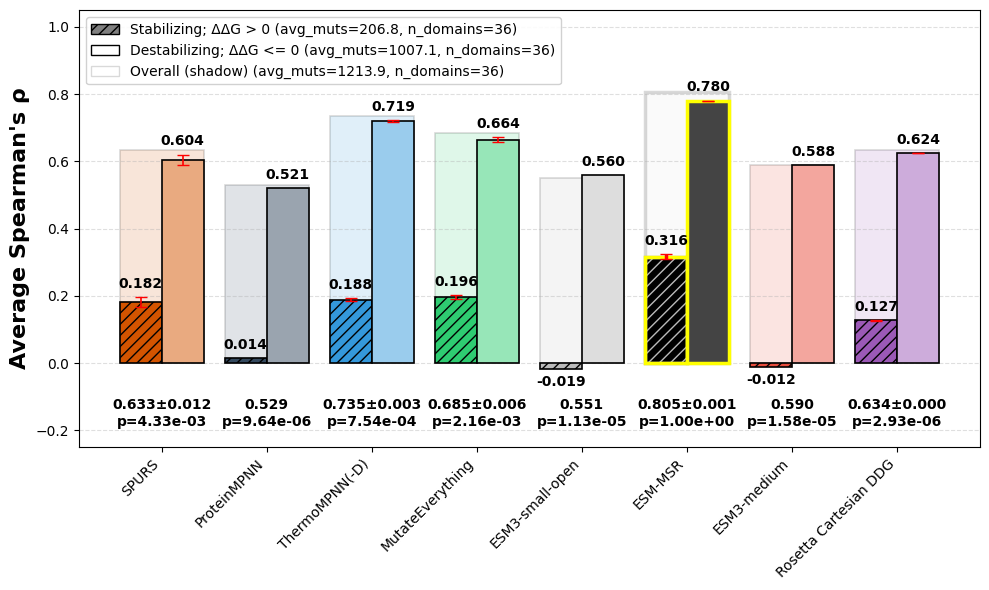

In [150]:
import analysis_utils_msr
import importlib
importlib.reload(analysis_utils_msr) 

analysis_utils_msr.create_pos_neg_overall_chart(
    df_scores_combined.loc[('hyperopt_splits-test', 'grouped')], 
    ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], p_value_y_coord=-0.15,
    title=None, y_label='Average Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=True, epistasis=False, figsize=(10,6), ylim=(-0.25, 1.05), legend_loc='upper left', fontsize_multiplier=1.) #'ESM-MSR_direct',

(<Figure size 1400x600 with 1 Axes>, <Axes: ylabel="Pooled Spearman's ρ">)

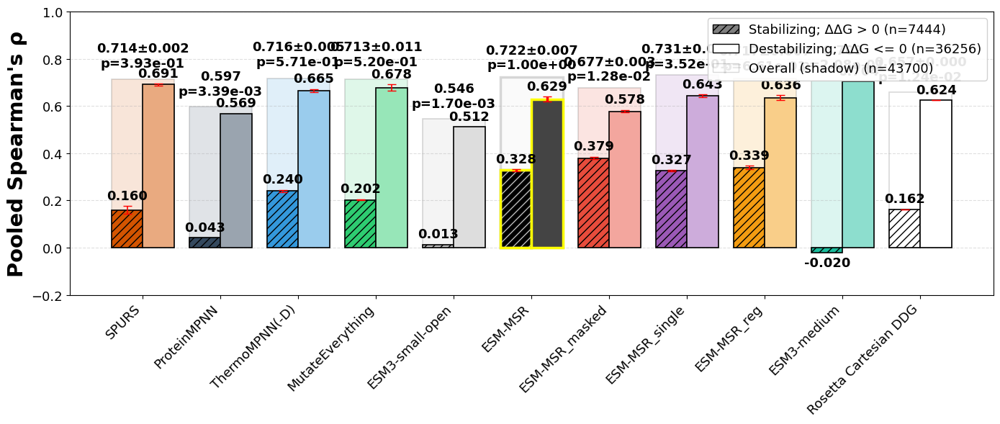

In [36]:
analysis_utils_msr.create_pos_neg_overall_chart(df_scores_combined.loc[('hyperopt_splits-test', 'ungrouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], title=None, y_label='Pooled Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, epistasis=False, ylim=(-0.2, 1), is_grouped=False, fontsize_multiplier=1.3) #'ESM-MSR_direct', 

In [37]:
# repeat pos vs neg analysis, for doubles only now

df_pos = df.loc[df['ddG']>0] #.dropna()
df_scores_pos_doubles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_pos_doubles = assess_all_models(df_pos.loc[df_pos['mut_type'].str.contains(':')], df_scores_pos_doubles, assess_grouped_spearman, splits=('hyperopt_splits-D-test', 'hyperopt_splits-test'))

df_neg = df.loc[df['ddG']<=0] #.dropna()
df_scores_neg_doubles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_neg_doubles = assess_all_models(df_neg.loc[df_neg['mut_type'].str.contains(':')], df_scores_neg_doubles, assess_grouped_spearman, splits=('hyperopt_splits-D-test', 'hyperopt_splits-test'))

df_scores_combined_doubles = df_scores.join(df_scores_pos_doubles, rsuffix='_pos').join(df_scores_neg_doubles, rsuffix='_neg')
df_scores_combined_doubles

ESM-MSR_1   ESM-MSR_1_n  ESM-MSR_1_groups  \
hyperopt_splits-S-test ungrouped   0.755461  32968.000000               NaN   
                       grouped     0.812046    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.367617  10732.000000               NaN   
                       grouped     0.799099   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.715575  43700.000000               NaN   
                       grouped     0.803615   1213.888889              36.0   

                                  ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-S-test ungrouped   0.765301  32968.000000               NaN   
                       grouped     0.813591    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.344472  10732.000000               NaN   
                       grouped     0.806849   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.713720  43700.000000               NaN   
                       grouped     0.805955   1213.888889              36.0   

                                  ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-S-test ungrouped   0.774775  32968.000000               NaN   
                       grouped     0.814873    915.777778              36.0   
hyperopt_splits-D-test ungrouped   0.380763  10732.000000               NaN   
                       grouped     0.806826   1533.142857               7.0   
hyperopt_splits-test   ungrouped   0.736382  43700.000000               NaN   
                       grouped     0.806365   1213.888889              36.0   

                                  ESM-MSR_alpha_med_1  ...  \
hyperopt_splits-S-test ungrouped             0.754444  ...   
                       grouped               0.783598  ...   
hyperopt_splits-D-test ungrouped             0.346260  ...   
                       grouped               0.727298  ...   
hyperopt_splits-test   ungrouped             0.739151  ...   
                       grouped               0.775102  ...   

                                  Rosetta Cartesian DDG_1_groups_neg  \
hyperopt_splits-S-test ungrouped                                 NaN   
                       grouped                                   NaN   
hyperopt_splits-D-test ungrouped                                 NaN   
                       grouped                                   7.0   
hyperopt_splits-test   ungrouped                                 NaN   
                       grouped                                   7.0   

                                  Rosetta Cartesian DDG_2_neg  \
hyperopt_splits-S-test ungrouped                          NaN   
                       grouped                            NaN   
hyperopt_splits-D-test ungrouped                     0.448837   
                       grouped                       0.447347   
hyperopt_splits-test   ungrouped                     0.448837   
                       grouped                       0.447347   

                                  Rosetta Cartesian DDG_2_n_neg  \
hyperopt_splits-S-test ungrouped                            NaN   
                       grouped                              NaN   
hyperopt_splits-D-test ungrouped                   10375.000000   
                       grouped                      1482.142857   
hyperopt_splits-test   ungrouped                   10375.000000   
                       grouped                      1482.142857   

                                  Rosetta Cartesian DDG_2_groups_neg  \
hyperopt_splits-S-test ungrouped                                 NaN   
                       grouped                                   NaN   
hyperopt_splits-D-test ungrouped                                 NaN   
                       grouped                                   7.0   
hyperopt_splits-test   ungrouped                                 NaN   
                       grouped                                   7.0   

 

(<Figure size 1400x600 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

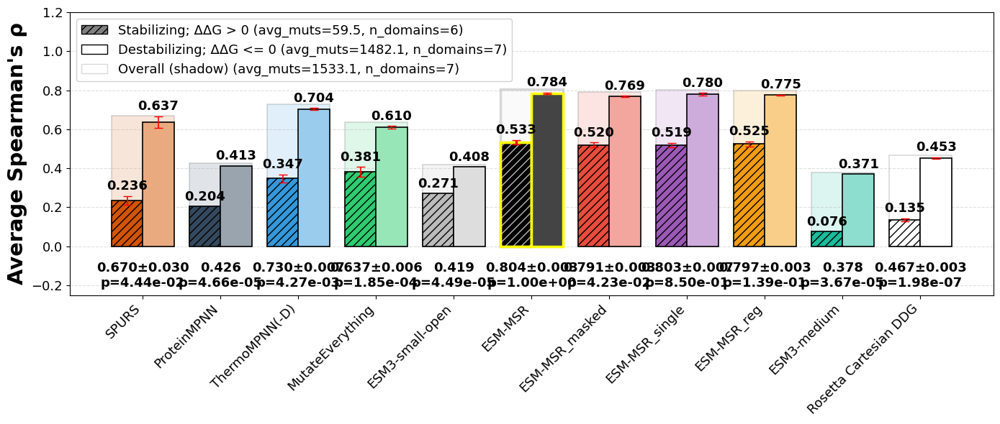

In [38]:
analysis_utils_msr.create_pos_neg_overall_chart(df_scores_combined_doubles.loc[('hyperopt_splits-D-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], title=None, y_label='Average Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, epistasis=False, fontsize_multiplier=1.3, legend_loc='upper left', ylim=(-0.25, 1.2), p_value_y_coord=-0.15)

(<Figure size 1400x600 with 1 Axes>, <Axes: ylabel="Pooled Spearman's ρ">)

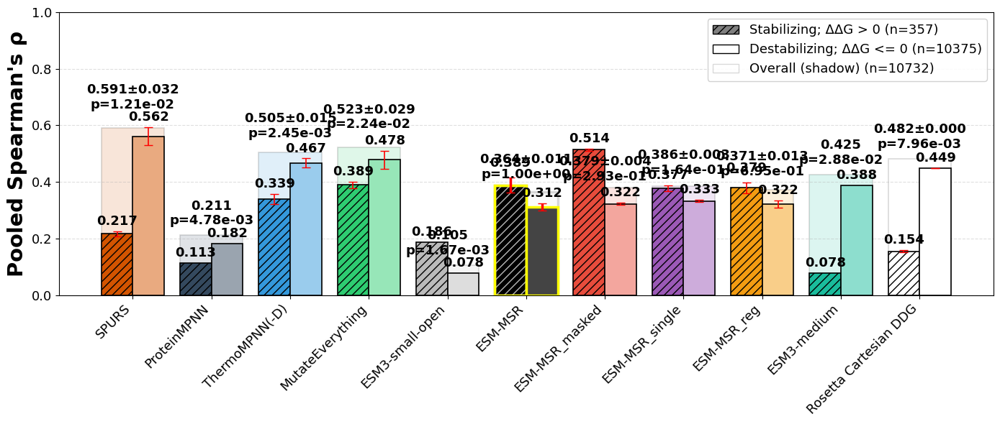

In [39]:
analysis_utils_msr.create_pos_neg_overall_chart(df_scores_combined_doubles.loc[('hyperopt_splits-D-test', 'ungrouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], title=None, y_label='Pooled Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, epistasis=False, fontsize_multiplier=1.3, is_grouped=False)

In [40]:
import importlib
importlib.reload(analysis_utils_msr)
from analysis_utils_msr import compute_dddg

df_scores_dddG = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))
df_dddG = df_epistatic.copy(deep=True)
df_dddG = compute_dddg(df_dddG)
df_dddG

,ThermoMPNN_1,ThermoMPNN(-D)_1,ThermoMPNN_2,ThermoMPNN(-D)_2,ThermoMPNN_3,ThermoMPNN(-D)_3,ThermoMPNN(-D)_additive_1,ThermoMPNN(-D)_additive_2,ThermoMPNN(-D)_additive_3,ddG_ML_thermo,...,ESM-MSR_reg_2_dddG,ESM-MSR_reg_3_dddG,ESM-MSR_masked_1_dddG,ESM-MSR_masked_2_dddG,ESM-MSR_masked_3_dddG,ESM-MSR_chain_1_dddG,ESM-MSR_chain_2_dddG,ESM-MSR_chain_3_dddG,ESM3-small-open_chain_dddG,ddG_dddG
uid,,,,,,,,,,,,,,,,,,,,,
1UFM_A11C,0.182458,0.182458,0.229011,0.229011,0.112110,0.112110,0.182458,0.229011,0.112110,0.004061,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
1UFM_A11D,-0.534806,-0.534806,-0.776187,-0.776187,-0.690362,-0.690362,-0.534806,-0.776187,-0.690362,-0.023454,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
1UFM_A11E,-0.127483,-0.127483,-0.176427,-0.176427,-0.169683,-0.169683,-0.127483,-0.176427,-0.169683,0.111864,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
1UFM_A11F,-0.037749,-0.037749,-0.077629,-0.077629,-0.115784,-0.115784,-0.037749,-0.077629,-0.115784,-0.153650,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
1UFM_A11G,-0.565192,-0.565192,-0.628311,-0.628311,-0.642682,-0.642682,-0.565192,-0.628311,-0.642682,-0.393182,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_R10Y:E36S,-1.687004,-0.557682,-1.533284,-1.408043,-1.497178,-0.774565,-1.687004,-1.533284,-1.497178,NaN,...,0.673687,0.733862,1.271679,1.411662,1.494090,0.580722,0.736679,0.579608,1.863220,0.946647
HHH_rd1_0949_R10Y:E36T,-1.304661,-0.486829,-1.297930,-1.210776,-1.352677,-0.265816,-1.304661,-1.297930,-1.352677,NaN,...,0.601406,0.540778,1.214785,1.327240,1.431294,0.521472,0.652309,0.499841,1.553223,0.602194
HHH_rd1_0949_R10Y:E36V,-0.525491,-0.274588,-0.531802,-0.501731,-0.583954,0.229817,-0.525491,-0.531802,-0.583954,NaN,...,0.832717,0.708154,1.357612,1.584037,1.663669,0.840289,0.982540,0.881671,1.907593,0.544439


In [124]:
df_scores_dddG = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

#df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_hybrid', 'hyperopt_splits-D-test', pred_col='ESM-MSR_hybrid_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, '(neg.) ΔΔG_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
df_scores_dddG['(neg.) ΔΔG_additive'] *= -1

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG = assess_grouped_spearman(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')

df_scores_dddG



df_dddG_pos = df_dddG.loc[df_dddG['ddG_dddG']>=0]
df_scores_dddG_pos = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

#df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_hybrid', 'hyperopt_splits-D-test', pred_col='ESM-MSR_hybrid_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, '(neg.) ΔΔG_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
df_scores_dddG_pos['(neg.) ΔΔG_additive'] *= -1

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG_pos = assess_grouped_spearman(df_dddG_pos.loc[df_dddG_pos['mut_type'].str.contains(':')], df_scores_dddG_pos, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')



df_dddG_neg = df_dddG.loc[df_dddG['ddG_dddG']<0]
df_scores_dddG_neg = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

#df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_hybrid', 'hyperopt_splits-D-test', pred_col='ESM-MSR_hybrid_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, '(neg.) ΔΔG_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
df_scores_dddG_neg['(neg.) ΔΔG_additive'] *= -1

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG_neg = assess_grouped_spearman(df_dddG_neg.loc[df_dddG_neg['mut_type'].str.contains(':')], df_scores_dddG_neg, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')

df_scores_dddG_combined = df_scores_dddG.join(df_scores_dddG_pos, rsuffix='_pos').join(df_scores_dddG_neg, rsuffix='_neg')

df_scores_dddG_combined[[c for c in df_scores_dddG_combined.columns if 'ESM-MSR' in c]].columns



Index(['ESM-MSR_1', 'ESM-MSR_1_n', 'ESM-MSR_1_groups', 'ESM-MSR_2',
       'ESM-MSR_2_n', 'ESM-MSR_2_groups', 'ESM-MSR_3', 'ESM-MSR_3_n',
       'ESM-MSR_3_groups', 'ESM-MSR_alpha_med_1',
       ...
       'ESM-MSR_reg_3_groups_neg', 'ESM-MSR_masked_1_neg',
       'ESM-MSR_masked_1_n_neg', 'ESM-MSR_masked_1_groups_neg',
       'ESM-MSR_masked_2_neg', 'ESM-MSR_masked_2_n_neg',
       'ESM-MSR_masked_2_groups_neg', 'ESM-MSR_masked_3_neg',
       'ESM-MSR_masked_3_n_neg', 'ESM-MSR_masked_3_groups_neg'],
      dtype='object', length=162)

(<Figure size 1000x600 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

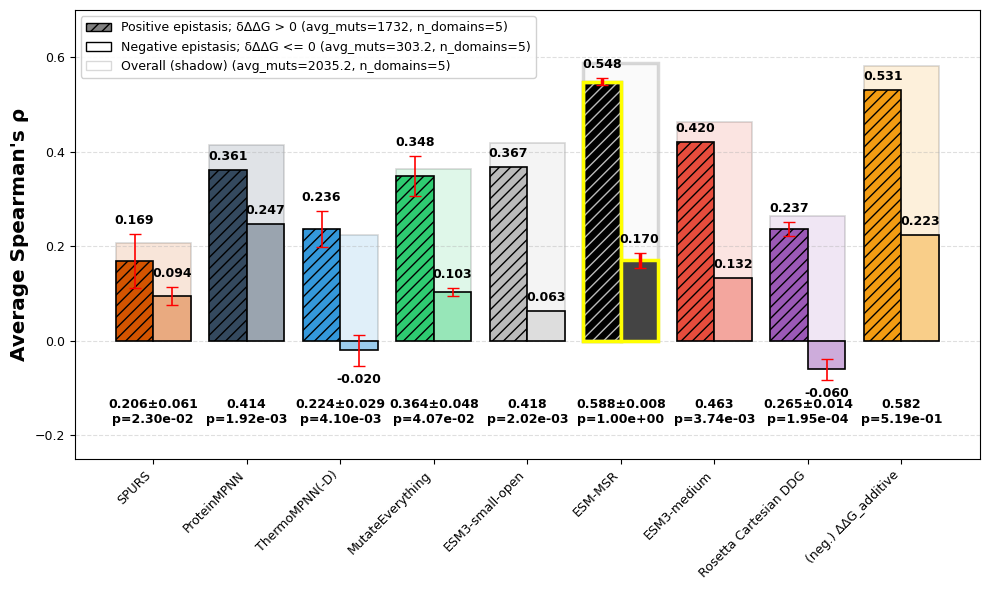

In [151]:
import importlib
importlib.reload(analysis_utils_msr)
analysis_utils_msr.create_pos_neg_overall_chart(df_scores_dddG_combined.loc[('hyperopt_splits-D-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG', '(neg.) ΔΔG_additive'], #'ESM3-small',  'ESM3-large',  'ESM3-small-open_masked','ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg',
                                                 title=None, y_label='Average Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, figsize=(10,6), ylim=(-0.25, 0.7), legend_loc='upper left',  p_value_y_coord=-0.15, fontsize_multiplier=0.9, epistasis=True)


(<Figure size 1600x1000 with 1 Axes>, <Axes: ylabel="Pooled Spearman's ρ">)

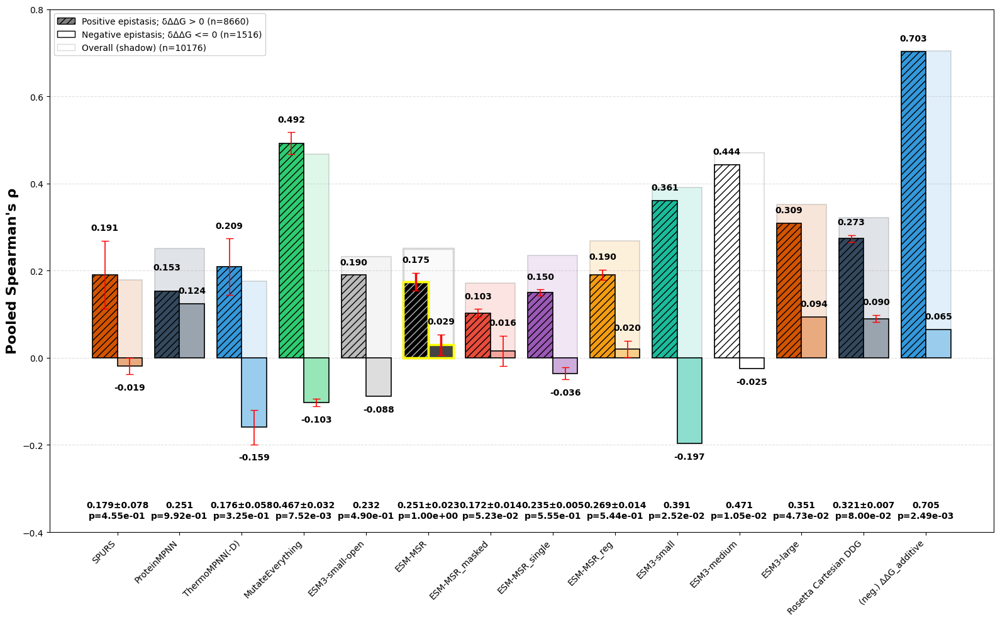

In [127]:
analysis_utils_msr.create_pos_neg_overall_chart(df_scores_dddG_combined.loc[('hyperopt_splits-D-test', 'ungrouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-small', 'ESM3-medium', 'ESM3-large', 'Rosetta Cartesian DDG', '(neg.) ΔΔG_additive'],
 title=None, y_label='Pooled Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, figsize=(16,10), ylim=(-0.4, 0.8), p_value_y_coord=-0.35, legend_loc='upper left', fontsize_multiplier=1., is_grouped=False)


In [44]:
import importlib
importlib.reload(analysis_utils_msr)
from analysis_utils_msr import assess_classification_metric

df_scores_dddG_cls = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped']]))
assess_mcc = partial(assess_classification_metric, metric_name='mcc', flip_labels=True)

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

#df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_hybrid', 'hyperopt_splits-D-test', pred_col='ESM-MSR_hybrid_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

#df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'Negative_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
#df_scores_dddG_cls['Negative_additive'] *= -1

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')].fillna(0), df_scores_dddG_cls, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')].fillna(0), df_scores_dddG_cls, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')].fillna(0), df_scores_dddG_cls, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG_cls = assess_mcc(df_dddG.loc[df_dddG['mut_type'].str.contains(':')], df_scores_dddG_cls, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')

df_scores_dddG_cls


,,ESM-MSR_1,ESM-MSR_1_n,ESM-MSR_2,ESM-MSR_2_n,ESM-MSR_3,ESM-MSR_3_n,ESM-MSR_alpha_med_1,ESM-MSR_alpha_med_1_n,ESM-MSR_alpha_med_2,ESM-MSR_alpha_med_2_n,...,ESM3-large,ESM3-large_n,Rosetta Cartesian DDG_1,Rosetta Cartesian DDG_1_n,Rosetta Cartesian DDG_2,Rosetta Cartesian DDG_2_n,Rosetta Cartesian DDG_3,Rosetta Cartesian DDG_3_n,ProteinMPNN,ProteinMPNN_n
hyperopt_splits-D-test,ungrouped,0.153831,10732.0,0.145632,10732.0,0.145625,10732.0,0.087775,10732.0,0.124024,10732.0,...,0.005746,10732.0,0.114577,10732.0,0.108779,10732.0,0.104497,10732.0,0.081598,10732.0


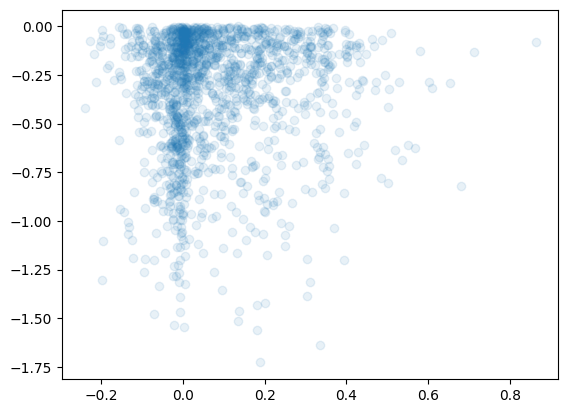

In [45]:
tmp = df_dddG.loc[df_dddG['ddG_dddG']<0]
tmp[[c for c in tmp.columns if 'dddG' in c]]
from matplotlib import pyplot as plt
plt.scatter(tmp['ESM-MSR_1_dddG'], tmp['ddG_dddG'], alpha=0.1)

In [46]:
df_dddG[[c for c in df_dddG if 'Thermo' in c]]

,ThermoMPNN_1,ThermoMPNN(-D)_1,ThermoMPNN_2,ThermoMPNN(-D)_2,ThermoMPNN_3,ThermoMPNN(-D)_3,ThermoMPNN(-D)_additive_1,ThermoMPNN(-D)_additive_2,ThermoMPNN(-D)_additive_3,ThermoMPNN(-D)_1_dddG,ThermoMPNN(-D)_2_dddG,ThermoMPNN(-D)_3_dddG
uid,,,,,,,,,,,,
1UFM_A11C,0.182458,0.182458,0.229011,0.229011,0.112110,0.112110,0.182458,0.229011,0.112110,0.000000,0.000000,0.000000
1UFM_A11D,-0.534806,-0.534806,-0.776187,-0.776187,-0.690362,-0.690362,-0.534806,-0.776187,-0.690362,0.000000,0.000000,0.000000
1UFM_A11E,-0.127483,-0.127483,-0.176427,-0.176427,-0.169683,-0.169683,-0.127483,-0.176427,-0.169683,0.000000,0.000000,0.000000
1UFM_A11F,-0.037749,-0.037749,-0.077629,-0.077629,-0.115784,-0.115784,-0.037749,-0.077629,-0.115784,0.000000,0.000000,0.000000
1UFM_A11G,-0.565192,-0.565192,-0.628311,-0.628311,-0.642682,-0.642682,-0.565192,-0.628311,-0.642682,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_R10Y:E36S,-1.687004,-0.557682,-1.533284,-1.408043,-1.497178,-0.774565,-1.687004,-1.533284,-1.497178,1.129323,0.125241,0.722613
HHH_rd1_0949_R10Y:E36T,-1.304661,-0.486829,-1.297930,-1.210776,-1.352677,-0.265816,-1.304661,-1.297930,-1.352677,0.817832,0.087153,1.086862
HHH_rd1_0949_R10Y:E36V,-0.525491,-0.274588,-0.531802,-0.501731,-0.583954,0.229817,-0.525491,-0.531802,-0.583954,0.250903,0.030070,0.813771


(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel='AUROC'>)

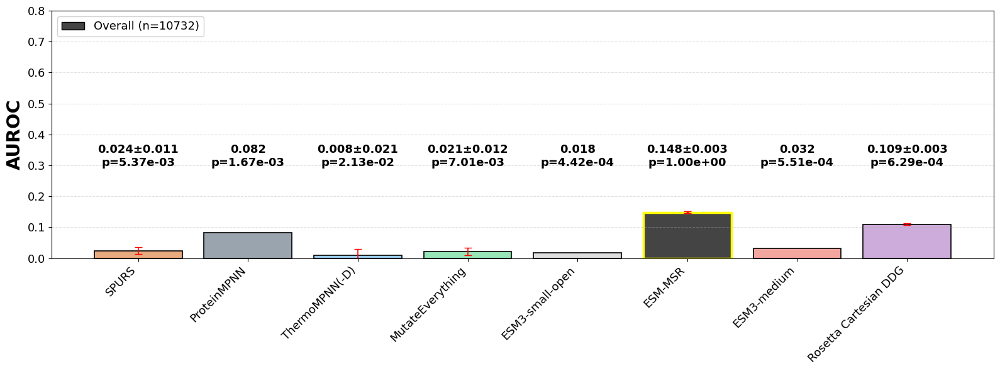

In [47]:
import importlib
importlib.reload(analysis_utils_msr)
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=None,
                                      series_bar2=None, 
                                      series_overall=df_scores_dddG_cls.loc[('hyperopt_splits-D-test', 'ungrouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg',
                                      title=None, y_label='AUROC', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(0,0.8), figsize=(16,6), p_value_y_coord=0.33, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left', is_grouped=False, highlight_gray='#444444')

(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel='AUPRC'>)

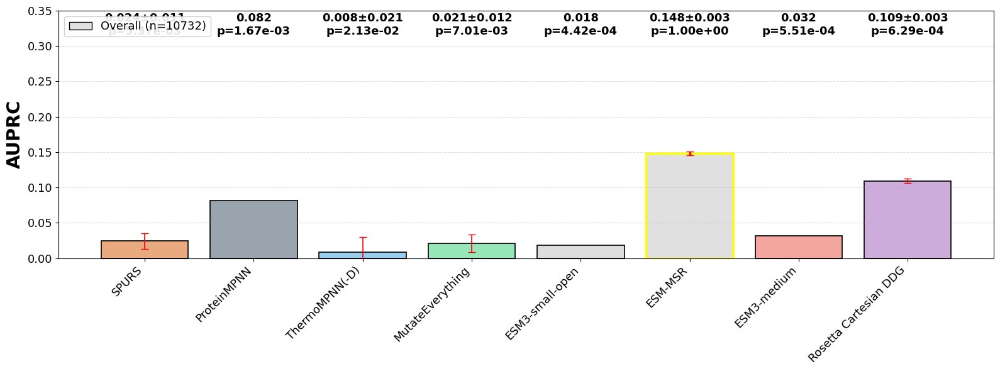

In [48]:
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=None,
                                      series_bar2=None, 
                                      series_overall=df_scores_dddG_cls.loc[('hyperopt_splits-D-test', 'ungrouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg',
                                      title=None, y_label='AUPRC', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(0,0.35), figsize=(16,6), p_value_y_coord=0.33, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left', is_grouped=False)

(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel='MCC'>)

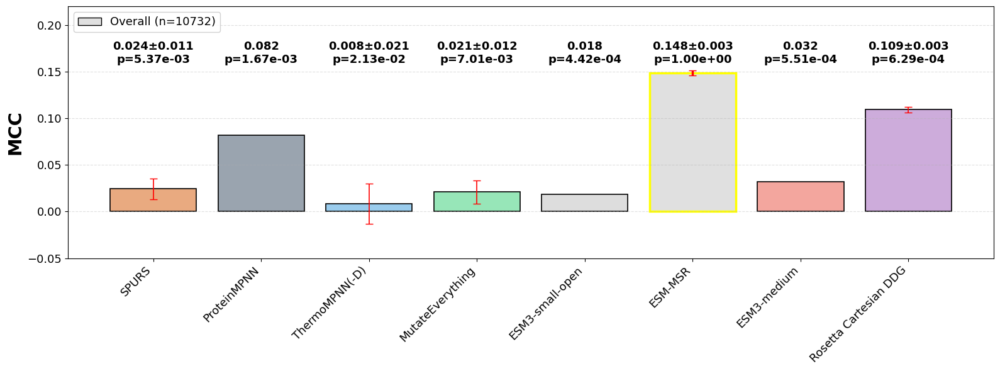

In [49]:
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=None,
                                      series_bar2=None, 
                                      series_overall=df_scores_dddG_cls.loc[('hyperopt_splits-D-test', 'ungrouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg',
                                      title=None, y_label='MCC', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.05,0.22), figsize=(16,6), p_value_y_coord=0.17, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left', is_grouped=False)

(<Figure size 1600x600 with 1 Axes>, <Axes: ylabel='F1 Score (inverted)'>)

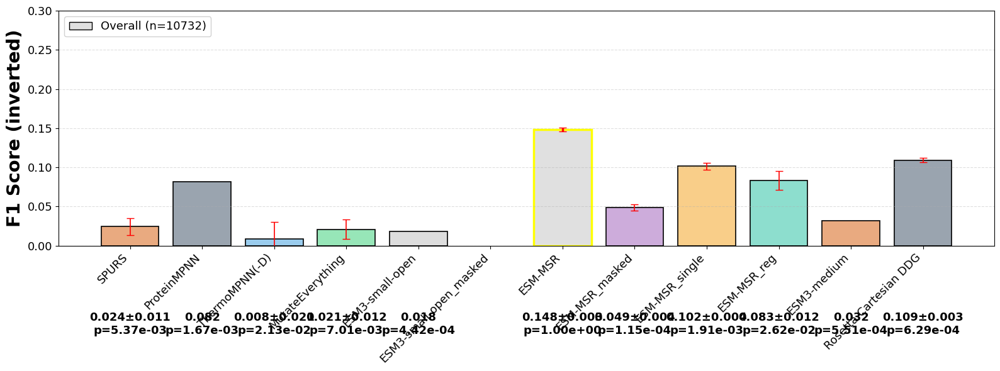

In [50]:
analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=None,
                                      series_bar2=None, 
                                      series_overall=df_scores_dddG_cls.loc[('hyperopt_splits-D-test', 'ungrouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM3-small-open_masked', 'ESM-MSR', 'ESM-MSR_masked', 'ESM-MSR_single', 'ESM-MSR_reg', 'ESM3-medium', 'Rosetta Cartesian DDG'], #'ESM3-small', 'ESM3-large',
                                      title=None, y_label='F1 Score (inverted)', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(0,0.3), figsize=(16,6), p_value_y_coord=-0.1, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left', is_grouped=False)

In [51]:
df_dddG_valid = df_dddG.loc[df_dddG['ddG_additive']>=-4]
df_scores_dddG_valid = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'Negative_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
df_scores_dddG_valid['Negative_additive'] *= -1

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG_valid = assess_grouped_spearman(df_dddG_valid.loc[df_dddG_valid['mut_type'].str.contains(':')], df_scores_dddG_valid, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')



df_dddG_dubious = df_dddG.loc[df_dddG['ddG_additive']<-4]
df_scores_dddG_dubious = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-D-test'], ['ungrouped', 'grouped']]))

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_med_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_med_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_med_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_med_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_low_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_low_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_alpha_low_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_alpha_low_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_single_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_single_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_single_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_single_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_reg_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_reg_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_reg_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_reg_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_masked_1', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_masked_2', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM-MSR_masked_3', 'hyperopt_splits-D-test', pred_col='ESM-MSR_masked_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'Negative_additive', 'hyperopt_splits-D-test', pred_col='ddG_additive', label='ddG_dddG')
df_scores_dddG_dubious['Negative_additive'] *= -1

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'SPURS_1', 'hyperopt_splits-D-test', pred_col='SPURS_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'SPURS_2', 'hyperopt_splits-D-test', pred_col='SPURS_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'SPURS_3', 'hyperopt_splits-D-test', pred_col='SPURS_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ThermoMPNN(-D)_1', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ThermoMPNN(-D)_2', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ThermoMPNN(-D)_3', 'hyperopt_splits-D-test', pred_col='ThermoMPNN(-D)_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'MutateEverything_1', 'hyperopt_splits-D-test', pred_col='MutateEverything_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'MutateEverything_2', 'hyperopt_splits-D-test', pred_col='MutateEverything_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'MutateEverything_3', 'hyperopt_splits-D-test', pred_col='MutateEverything_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM3-small-open', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_dddG', label='ddG_dddG')
#df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM3-small-open_masked', 'hyperopt_splits-D-test', pred_col='ESM3-small-open_masked_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM3-small', 'hyperopt_splits-D-test', pred_col='ESM3-small_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM3-medium', 'hyperopt_splits-D-test', pred_col='ESM3-medium_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ESM3-large', 'hyperopt_splits-D-test', pred_col='ESM3-large_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_1_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_2_dddG', label='ddG_dddG')
df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-D-test', pred_col='Rosetta Cartesian DDG_3_dddG', label='ddG_dddG')

df_scores_dddG_dubious = assess_grouped_spearman(df_dddG_dubious.loc[df_dddG_dubious['mut_type'].str.contains(':')], df_scores_dddG_dubious, 'ProteinMPNN', 'hyperopt_splits-D-test', pred_col='ProteinMPNN_dddG', label='ddG_dddG')

df_scores_dddG_combined_2 = df_scores_dddG.join(df_scores_dddG_valid, rsuffix='_pos').join(df_scores_dddG_dubious, rsuffix='_neg')

df_scores_dddG_combined_2[[c for c in df_scores_dddG_combined_2.columns if 'ESM-MSR' in c]].columns



Index(['ESM-MSR_1', 'ESM-MSR_1_n', 'ESM-MSR_1_groups', 'ESM-MSR_2',
       'ESM-MSR_2_n', 'ESM-MSR_2_groups', 'ESM-MSR_3', 'ESM-MSR_3_n',
       'ESM-MSR_3_groups', 'ESM-MSR_alpha_med_1',
       ...
       'ESM-MSR_reg_3_groups_neg', 'ESM-MSR_masked_1_neg',
       'ESM-MSR_masked_1_n_neg', 'ESM-MSR_masked_1_groups_neg',
       'ESM-MSR_masked_2_neg', 'ESM-MSR_masked_2_n_neg',
       'ESM-MSR_masked_2_groups_neg', 'ESM-MSR_masked_3_neg',
       'ESM-MSR_masked_3_n_neg', 'ESM-MSR_masked_3_groups_neg'],
      dtype='object', length=162)

(<Figure size 1600x800 with 1 Axes>, <Axes: ylabel="Average Spearman's ρ">)

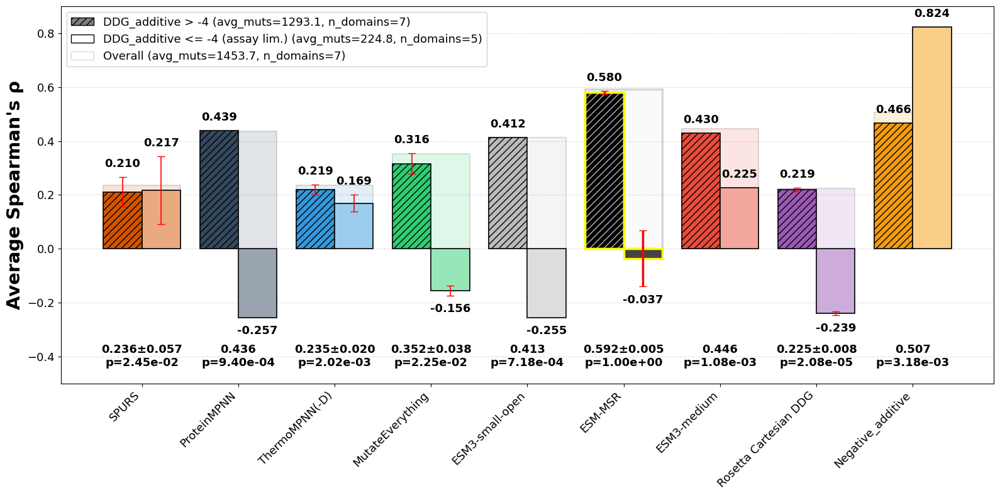

In [52]:
import importlib
importlib.reload(analysis_utils_msr)

analysis_utils_msr.create_triple_metric_chart_with_pvals(series_bar1=df_scores_dddG_valid.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_bar2=df_scores_dddG_dubious.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      series_overall=df_scores_dddG.loc[('hyperopt_splits-D-test', 'grouped')], 
                                      model_groups=['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG', 'Negative_additive'], # 'ESM3-small','ESM3-large',
                                      title=None, y_label='Average Spearman\'s ρ', highlighted_model='ESM-MSR', enforce_global_n=False, ylim=(-0.5,0.9), figsize=(16,8), p_value_y_coord=-0.4, label_min_sep=0.02, fontsize_multiplier=1.3, legend_loc='upper left',
                                      label_bar1="DDG_additive > -4", label_bar2="DDG_additive <= -4 (assay lim.)", label_overall="Overall")

0.8557320483074543
0.17760663013624944
0.9251144430935825


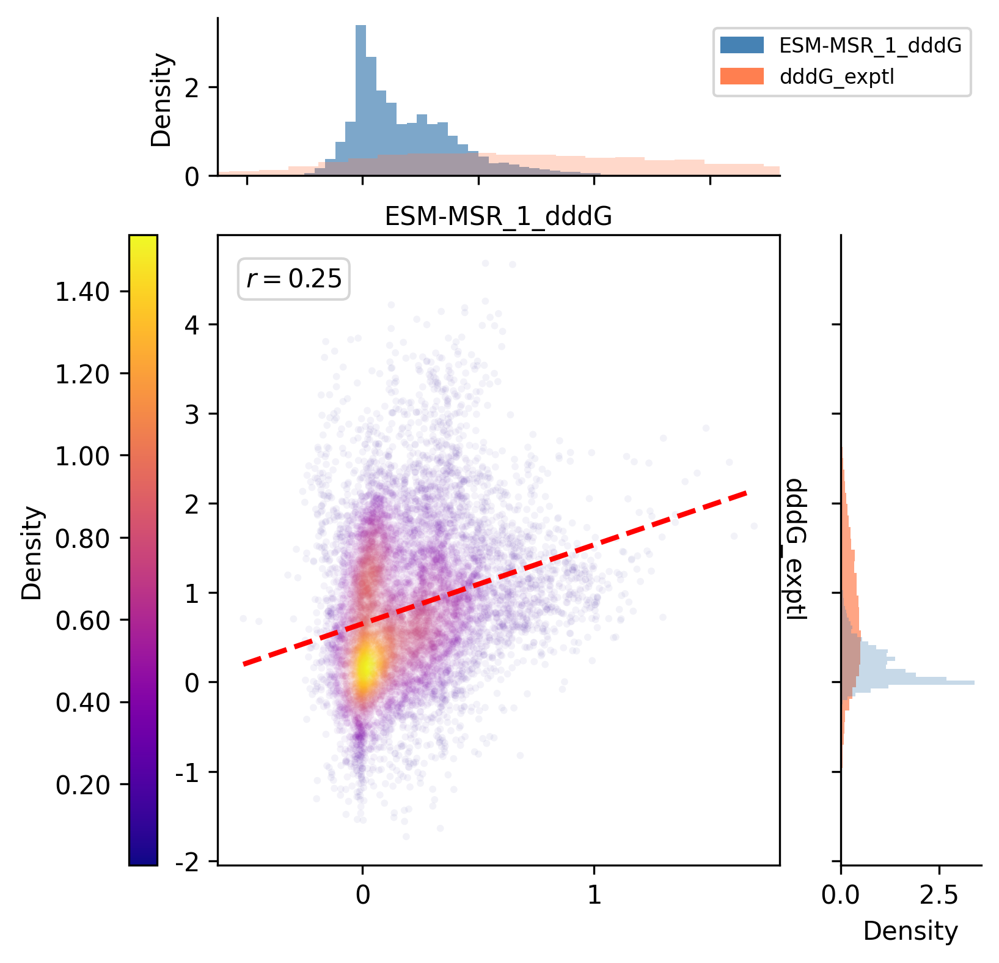

In [53]:
import importlib
importlib.reload(analysis_utils_msr)
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score

from analysis_utils_msr import density_scatter

df_dddG['dddG_exptl'] = df_dddG['ddG_dddG']
df_dddG_clean = df_dddG[['dddG_exptl', 'ESM-MSR_1_dddG']].dropna()

density_scatter(df_dddG_clean['ESM-MSR_1_dddG'], df_dddG_clean['dddG_exptl'], point_alpha=0.05, s=8, cmap="plasma", stats=True)

f1 = f1_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']]>0)
auprc = average_precision_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']])

print(f1)
print(mcc)
print(auprc)

<Axes: xlabel='ESM-MSR_1', ylabel='ddG'>

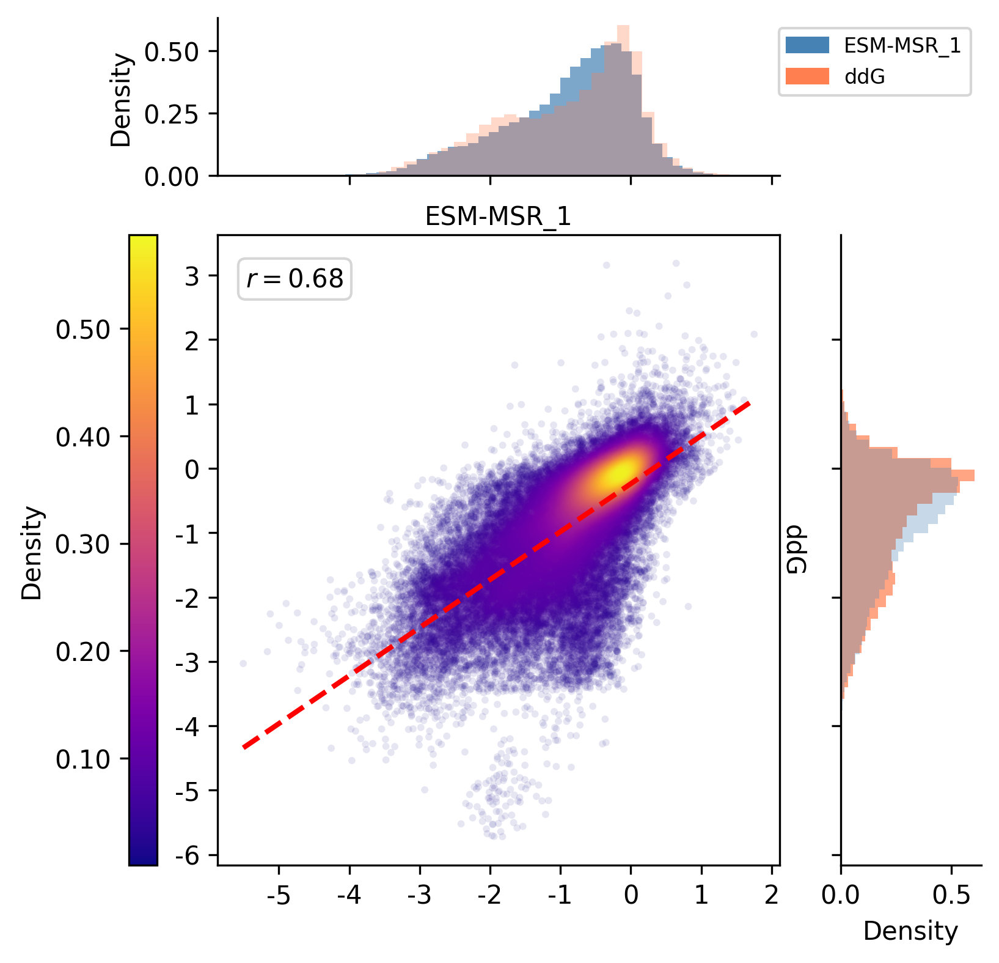

In [54]:
density_scatter(df_dddG['ESM-MSR_1'], df_dddG['ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)

<Axes: xlabel='ESM-MSR_1', ylabel='ddG'>

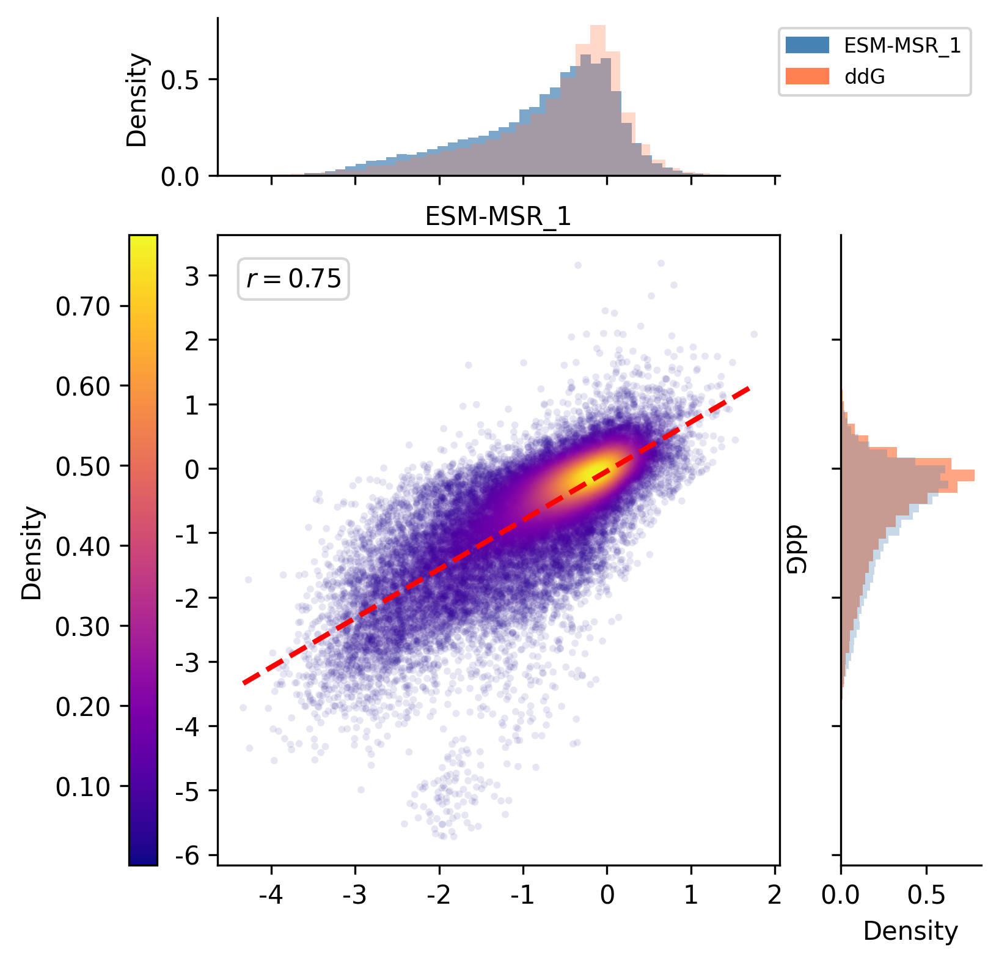

In [55]:
density_scatter(df_dddG.loc[~df_dddG.index.str.contains(':'), 'ESM-MSR_1'], df_dddG.loc[~df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)

<Axes: xlabel='ESM-MSR_1', ylabel='ddG'>

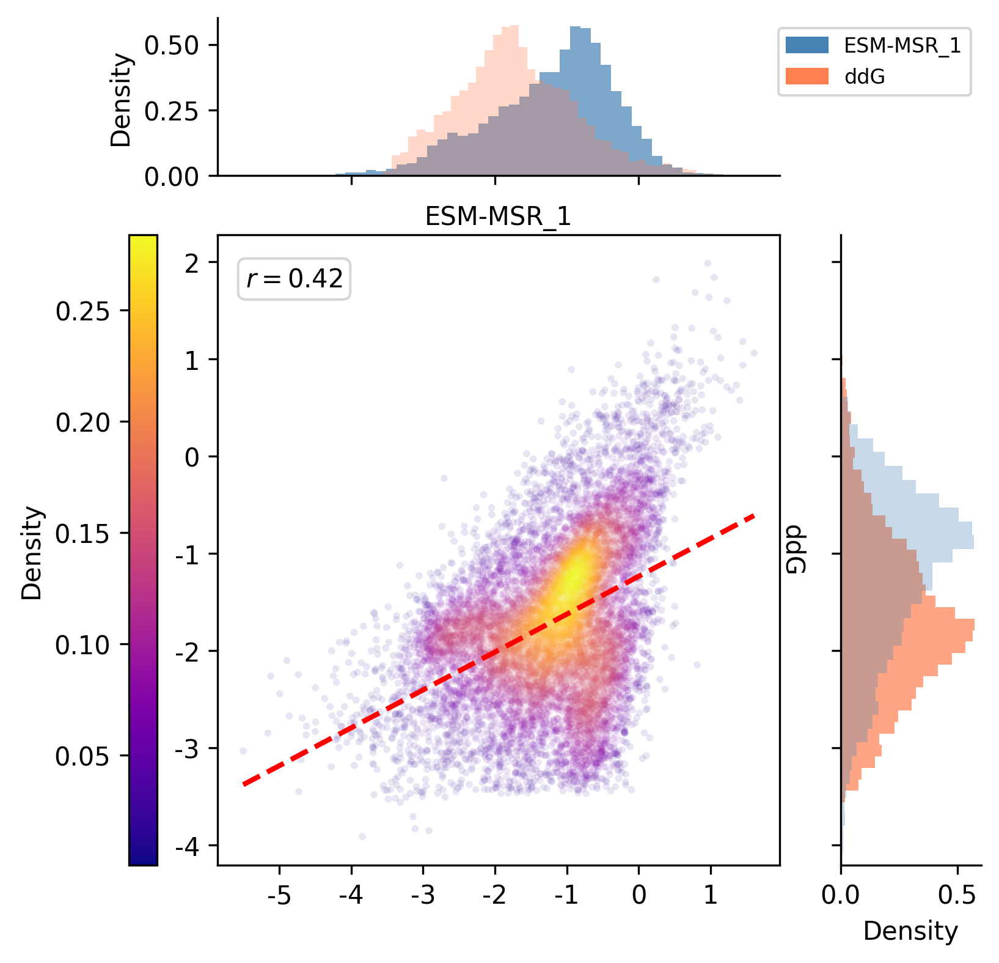

In [56]:
density_scatter(df_dddG.loc[df_dddG.index.str.contains(':'), 'ESM-MSR_1'], df_dddG.loc[df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)

In [57]:
df_dddG.loc[df_dddG.index.str.contains(':'), 'code'].unique()

array(['1UFM', '2RU9', '3DKM', '6M3N', 'HHH_rd1_0244', 'HHH_rd1_0493',
       'HHH_rd1_0949'], dtype=object)

<Axes: xlabel='ESM-MSR_1', ylabel='ddG'>

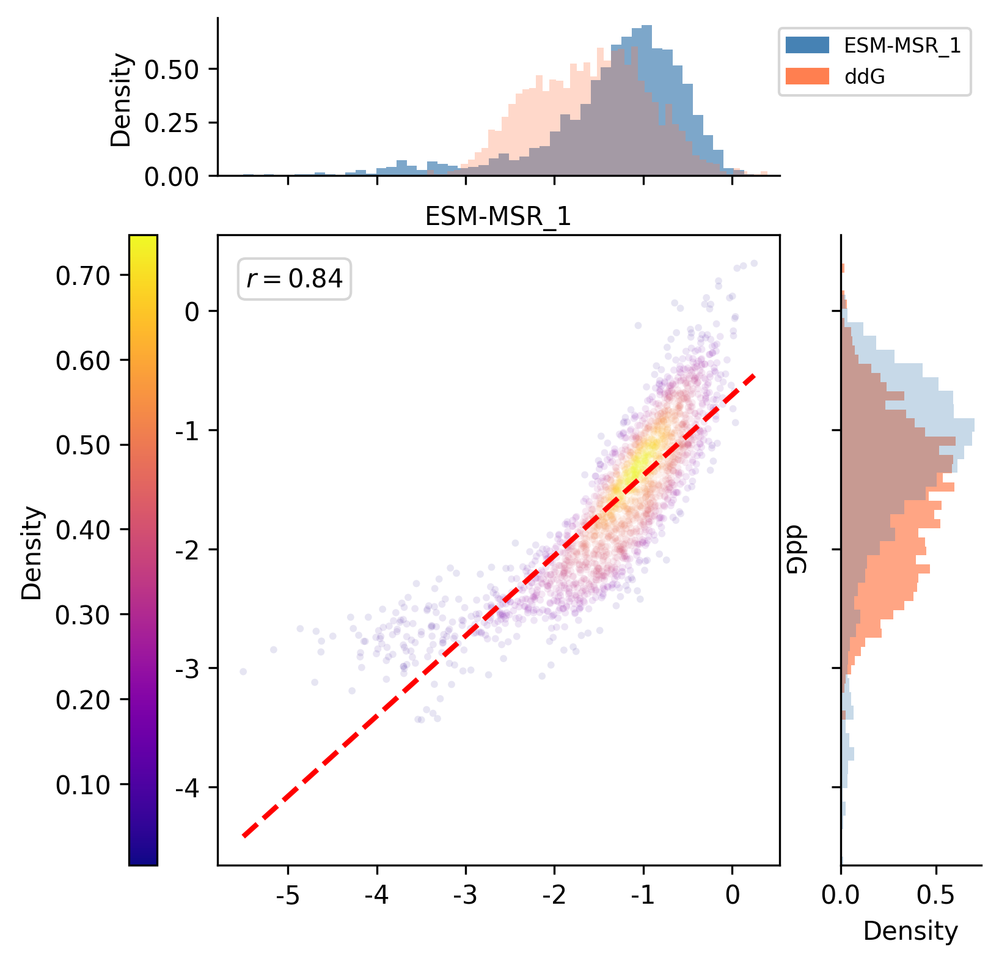

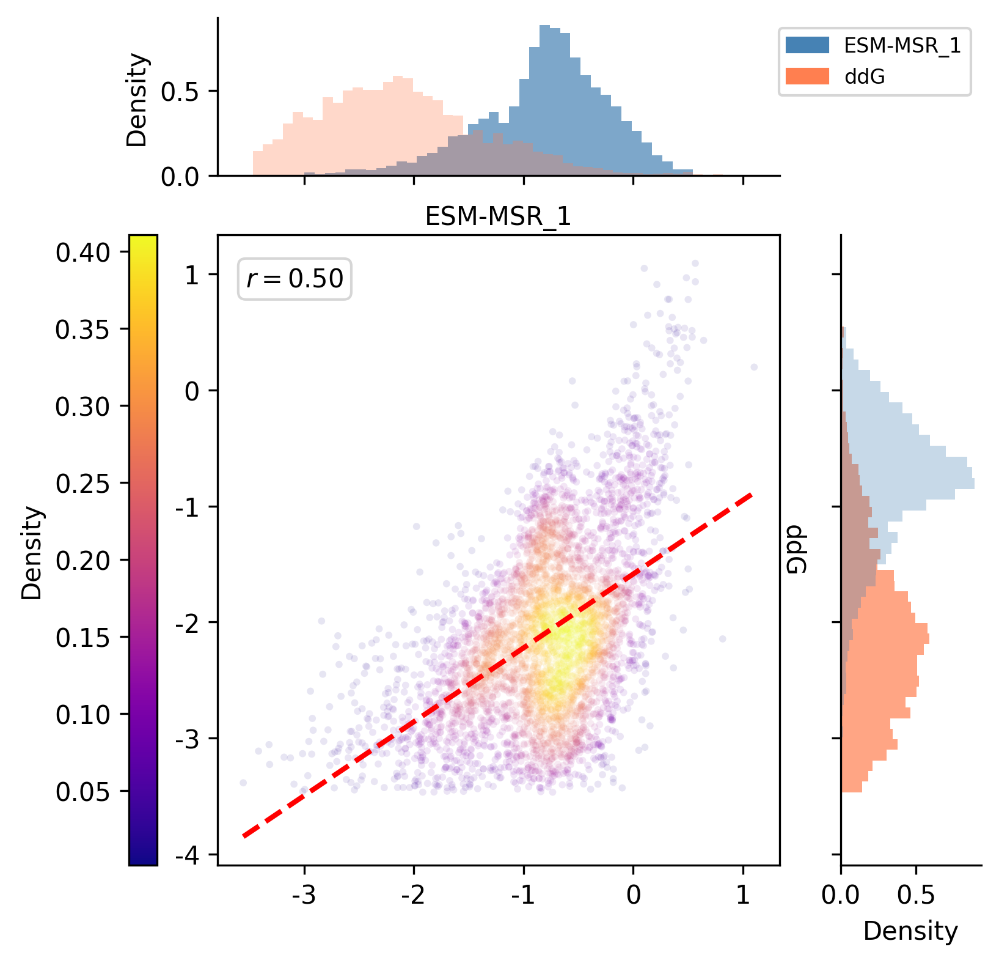

In [58]:
density_scatter(df_dddG.loc[df_dddG.index.str.contains(':') & df_dddG.index.str.contains('1UFM'), 'ESM-MSR_1'], df_dddG.loc[df_dddG.index.str.contains(':') & df_dddG.index.str.contains('1UFM'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)
density_scatter(df_dddG.loc[df_dddG.index.str.contains(':') & df_dddG.index.str.contains('3DKM'), 'ESM-MSR_1'], df_dddG.loc[df_dddG.index.str.contains(':') & df_dddG.index.str.contains('3DKM'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)

<Axes: xlabel='ThermoMPNN(-D)_1', ylabel='ddG'>

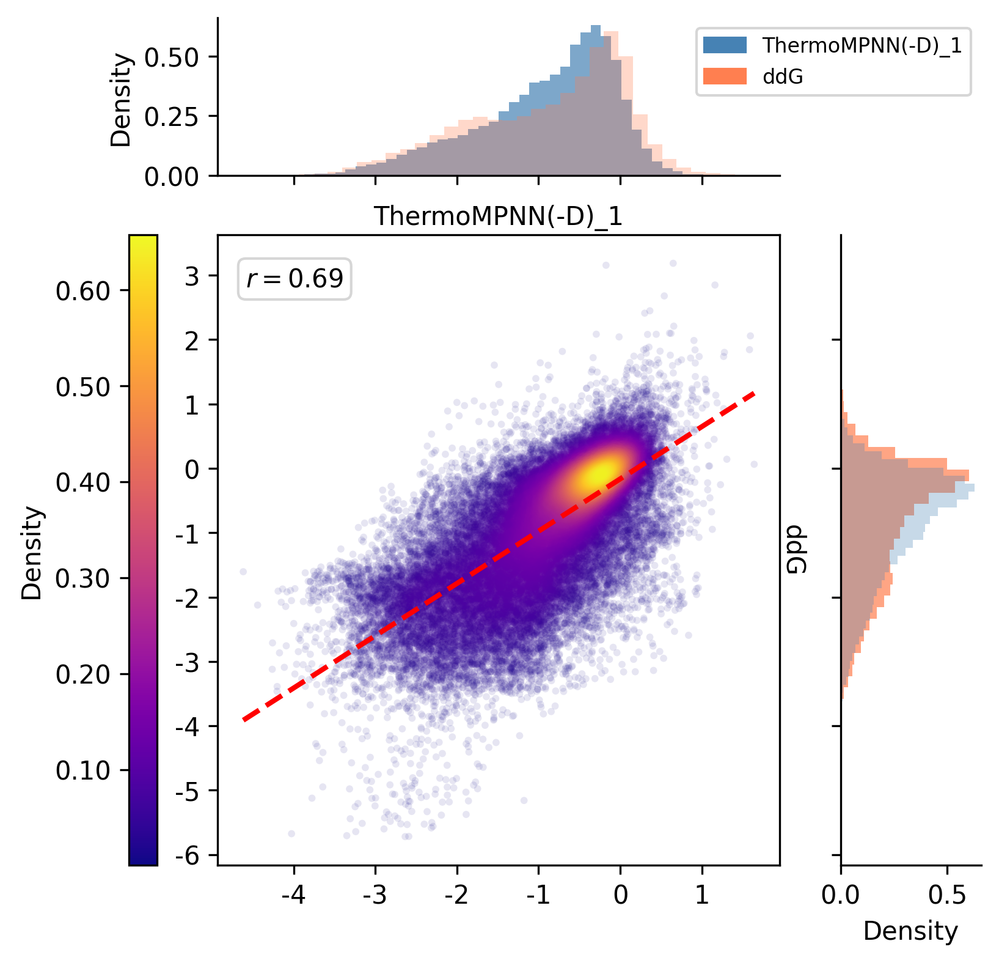

In [59]:
density_scatter(df_dddG['ThermoMPNN(-D)_1'], df_dddG['ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True) #.dropna

<Axes: xlabel='ThermoMPNN(-D)_1', ylabel='ddG'>

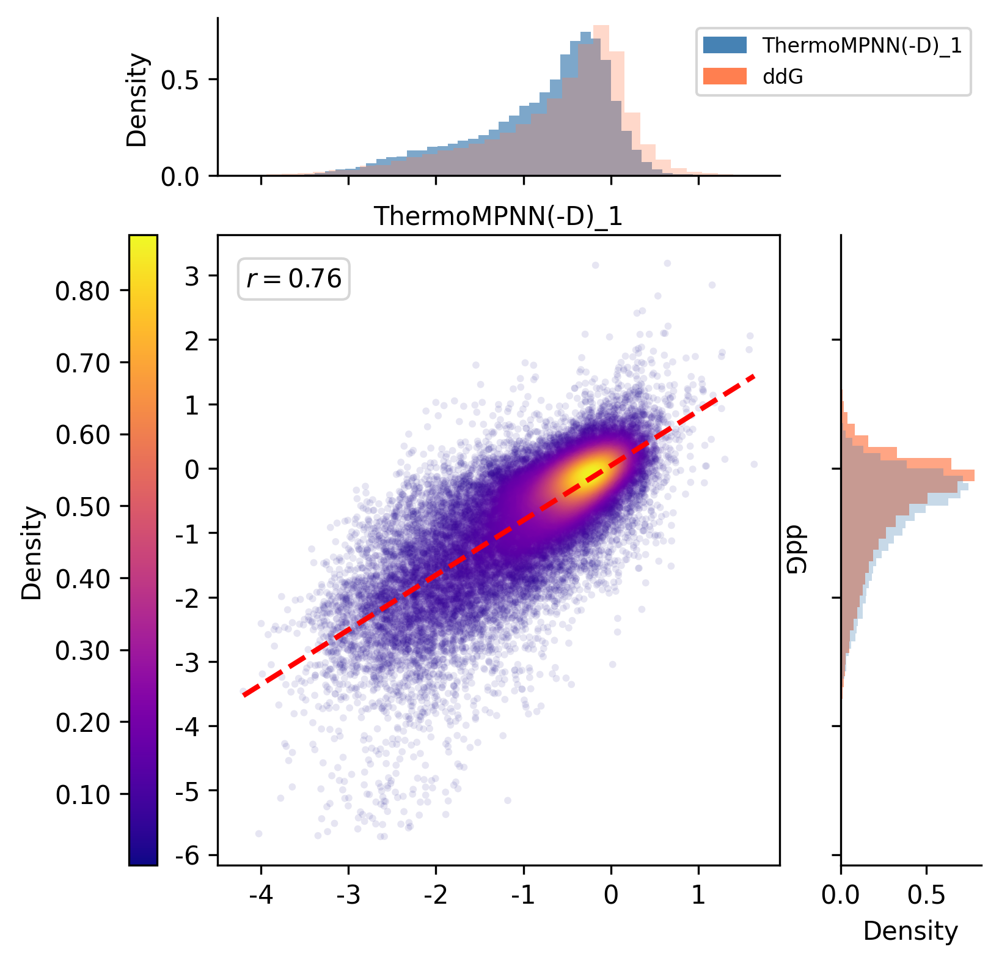

In [60]:
density_scatter(df_dddG.loc[~df_dddG.index.str.contains(':'), 'ThermoMPNN(-D)_1'], df_dddG.loc[~df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True) #.dropna

<Axes: xlabel='ThermoMPNN(-D)_1', ylabel='ddG'>

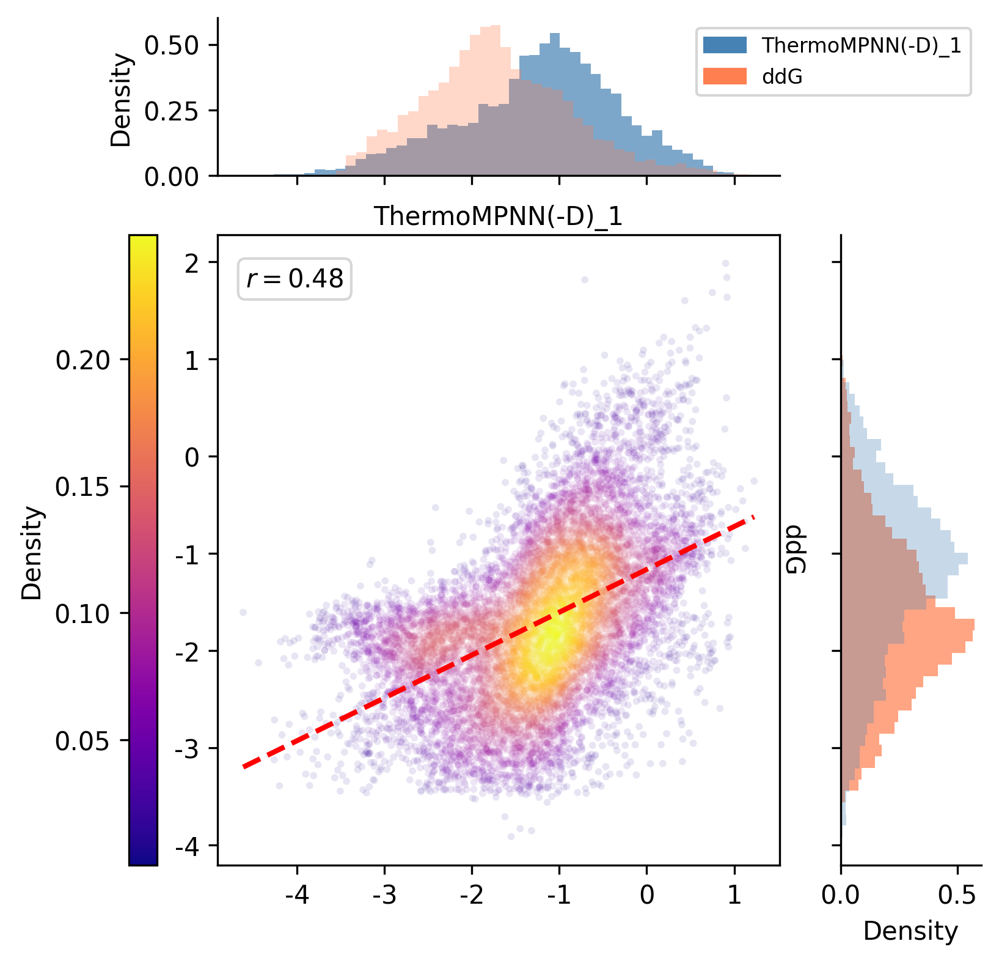

In [61]:
density_scatter(df_dddG.loc[df_dddG.index.str.contains(':'), 'ThermoMPNN(-D)_1'], df_dddG.loc[df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True) #.dropna

<Axes: xlabel='MutateEverything_1', ylabel='ddG'>

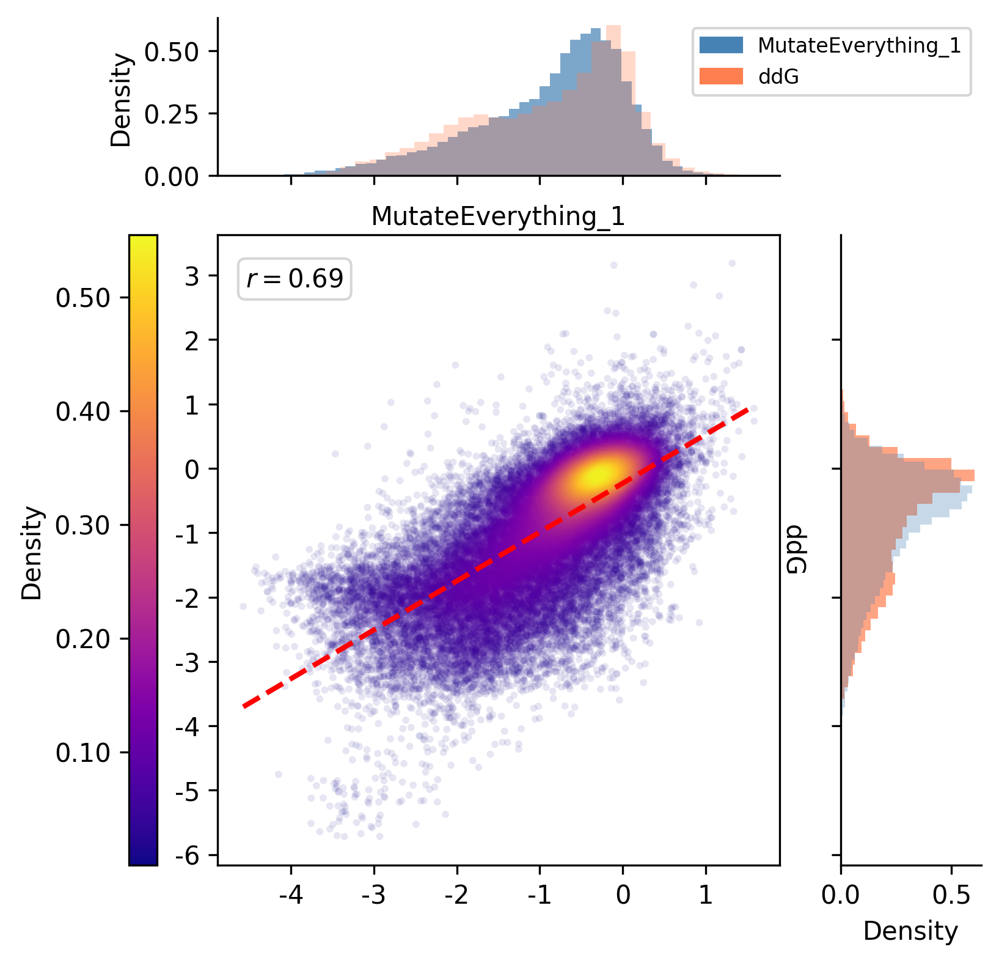

In [62]:
density_scatter(df_dddG['MutateEverything_1'], df_dddG['ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True)

<Axes: xlabel='MutateEverything_1', ylabel='ddG'>

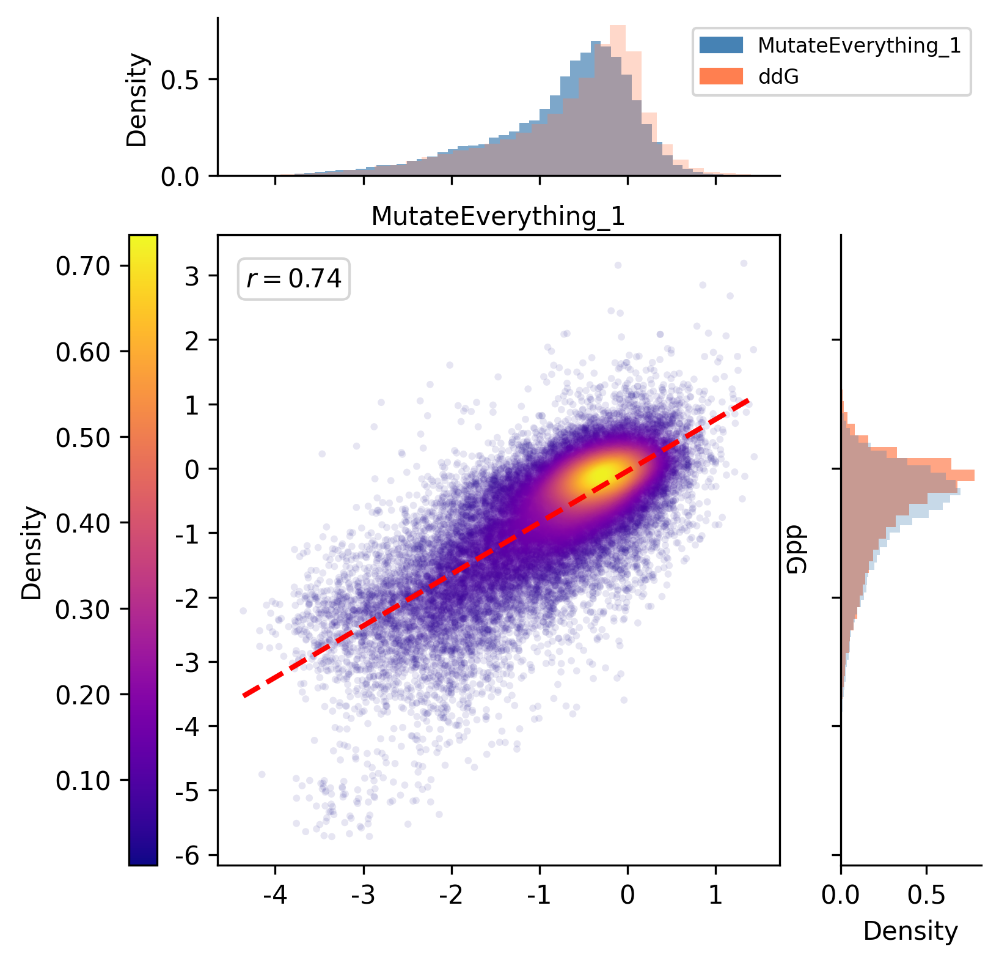

In [63]:
density_scatter(df_dddG.loc[~df_dddG.index.str.contains(':'), 'MutateEverything_1'], df_dddG.loc[~df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True) #.dropna

<Axes: xlabel='MutateEverything_1', ylabel='ddG'>

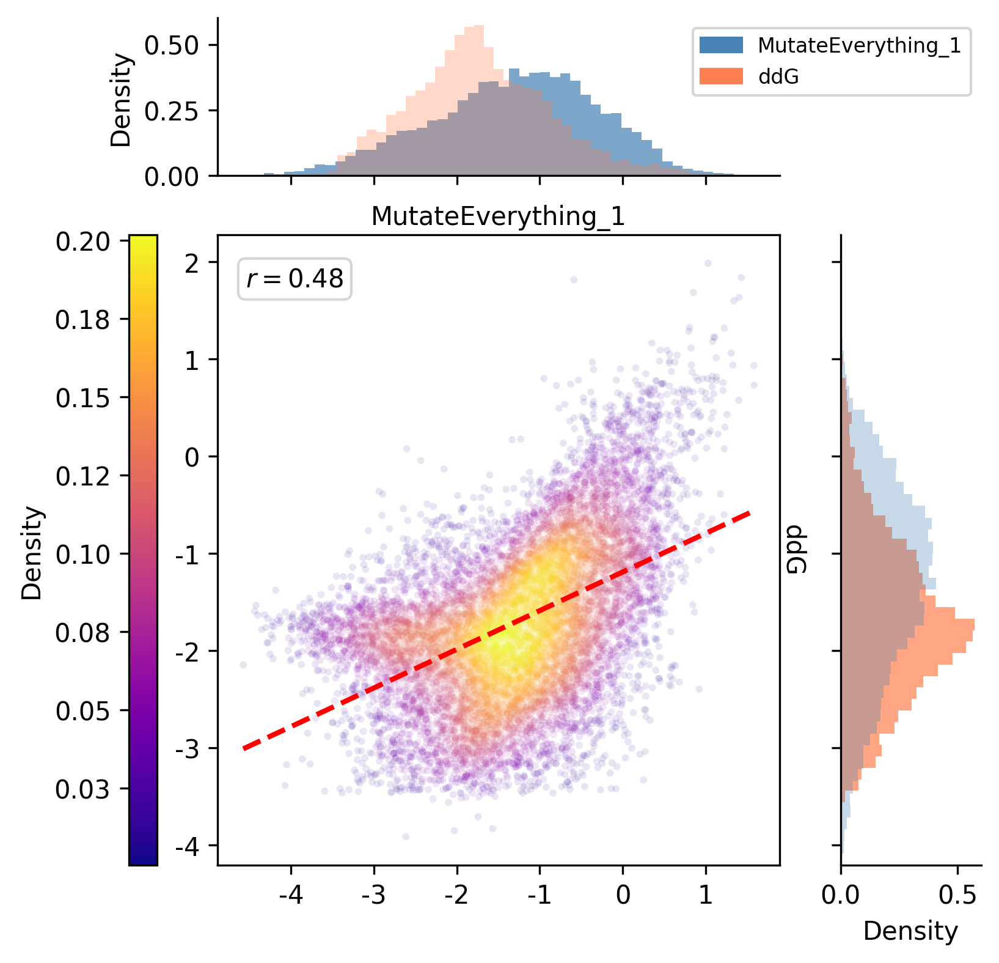

In [64]:
density_scatter(df_dddG.loc[df_dddG.index.str.contains(':'), 'MutateEverything_1'], df_dddG.loc[df_dddG.index.str.contains(':'), 'ddG'], point_alpha=0.1, s=8, cmap="plasma", stats=True) #.dropna

<Axes: xlabel='SPURS_1', ylabel='ddG'>

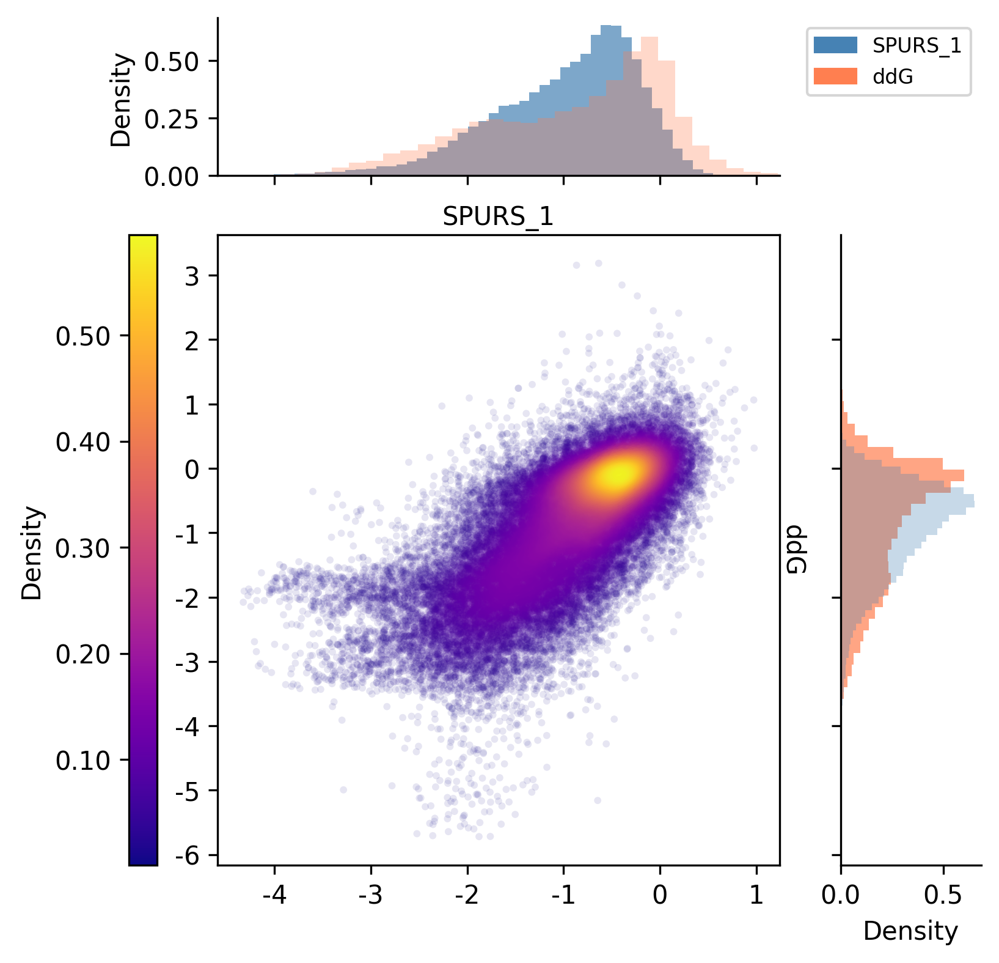

In [65]:
density_scatter(df_dddG['SPURS_1'], df_dddG['ddG'], point_alpha=0.1, s=8, cmap="plasma")

<Axes: xlabel='ESM3-small-open', ylabel='ddG'>

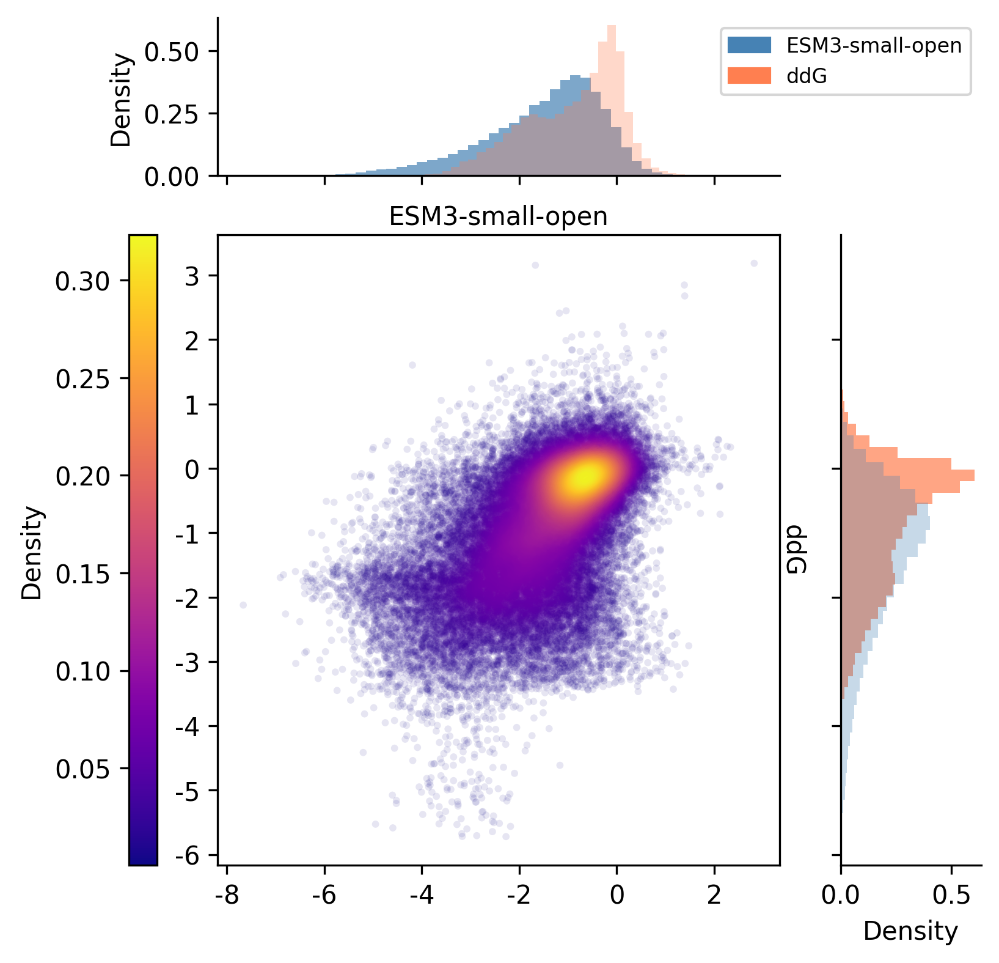

In [66]:
density_scatter(df_dddG['ESM3-small-open'], df_dddG['ddG'], point_alpha=0.1, s=8, cmap="plasma")

,ddG_additive,ddG,ddG_dddG
uid,,,
1UFM_E14A:E53A,-1.742914,-1.746995,-0.004082
1UFM_E14A:E53D,-1.683631,-1.524802,0.158829
1UFM_E14A:E53F,-3.021748,-2.029420,0.992328
1UFM_E14A:E53G,-2.268398,-1.917165,0.351233
1UFM_E14A:E53H,-2.450991,-2.040422,0.410570
...,...,...,...
HHH_rd1_0949_R10Y:E36S,-1.240620,-0.293973,0.946647
HHH_rd1_0949_R10Y:E36T,-0.983655,-0.381462,0.602194
HHH_rd1_0949_R10Y:E36V,-0.178556,0.365883,0.544439


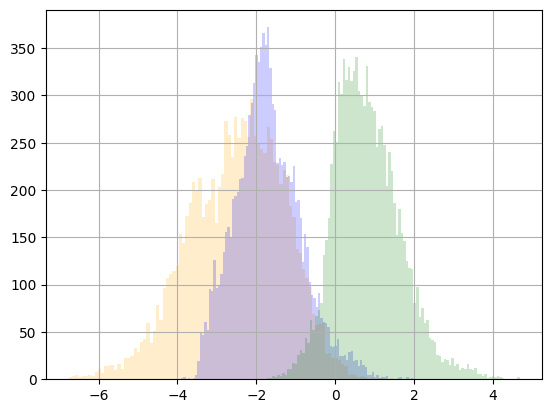

In [67]:
df_dddG.loc[df.index.str.contains(':')]['ddG_additive'].hist(bins=100, alpha=0.2, color='orange')
df_dddG.loc[df.index.str.contains(':')]['ddG'].hist(bins=100, alpha=0.2, color='blue')

df_dddG['ddG_dddG'].hist(bins=100, alpha=0.2, color='green')
df_dddG[['ddG_additive', 'ddG', 'ddG_dddG']].dropna()

0.9155237739473825
0.0015597437751152157
0.9567586438052912
                              δΔΔG experimental (kcal/mol)  \
δΔΔG experimental (kcal/mol)                      1.000000   
-(ΔΔG additive) (kcal/mol)                        0.704691   

                              -(ΔΔG additive) (kcal/mol)  
δΔΔG experimental (kcal/mol)                    0.704691  
-(ΔΔG additive) (kcal/mol)                      1.000000  


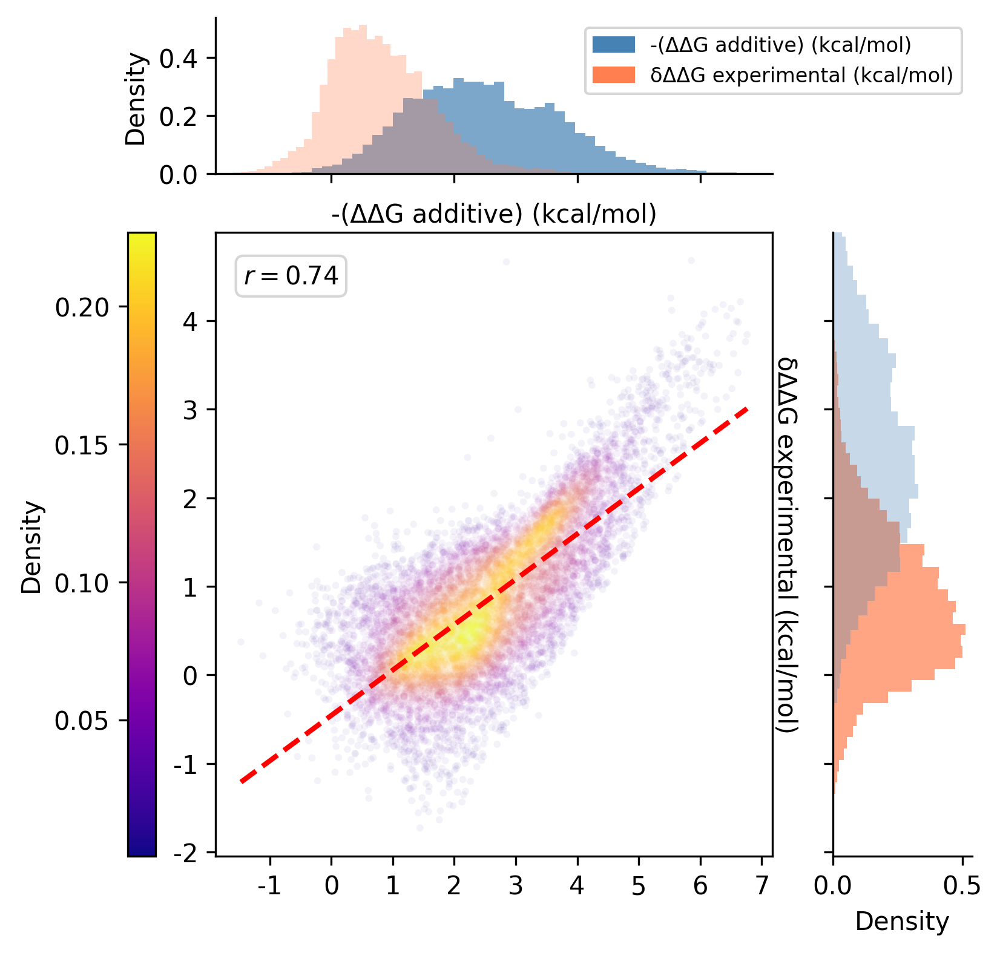

In [68]:
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score
import importlib
importlib.reload(analysis_utils_msr)

from analysis_utils_msr import density_scatter

df_dddG['δΔΔG experimental (kcal/mol)'] = df_dddG['ddG_dddG']
df_dddG['-(ΔΔG additive) (kcal/mol)'] = -df_dddG['ddG_additive']
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'δΔΔG experimental (kcal/mol)']].dropna()

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['δΔΔG experimental (kcal/mol)'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=False, stats=True)

f1 = f1_score(df_dddG_clean[['δΔΔG experimental (kcal/mol)']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['δΔΔG experimental (kcal/mol)']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['δΔΔG experimental (kcal/mol)']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG[['δΔΔG experimental (kcal/mol)', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.07423047005222802
0.06998138440473577
0.8877123717529737
                       δΔΔG exptl (kcal/mol)  ΔΔG (kcal/mol)
δΔΔG exptl (kcal/mol)               1.000000       -0.075143
ΔΔG (kcal/mol)                     -0.075143        1.000000


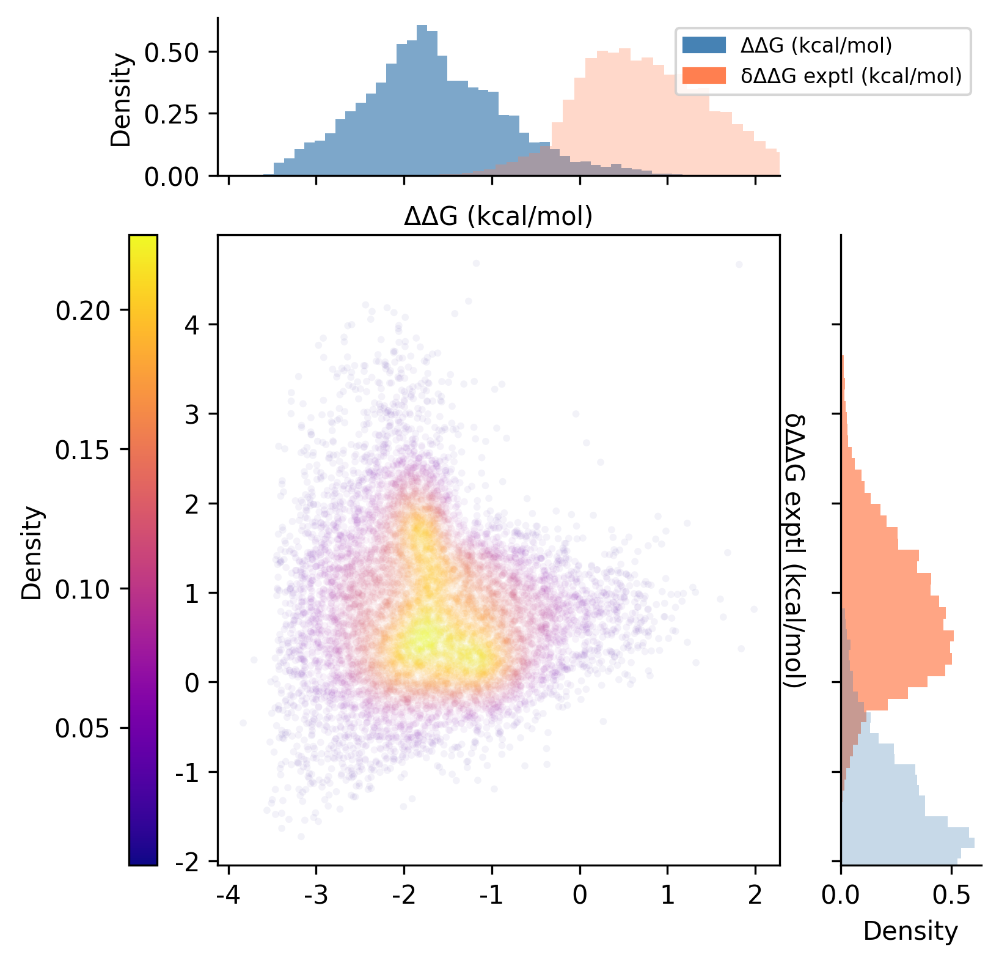

In [69]:
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score
import importlib
importlib.reload(analysis_utils_msr)

from analysis_utils_msr import density_scatter

df_dddG['δΔΔG exptl (kcal/mol)'] = df_dddG['ddG_dddG']
df_dddG['ΔΔG (kcal/mol)'] = df_dddG['ddG']
df_dddG_clean = df_dddG[['ΔΔG (kcal/mol)', 'δΔΔG exptl (kcal/mol)']].dropna()

density_scatter(df_dddG_clean['ΔΔG (kcal/mol)'], df_dddG_clean['δΔΔG exptl (kcal/mol)'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=False, stats=False)

f1 = f1_score(df_dddG_clean[['δΔΔG exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['δΔΔG exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['δΔΔG exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG[['δΔΔG exptl (kcal/mol)', 'ΔΔG (kcal/mol)']].corr('spearman'))

0.39908256880733944
0.47209830552668425
0.6562703660711597
                         ΔΔG_exptl (kcal/mol)  ΔΔG additive (kcal/mol)
ΔΔG_exptl (kcal/mol)                 1.000000                 0.730326
ΔΔG additive (kcal/mol)              0.730326                 1.000000


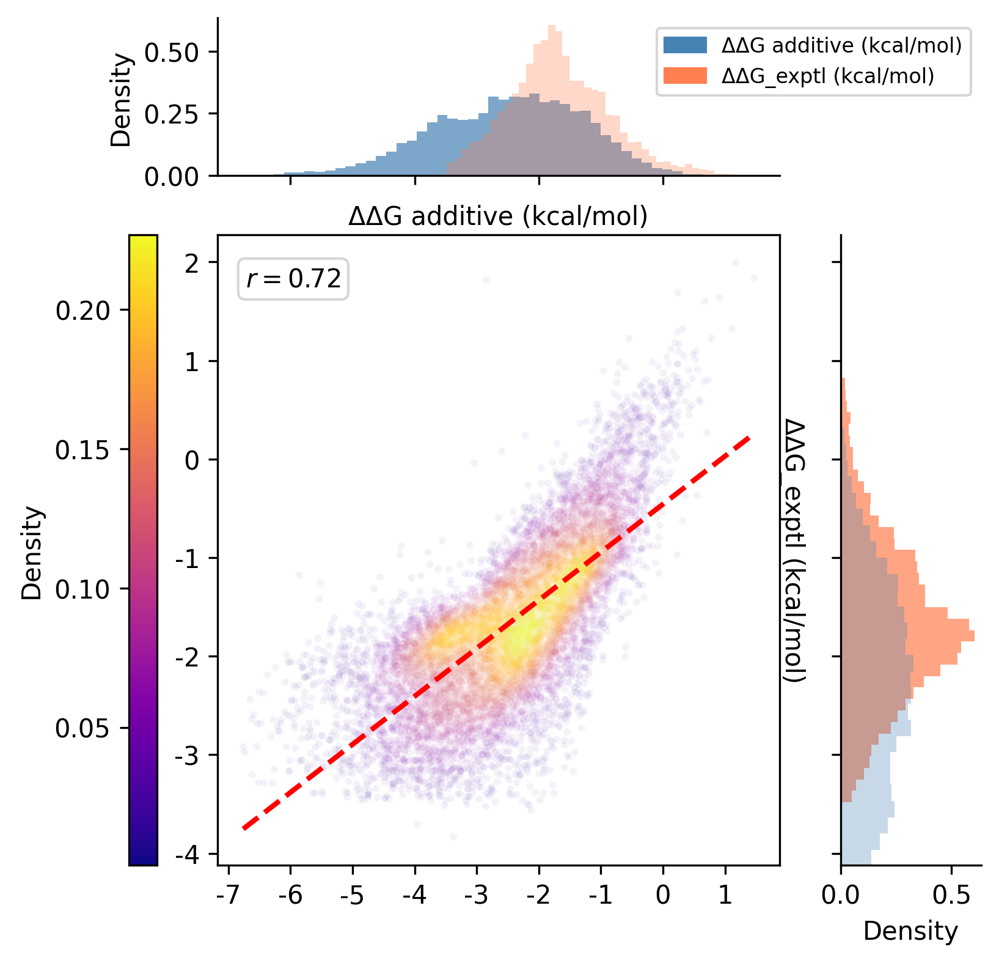

In [70]:
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score
import importlib
importlib.reload(analysis_utils_msr)

from analysis_utils_msr import density_scatter

df_dddG['ΔΔG_exptl (kcal/mol)'] = df_dddG['ddG']
df_dddG['ΔΔG additive (kcal/mol)'] = df_dddG['ddG_additive']
df_dddG_clean = df_dddG[['ΔΔG additive (kcal/mol)', 'ΔΔG_exptl (kcal/mol)']].dropna()

density_scatter(df_dddG_clean['ΔΔG additive (kcal/mol)'], df_dddG_clean['ΔΔG_exptl (kcal/mol)'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=False, stats=True)

f1 = f1_score(df_dddG_clean[['ΔΔG_exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG additive (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['ΔΔG_exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG additive (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['ΔΔG_exptl (kcal/mol)']]>0, df_dddG_clean[['ΔΔG additive (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG[['ΔΔG_exptl (kcal/mol)', 'ΔΔG additive (kcal/mol)']].corr('spearman'))

0.8865481676541584
0.021975124483200756
0.8236260452675948
                            ESM-MSR δΔΔG  -(ΔΔG additive) (kcal/mol)
ESM-MSR δΔΔG                    1.000000                    0.044459
-(ΔΔG additive) (kcal/mol)      0.044459                    1.000000


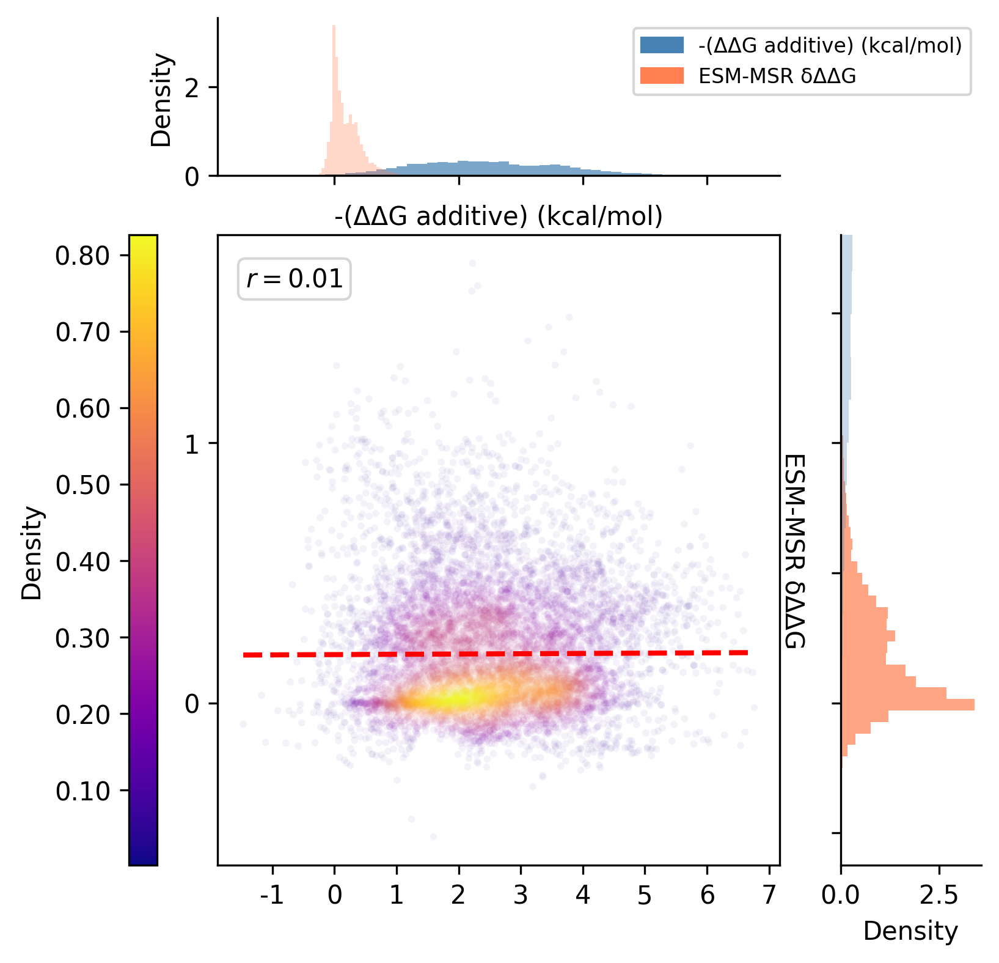

In [71]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'ESM-MSR_1_dddG']].dropna()

df_dddG_clean.rename(columns={'ESM-MSR_1_dddG': 'ESM-MSR δΔΔG'}, inplace=True)

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['ESM-MSR δΔΔG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=False, stats=True)

f1 = f1_score(df_dddG_clean[['ESM-MSR δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['ESM-MSR δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['ESM-MSR δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['ESM-MSR δΔΔG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.0021551724137931034
-0.050462645212836985
0.6350739852744998
                ESM-MSR_1_dddG  ddG_additive
ESM-MSR_1_dddG        1.000000     -0.284008
ddG_additive         -0.284008      1.000000


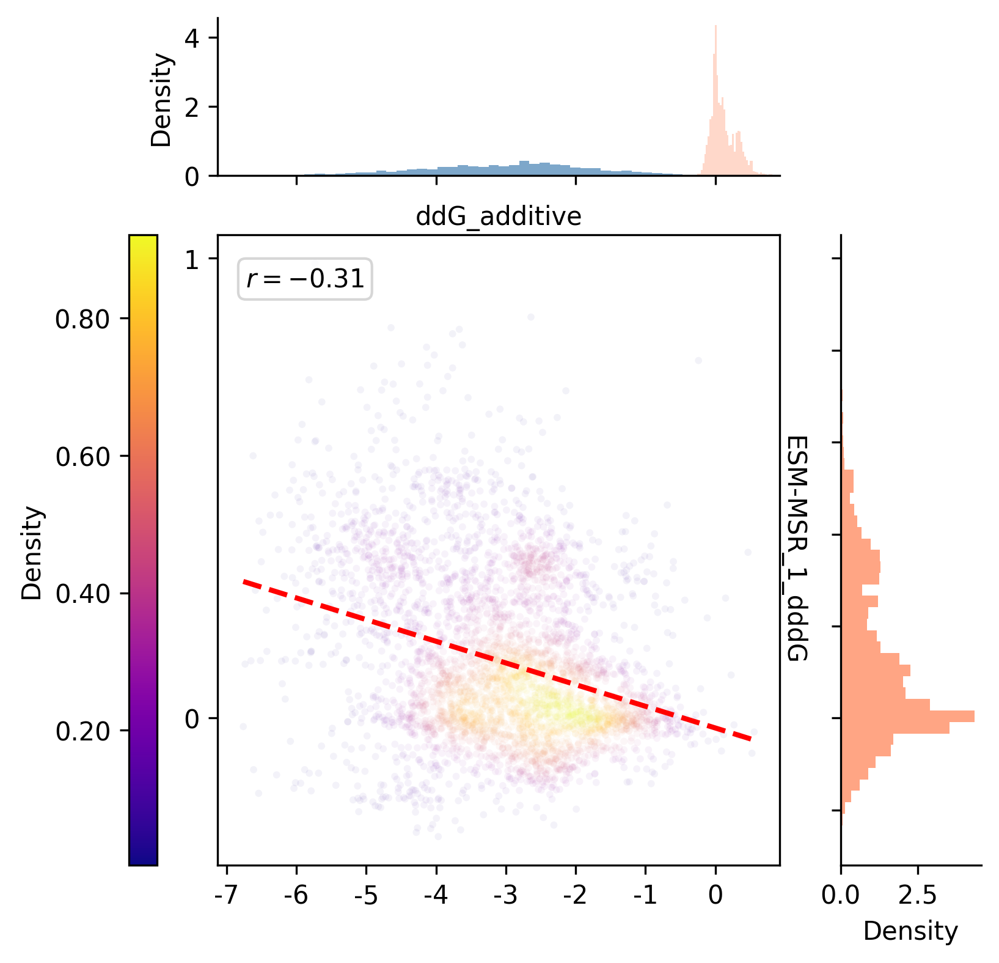

In [72]:
df_dddG_clean = df_dddG.reset_index()[['uid', 'ddG_additive', 'ESM-MSR_1_dddG']].dropna()
df_dddG_clean = df_dddG_clean.loc[df_dddG_clean['uid'].str.contains('3DKM')]

density_scatter(df_dddG_clean['ddG_additive'], df_dddG_clean['ESM-MSR_1_dddG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=True, stats=True)

f1 = f1_score(df_dddG_clean[['ESM-MSR_1_dddG']]>0, df_dddG_clean[['ddG_additive']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['ESM-MSR_1_dddG']]>0, df_dddG_clean[['ddG_additive']]>0)
auprc = average_precision_score(df_dddG_clean[['ESM-MSR_1_dddG']]>0, df_dddG_clean[['ddG_additive']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['ESM-MSR_1_dddG', 'ddG_additive']].corr('spearman'))

0.8126463700234192
0.012519190022803686
0.6944268110442708
                            ESM3-small-open_dddG  -(ΔΔG additive) (kcal/mol)
ESM3-small-open_dddG                    1.000000                    0.023902
-(ΔΔG additive) (kcal/mol)              0.023902                    1.000000


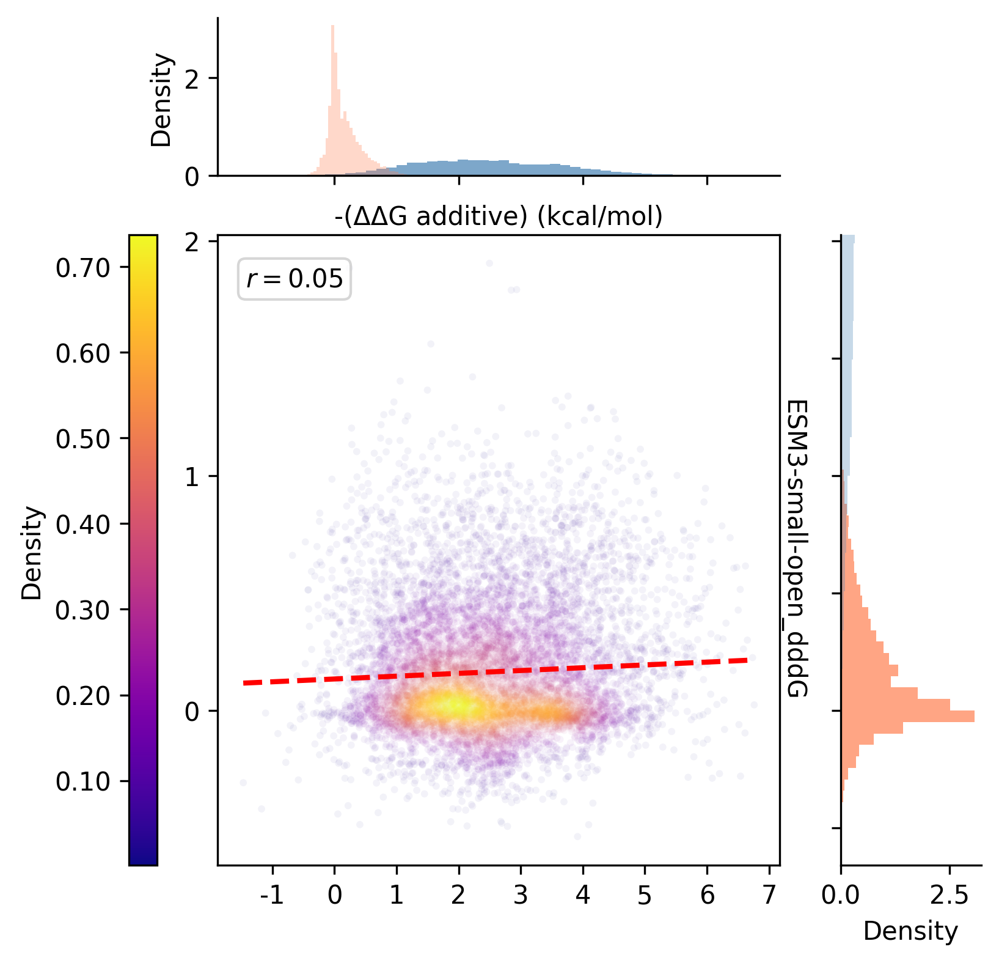

In [73]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'ESM3-small-open_dddG']].dropna()

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['ESM3-small-open_dddG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=True, stats=True)

f1 = f1_score(df_dddG_clean[['ESM3-small-open_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['ESM3-small-open_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['ESM3-small-open_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['ESM3-small-open_dddG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.8254924681344148
0.025411695643816436
0.7883545681879868
                              Rosetta Cartesian DDG_1_dddG  \
Rosetta Cartesian DDG_1_dddG                      1.000000   
-(ΔΔG additive) (kcal/mol)                        0.271463   

                              -(ΔΔG additive) (kcal/mol)  
Rosetta Cartesian DDG_1_dddG                    0.271463  
-(ΔΔG additive) (kcal/mol)                      1.000000  


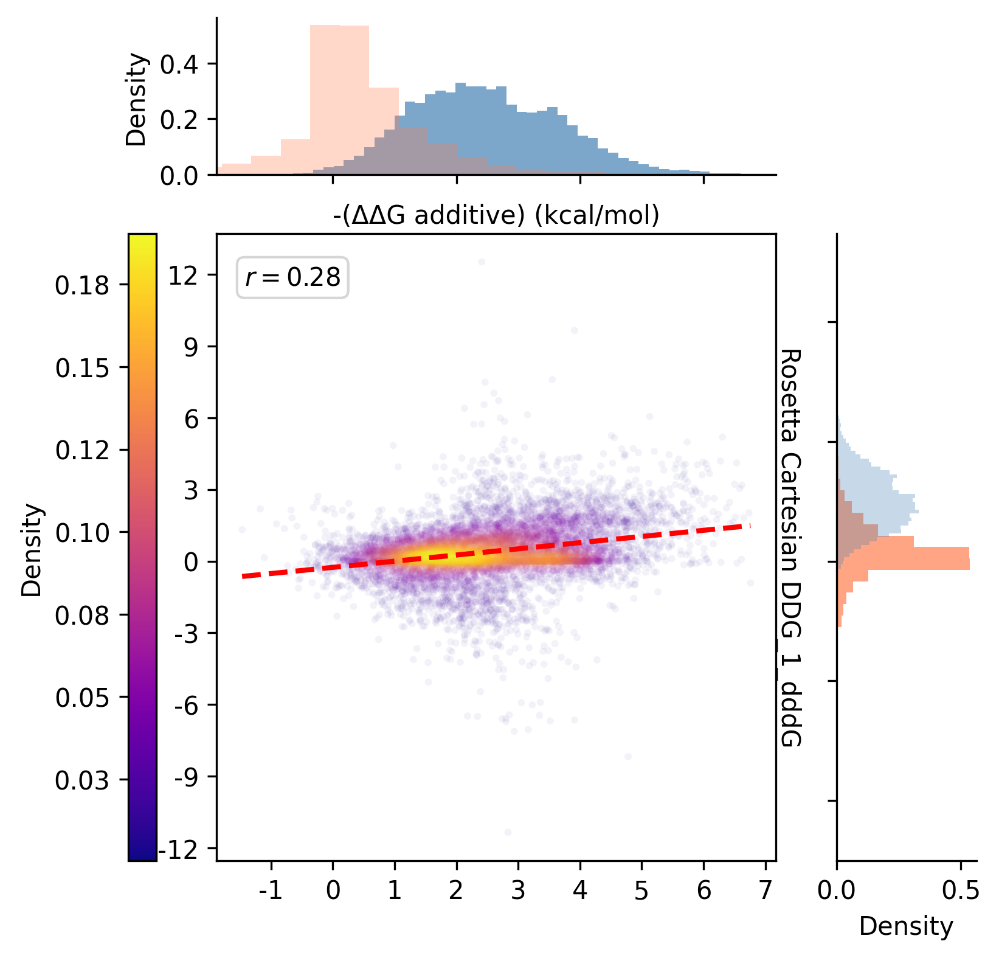

In [74]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'Rosetta Cartesian DDG_1_dddG']].dropna()

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['Rosetta Cartesian DDG_1_dddG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=True, stats=True)

f1 = f1_score(df_dddG_clean[['Rosetta Cartesian DDG_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['Rosetta Cartesian DDG_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['Rosetta Cartesian DDG_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['Rosetta Cartesian DDG_1_dddG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.9858452950558214
0.0013365264589851335
0.9921499071430948
                            Mutate Everything δΔΔG  -(ΔΔG additive) (kcal/mol)
Mutate Everything δΔΔG                    1.000000                    0.592346
-(ΔΔG additive) (kcal/mol)                0.592346                    1.000000


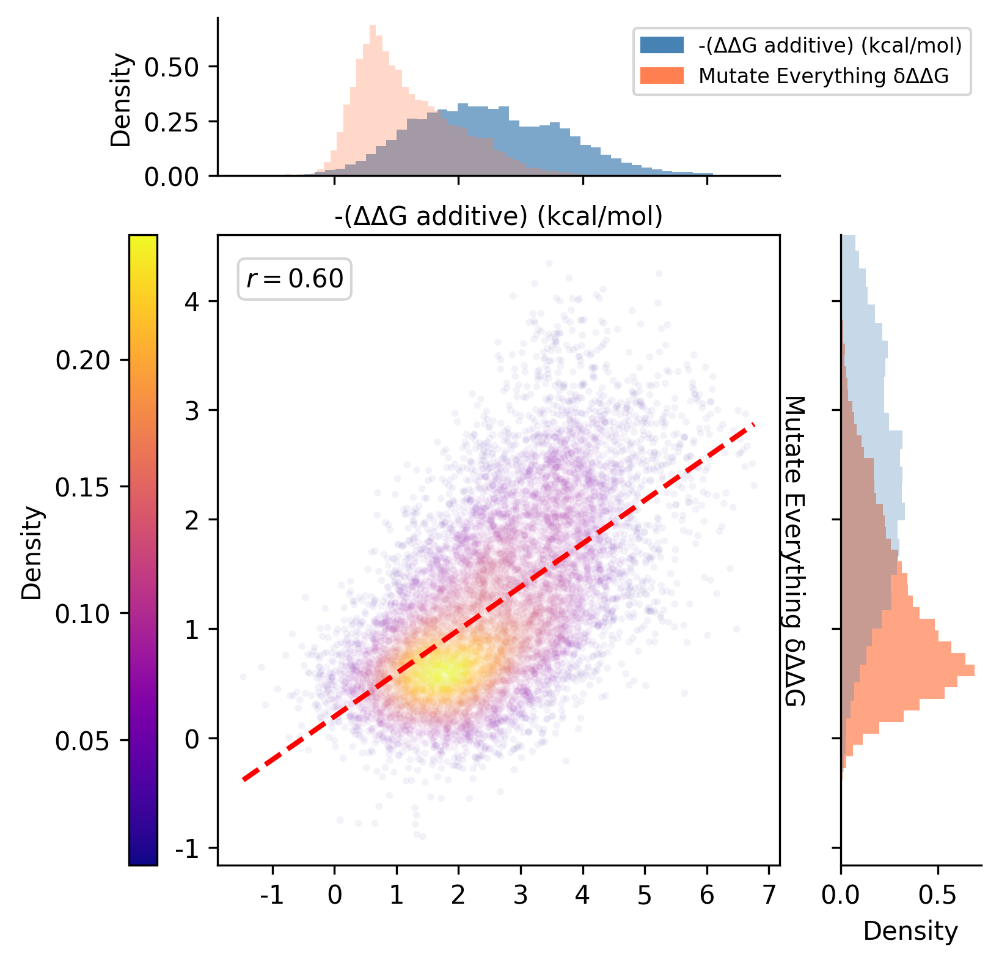

In [75]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'MutateEverything_1_dddG']].dropna()

df_dddG_clean.rename(columns={'MutateEverything_1_dddG': 'Mutate Everything δΔΔG'}, inplace=True)

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['Mutate Everything δΔΔG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=False, stats=True)

f1 = f1_score(df_dddG_clean[['Mutate Everything δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['Mutate Everything δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['Mutate Everything δΔΔG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['Mutate Everything δΔΔG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.9221785752202994
0.030652281271019856
0.841372677470533
                            ThermoMPNN(-D)_1_dddG  -(ΔΔG additive) (kcal/mol)
ThermoMPNN(-D)_1_dddG                    1.000000                    0.098784
-(ΔΔG additive) (kcal/mol)               0.098784                    1.000000


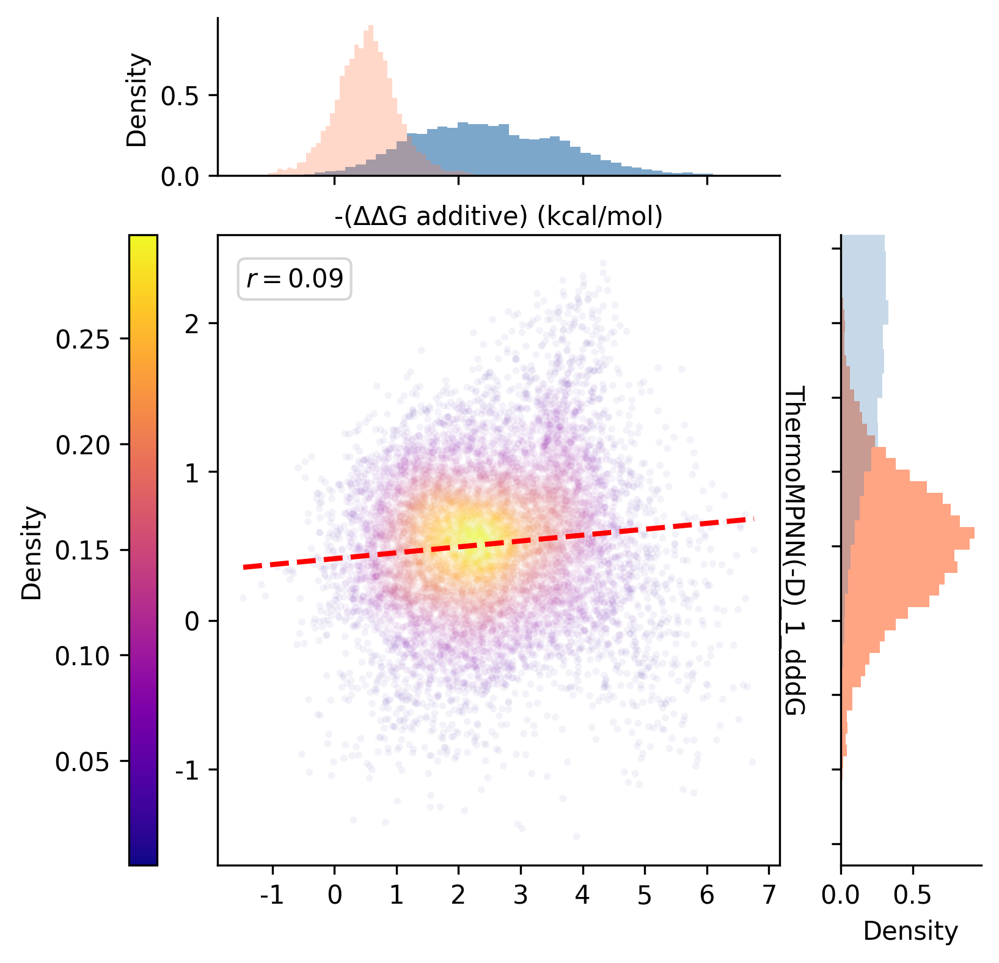

In [76]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'ThermoMPNN(-D)_1_dddG']].dropna()

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['ThermoMPNN(-D)_1_dddG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=True, stats=True)

f1 = f1_score(df_dddG_clean[['ThermoMPNN(-D)_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['ThermoMPNN(-D)_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['ThermoMPNN(-D)_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['ThermoMPNN(-D)_1_dddG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.7221203112151307
0.06651205144023743
0.6188149237687728
                            SPURS_1_dddG  -(ΔΔG additive) (kcal/mol)
SPURS_1_dddG                    1.000000                    0.173829
-(ΔΔG additive) (kcal/mol)      0.173829                    1.000000


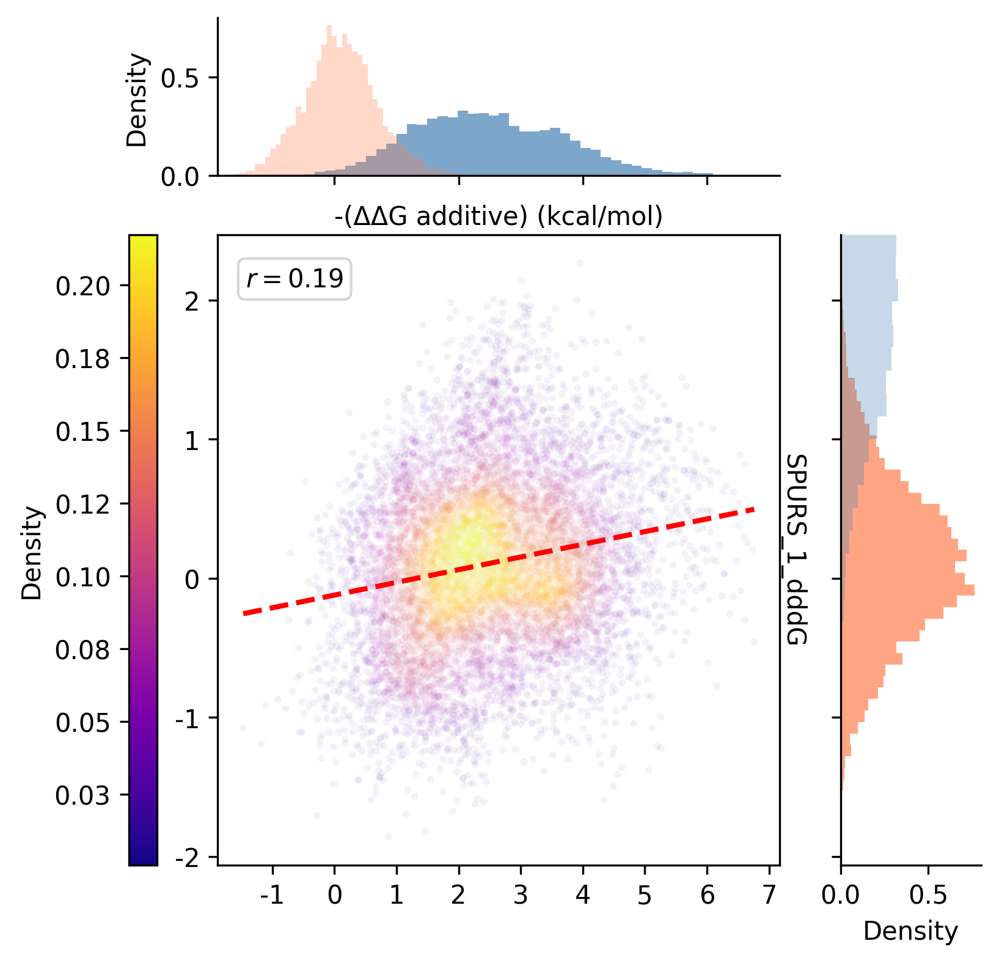

In [77]:
df_dddG_clean = df_dddG[['-(ΔΔG additive) (kcal/mol)', 'SPURS_1_dddG']].dropna()

density_scatter(df_dddG_clean['-(ΔΔG additive) (kcal/mol)'], df_dddG_clean['SPURS_1_dddG'], point_alpha=0.05, s=8, cmap="plasma", hide_marginal_legend=True, stats=True)

f1 = f1_score(df_dddG_clean[['SPURS_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['SPURS_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']]>0)
auprc = average_precision_score(df_dddG_clean[['SPURS_1_dddG']]>0, df_dddG_clean[['-(ΔΔG additive) (kcal/mol)']])

print(f1)
print(mcc)
print(auprc)
print(df_dddG_clean[['SPURS_1_dddG', '-(ΔΔG additive) (kcal/mol)']].corr('spearman'))

0.8557320483074543
0.17760663013624944
0.9251144430935825


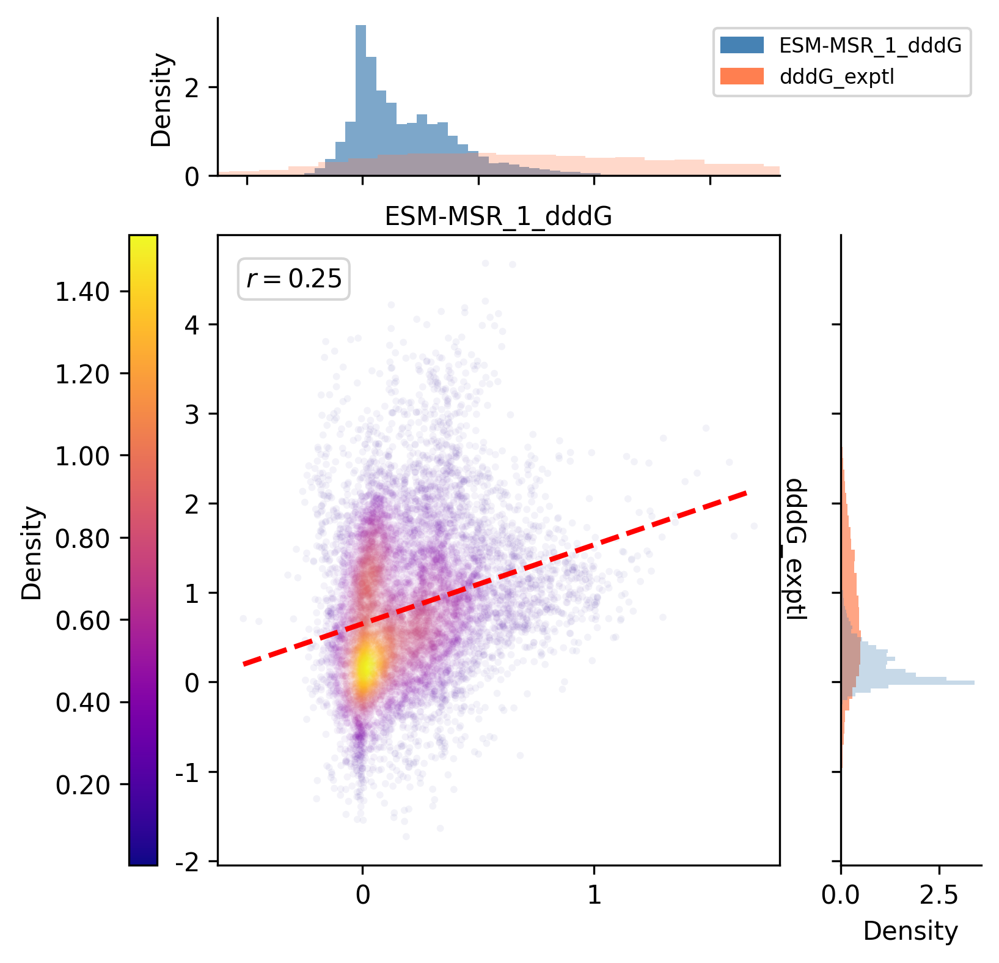

In [78]:
df_dddG['dddG_exptl'] = df_dddG['ddG_dddG']
df_dddG_clean = df_dddG[['dddG_exptl', 'ESM-MSR_1_dddG']].dropna()

density_scatter(df_dddG_clean['ESM-MSR_1_dddG'], df_dddG_clean['dddG_exptl'], point_alpha=0.05, s=8, cmap="plasma", stats=True)

f1 = f1_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']]>0)
auprc = average_precision_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ESM-MSR_1_dddG']])

print(f1)
print(mcc)
print(auprc)

0.9143470099222312
0.05398385659727765
0.9150860326826076


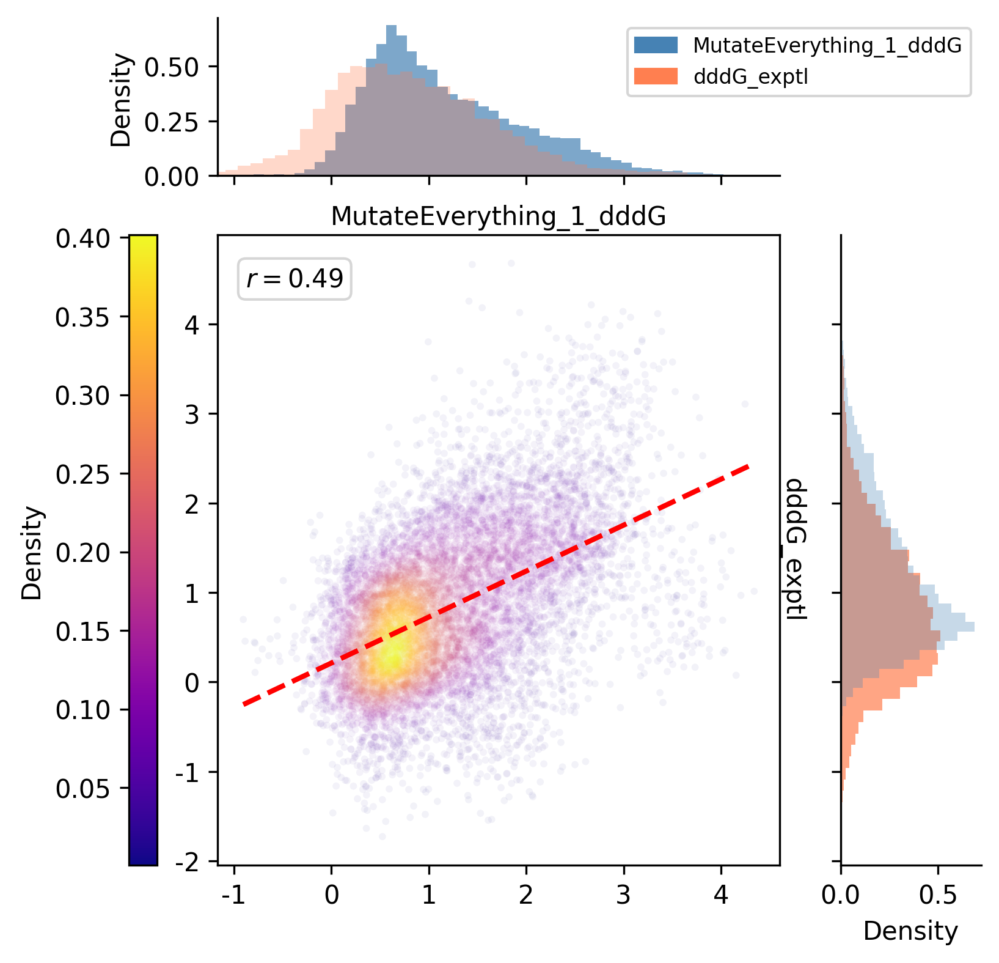

In [79]:
df_dddG['dddG_exptl'] = df_dddG['ddG_dddG']
df_dddG_clean = df_dddG[['dddG_exptl', 'MutateEverything_1_dddG']].dropna()

density_scatter(df_dddG_clean['MutateEverything_1_dddG'], df_dddG_clean['dddG_exptl'], point_alpha=0.05, s=8, cmap="plasma", stats=True)

f1 = f1_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['MutateEverything_1_dddG']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['MutateEverything_1_dddG']]>0)
auprc = average_precision_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['MutateEverything_1_dddG']])

print(f1)
print(mcc)
print(auprc)

0.8479246799471841
-0.05508657550430608
0.8722757114607005


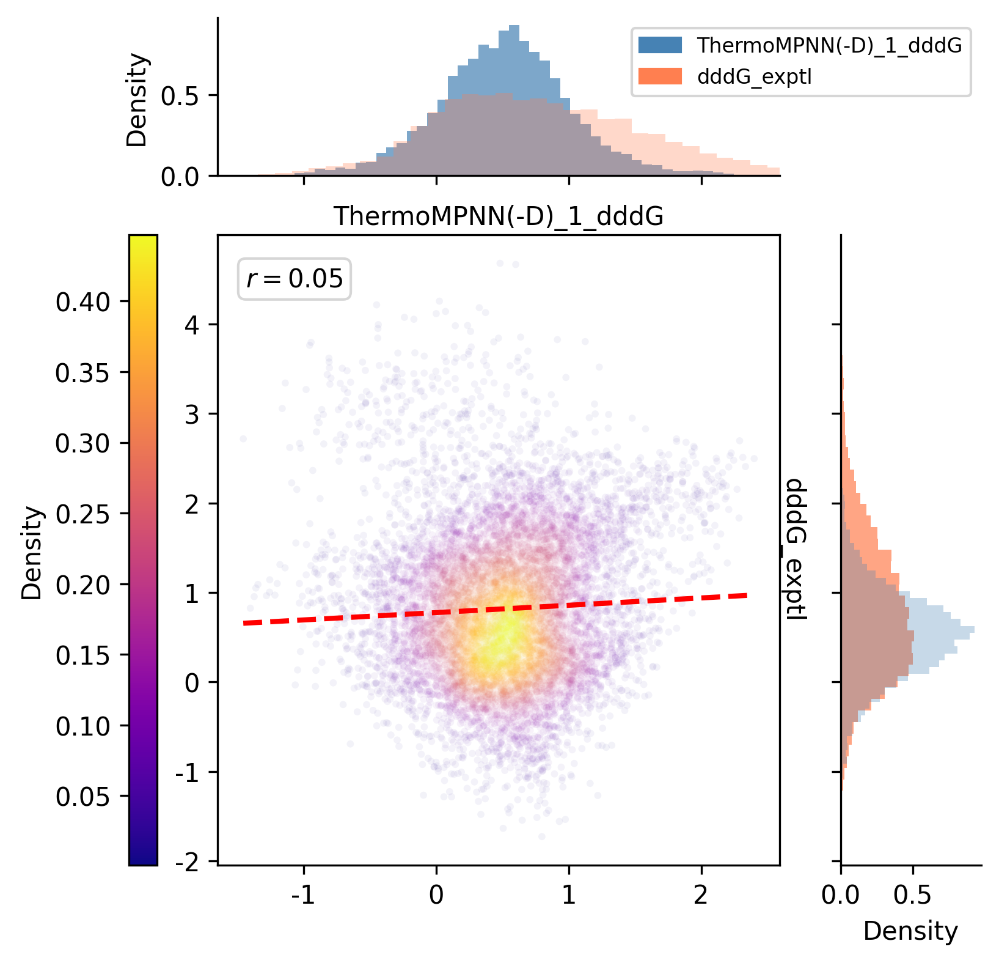

In [80]:
df_dddG['dddG_exptl'] = df_dddG['ddG_dddG']
df_dddG_clean = df_dddG[['dddG_exptl', 'ThermoMPNN(-D)_1_dddG']].dropna()

density_scatter(df_dddG_clean['ThermoMPNN(-D)_1_dddG'], df_dddG_clean['dddG_exptl'], point_alpha=0.05, s=8, cmap="plasma", stats=True)

f1 = f1_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ThermoMPNN(-D)_1_dddG']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ThermoMPNN(-D)_1_dddG']]>0)
auprc = average_precision_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['ThermoMPNN(-D)_1_dddG']])

print(f1)
print(mcc)
print(auprc)

0.686726893676164
0.035969454023520864
0.8368814386453162


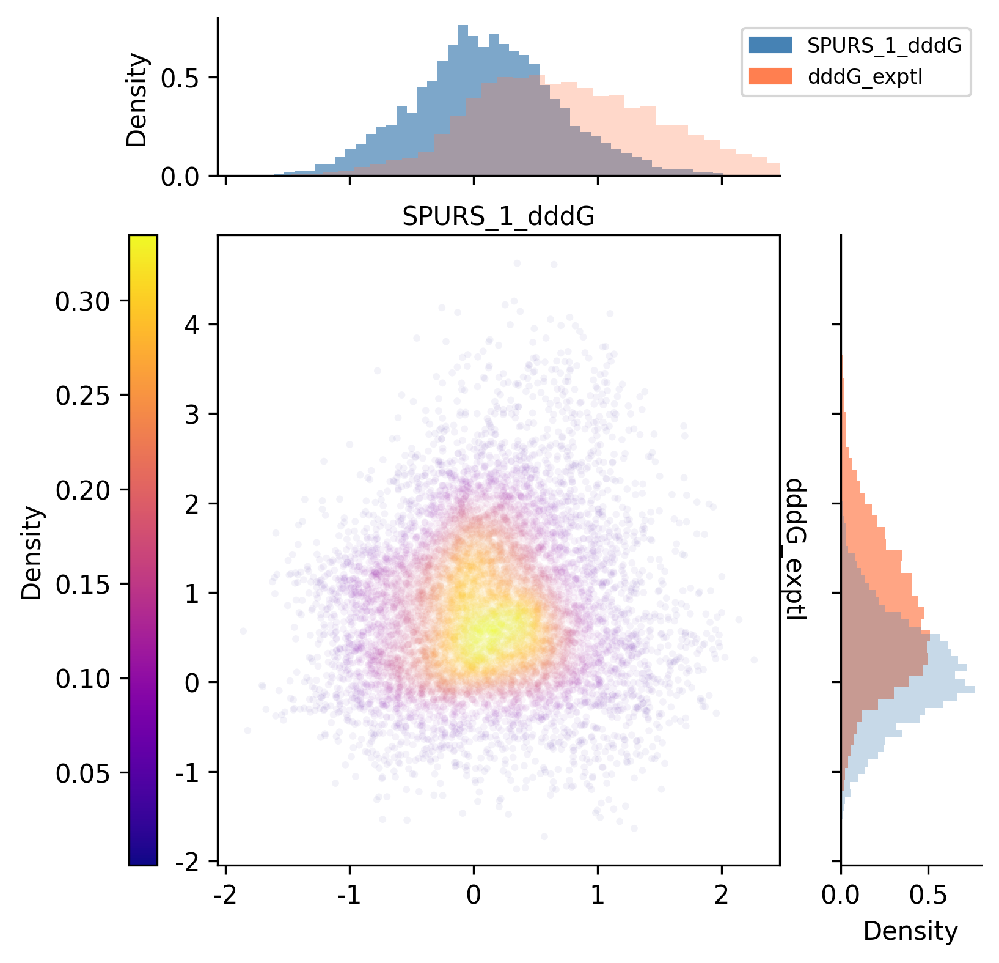

In [81]:
df_dddG['dddG_exptl'] = df_dddG['ddG_dddG']
df_dddG_clean = df_dddG[['dddG_exptl', 'SPURS_1_dddG']].dropna()

density_scatter(df_dddG_clean['SPURS_1_dddG'], df_dddG_clean['dddG_exptl'], point_alpha=0.05, s=8, cmap="plasma")

f1 = f1_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['SPURS_1_dddG']]>0)
mcc = matthews_corrcoef(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['SPURS_1_dddG']]>0)
auprc = average_precision_score(df_dddG_clean[['dddG_exptl']]>0, df_dddG_clean[['SPURS_1_dddG']])

print(f1)
print(mcc)
print(auprc)

In [82]:
df_dddG_clean = df_dddG[['ddG_dddG', 'ESM-MSR_1_dddG']].dropna()

tp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['ESM-MSR_1_dddG']>0)])
fp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['ESM-MSR_1_dddG']>0)])
tn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['ESM-MSR_1_dddG']<=0)])
fn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['ESM-MSR_1_dddG']<=0)])
print(tp, fp, tn, fn)
print(sum([tp, fp, tn, fn]))

7192 957 559 1468
10176


In [83]:
df_dddG_clean = df_dddG[['ddG_dddG', 'ThermoMPNN(-D)_1_dddG']].dropna()

tp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['ThermoMPNN(-D)_1_dddG']>0)])
fp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['ThermoMPNN(-D)_1_dddG']>0)])
tn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['ThermoMPNN(-D)_1_dddG']<=0)])
fn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['ThermoMPNN(-D)_1_dddG']<=0)])
print(tp, fp, tn, fn)
print(sum([tp, fp, tn, fn]))

7385 1374 142 1275
10176


In [84]:
df_dddG_clean = df_dddG[['ddG_dddG', 'MutateEverything_1_dddG']].dropna()

tp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['MutateEverything_1_dddG']>0)])
fp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['MutateEverything_1_dddG']>0)])
tn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['MutateEverything_1_dddG']<=0)])
fn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['MutateEverything_1_dddG']<=0)])
print(tp, fp, tn, fn)
print(sum([tp, fp, tn, fn]))

8524 1461 55 136
10176


In [85]:
df_dddG_clean = df_dddG[['ddG_dddG', 'SPURS_1_dddG']].dropna()

tp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['SPURS_1_dddG']>0)])
fp = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['SPURS_1_dddG']>0)])
tn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']<=0) & (df_dddG_clean['SPURS_1_dddG']<=0)])
fn = len(df_dddG_clean.loc[(df_dddG_clean['ddG_dddG']>0) & (df_dddG_clean['SPURS_1_dddG']<=0)])
print(tp, fp, tn, fn)
print(sum([tp, fp, tn, fn]))

4941 789 727 3719
10176


In [86]:
df_scores_dddG_combined[[c for c in df_scores_dddG_combined.columns if 'Negative' in c]]

Negative_additive  Negative_additive_n  \
hyperopt_splits-D-test ungrouped           0.704691         10176.000000   
                       grouped             0.507187          1453.714286   

                                  Negative_additive_groups  \
hyperopt_splits-D-test ungrouped                       NaN   
                       grouped                         7.0   

                                  Negative_additive_pos  \
hyperopt_splits-D-test ungrouped               0.702709   
                       grouped                 0.494798   

                                  Negative_additive_n_pos  \
hyperopt_splits-D-test ungrouped              8660.000000   
                       grouped                1237.142857   

                                  Negative_additive_groups_pos  \
hyperopt_splits-D-test ungrouped                           NaN   
                       grouped                             7.0   

                                  Negative_additive_neg  \
hyperopt_splits-D-test ungrouped               0.065148   
                       grouped                 0.140695   

                                  Negative_additive_n_neg  \
hyperopt_splits-D-test ungrouped              1516.000000   
                       grouped                 216.571429   

                                  Negative_additive_groups_neg  
hyperopt_splits-D-test ungrouped                           NaN  
                       grouped                             7.0

In [87]:
#df_scores_dddG = pd.read_csv('~/PSLMs/data/lora/test_scores_new.csv', index_col=[0,1])
df_dddG = df_epistatic.copy(deep=True)
df_dddG = compute_dddg(df_dddG)

df_dddG = df_dddG.loc[df_dddG.index.str.contains(':')].reset_index()
#df_dddG['code'] = df_dddG['uid'].apply(lambda x: x.split('_')[0])
df_dddG['pos1'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[0][1:-1]).astype(int)
df_dddG['pos2'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[1][1:-1]).astype(int)
#tmp = df_dddG.groupby(['code', 'pos1', 'pos2'])[[c for c in df_dddG.columns if 'dddG' in c]].corr('spearman')[['ddG_dddG']].reset_index().set_index(['code', 'pos1', 'pos2'])
#tmp.columns = ['model', 'spearman']
#tmp.pivot(columns='model').mean()
tmp = df_dddG.groupby(['code', 'pos1', 'pos2'])[[c for c in df_dddG.columns if 'dddG' in c]].count()[['ddG_dddG']]
tmp2 = df_dddG.groupby(['code', 'pos1', 'pos2'])[[c for c in df_dddG.columns if 'dddG' in c]].corr('spearman').loc[slice(None), slice(None), slice(None), 'ddG_dddG', :]

tmp.rename({'ddG_dddG': 'dddG_ct'}, axis=1).join(tmp2).sort_values('dddG_ct', ascending=False).to_csv('doubles_count.csv')

In [88]:
df_dddG = df_epistatic.copy(deep=True)
df_dddG = compute_dddg(df_dddG)

df_dddG = df_dddG.loc[df_dddG.index.str.contains(':')].reset_index()
df_dddG['code'] = df_dddG['uid'].apply(lambda x: x.split('_')[0])
df_dddG['pos1'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[0][1:-1]).astype(int)
df_dddG['pos2'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[1][1:-1]).astype(int)
df_dddG['mut1'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[0][-1]).astype(str)
df_dddG['mut2'] = df_dddG['mut_type'].apply(lambda x: x.split(':')[1][-1]).astype(str)
tmp = df_dddG.drop(['uid', 'mut_type'], axis=1)
pt = tmp.pivot_table(index=['code', 'pos1', 'pos2', 'mut1'], columns=['mut2'])
pt

ESM-MSR_1                                          \
mut2                        A         C         D         E         F   
code pos1 pos2 mut1                                                     
1UFM 14   49   A    -0.946700       NaN -1.142066 -0.664276 -1.097006   
               D    -1.491035       NaN -1.705442 -1.345032 -1.717735   
               F    -0.699530       NaN -0.892851 -0.374133 -0.685365   
               G    -1.693373       NaN -1.896229 -1.459130 -1.837468   
               H    -1.197268       NaN -1.373101 -0.866806 -1.401109   
...                       ...       ...       ...       ...       ...   
HHH  36   39   S    -1.705522       NaN -3.451285 -2.318321 -1.848259   
               T    -1.848923       NaN -3.577261 -2.465251 -2.000233   
               V    -1.707645 -1.526835 -3.487161 -2.366038 -1.821776   
               W    -1.317988 -1.135861 -3.101298 -2.026139 -1.256984   
               Y    -1.459358 -1.284405       NaN -2.141050 -1.458043   

                                                                       ...  \
mut2                        G         H         I         K         L  ...   
code pos1 pos2 mut1                                                    ...   
1UFM 14   49   A    -1.701064 -1.311498 -1.042175 -1.007822 -0.905346  ...   
               D    -2.205326 -1.808620 -1.609154 -1.462998 -1.473486  ...   
               F    -1.463000 -0.957274 -0.607270 -0.713460 -0.495390  ...   
               G    -2.425044 -2.032115 -1.786137 -1.715245 -1.656284  ...   
               H    -1.920274 -1.549957 -1.272144 -1.233850 -1.144418  ...   
...                       ...       ...       ...       ...       ...  ...   
HHH  36   39   S    -3.051475 -2.137596 -1.564148 -0.934878 -1.317605  ...   
               T    -3.166781 -2.308457 -1.722954 -1.093272 -1.464857  ...   
               V    -3.025181 -2.192027 -1.584770 -1.028016 -1.287645  ...   
               W    -2.630486 -1.760810 -1.212023 -0.573470 -0.883104  ...   
               Y    -2.782609 -1.926006 -1.335333 -0.727803 -0.969026  ...   

                     random_3                                          \
mut2                        M         N         P         Q         R   
code pos1 pos2 mut1                                                     
1UFM 14   49   A     0.388929  0.454416  0.069243       NaN  0.081312   
               D     0.248234  0.184785  0.052267       NaN  0.885225   
               F     0.778811  0.699367  0.662565       NaN  0.205060   
               G     0.145198  0.838044  0.771332       NaN  0.050967   
               H     0.596266  0.429206  0.796377       NaN  0.486765   
...                       ...       ...       ...       ...       ...   
HHH  36   39   S     0.018956  0.679660       NaN  0.844981       NaN   
               T     0.065255  0.675626  0.318234  0.057711       NaN   
               V     0.335424  0.539194       NaN  0.363583       NaN   
               W     0.531723  0.122961  0.334220  0.532240       NaN   
               Y     0.827830  0.129846  0.996037  0.428797       NaN   

                                                                       
mut2                        S         T         V         W         Y  
code pos1 pos2 mut1                                                    
1UFM 14   49   A     0.329908  0.982890  0.935111  0.531080  0.125625  
               D     0.616342  0.966923  0.384089  0.821482  0.701893  
               F     0.687481  0.062241  0.683645  0.301806  0.979835  
               G     0.426549  0.753752  0.597092  0.751425  0.062420  
               H     0.012948  0.633426  0.313539  0.589962  0.436538  
...                       ...       ...       ...       ...       ...  
HHH  36   39   S     0.926526  0.285959  0.908483  0.594028  0.701659  
               T     0.690109  0.803142  0.720615  0.516664  0.207139  
               V     0.621297  0.461577  0.496700  0.223569  0.229424  
               W 

In [89]:
pt.reset_index().groupby(['code', 'pos1', 'pos2']).count()

mut1 ESM-MSR_1                                  ... random_3  \
mut2                        A   C   D   E   F   G   H   I   K  ...        M   
code pos1 pos2                                                 ...            
1UFM 14   49     18        18   0  18  18  18  18  18  18  18  ...       18   
          53     18        18   0  18   0  18  18  18  18  18  ...       18   
          55     18        18   0  18  18  18  18  18  18  18  ...       18   
     49   53     18        18   0  18   0  18  18  18  18  18  ...       18   
          55     18        18   0  18  18  18  18  18  18  18  ...       18   
     53   55     18        18   0  18  18  18  18  18  18  18  ...       18   
2RU9 10   42     19        16  17  16   0  18  17  17  16  18  ...       16   
3DKM 15   36     18        13   0   7   8  16  10  12  16  14  ...       14   
          51     18        15   0   0  12  18  11  16  17  14  ...       15   
     18   26     18        18   0   0  18  18  18  17  18  17  ...       18   
          28     19        19  19   0  19  19  19  19  19  19  ...       19   
     21   65     19        19  19  15  19  19  18  19  19   0  ...       19   
     24   59     18        12   0   2   2  16   0  16   3  18  ...       13   
          63     18        18   0  18   0  18  18  18   2  10  ...       18   
          67     18        11   0   0  18  18   1  10  14   1  ...       16   
     26   28     18        18   0   0  18  18  18  18  18  18  ...       18   
     27   50      6         0   0   0   0   4   0   0   2   0  ...        0   
          56     19        19  19  19  19  19  19  19  19  19  ...       19   
          58     18        18   0   0  18  18   1  18  17   2  ...       18   
     36   51     18        13   0   0  14  17   7  12  17   9  ...       11   
     50   58      1         0   0   0   0   0   0   0   0   0  ...        1   
     59   63     18        10   0  14   0  18  15  12  14   8  ...       13   
          65     19        16  19  13  16  19  15  18  19   0  ...       19   
          67     19        19  19   0  19  19  16  19  19  19  ...       19   
     63   67     18        11   0   0  17  18   3  14  17  13  ...       16   
6M3N 2    63     19        19  19  19  19  19  19   0  19  19  ...       19   
     4    49     19        19  19  19  19  19  19  19  19   0  ...       19   
     18   39     19        19  19  19  19  18  19  19  19  19  ...       19   
          58     19        19  19  19  19  19  19  19  19  19  ...       19   
     25   63     19        19  19  19  19  19  19   0  19  19  ...       19   
     29   45     19        19  19  19   0  19  19  19  19  19  ...       19   
     45   49     19        19  19  19  19  19  19  19  19   0  ...       19   
HHH  10   36     19        19  16  17   0  19  17  19  19  19  ...       19   
          41     19        19  13  19   0  19  19  19  19  19  ...       18   
     17   20     19        18  11  18   0  18  12  18  18  17  ...       18   
     31   34     19        19  11  19   0  11  19  13  19   2  ...       17   
     36   39     19        18  12  17  18  17  19  19  18  19  ...       18   

                                                    
mut2             N   P   Q   R   S   T   V   W   Y  
code pos1 pos2                                      
1UFM 14   49    18  18   0  18  18  18  18  18  18  
          53    18  18  18  18  18  18  18  18  18  
          55    18  18  18   0  18  18  18  18  18  
     49   53    18  18  18  18  18  18  18  17  17  
          55    18  18  18   0  18  18  18  18  18  
     53   55    18  18  18   0  18  18  18  18  18  
2RU9 10   42    16  14  16  18  16  17  16  18  17  
3DKM 15   36     6   9  12  17   9   0  16  17  15  
          51    15   7  13  13  14  15  17  18  18  
     18   26    18  17  17  17  18  18  18  18  18  
          28    19  19  19  19  19  19  18  19  19  
     21   65    19  13  19  19  19  19  19  19  19  
     24   59     5   0  11   0   8   4   1  18  18  
      

In [90]:
pt.loc[('6M3N', 2, 63),('ESM-MSR_1', slice(None))]

ESM-MSR_1                                                        \
mut2         A         C         D         E         F         G   H   
mut1                                                                   
A    -1.837411 -0.929192 -2.207399 -2.118611 -0.581581 -2.155990 NaN   
C    -0.967350  0.245698 -1.403912 -1.315081 -0.037506 -1.210596 NaN   
D    -1.901483 -1.164637 -2.374108 -2.268056 -1.203287 -2.193590 NaN   
E    -2.031019 -1.274418 -2.487958 -2.409685 -1.335363 -2.295094 NaN   
G    -1.859451 -0.977921 -2.188890 -2.124440 -1.013927 -2.135119 NaN   
H    -1.632486 -0.885019 -1.976562 -1.931426 -0.769170 -1.957500 NaN   
I    -1.058867 -0.377966 -1.596504 -1.435445 -0.051184 -1.517403 NaN   
K    -1.887890 -1.139706 -2.149115 -2.095739 -1.229684 -2.197456 NaN   
L    -1.341055 -0.567925 -1.853646 -1.670067 -0.345428 -1.723747 NaN   
M    -1.587322 -0.752959 -2.005337 -1.862953 -0.409646 -1.912168 NaN   
N    -1.826833 -1.077830 -2.198525 -2.156142 -1.150589 -2.129834 NaN   
P    -1.706575 -0.848108 -2.059087 -1.967787 -0.758656 -2.008790 NaN   
Q    -1.877383 -1.140350 -2.250597 -2.213891 -1.112841 -2.173251 NaN   
R    -1.858660 -1.083238 -1.941061 -2.025123 -1.197674 -2.139383 NaN   
S    -1.760168 -0.942884 -2.100166 -2.052981 -0.933244 -2.056355 NaN   
T    -1.737202 -0.871880 -2.039732 -2.008641 -0.874297 -2.026620 NaN   
V    -1.249109 -0.476677 -1.745911 -1.591878 -0.062116 -1.700077 NaN   
W    -0.401397  0.294434 -1.156206 -0.892476  0.487747 -0.804827 NaN   
Y    -0.809733 -0.256355 -1.458940 -1.209702 -0.047840 -1.254752 NaN   

                                                                            \
mut2         I         K         L         M         N         P         Q   
mut1                                                                         
A    -1.002032 -1.944044 -1.236323 -1.424228 -1.903953 -2.055770 -1.872532   
C    -0.407905 -1.070376 -0.568530 -0.708778 -1.130368 -1.179866 -1.105881   
D    -1.418218 -2.024025 -1.561846 -1.745664 -2.127847 -2.020535 -2.070095   
E    -1.599819 -2.020119 -1.729758 -1.891136 -2.182020 -2.137582 -2.120405   
G    -1.335373 -1.994739 -1.509492 -1.655819 -1.949524 -2.023808 -1.936387   
H    -1.096508 -1.723922 -1.241933 -1.408942 -1.766612 -1.912156 -1.695960   
I    -0.234477 -1.222466 -0.559395 -0.659860 -1.269934 -1.513375 -1.142494   
K    -1.425500 -2.065633 -1.618094 -1.754883 -2.010461 -2.077238 -2.043273   
L    -0.570124 -1.526013 -0.698175 -0.936734 -1.539627 -1.701063 -1.423378   
M    -0.836921 -1.706825 -1.021266 -1.195140 -1.694142 -1.856536 -1.617776   
N    -1.365981 -1.983447 -1.520113 -1.663120 -1.932654 -2.025689 -1.919303   
P    -1.146722 -1.831341 -1.303097 -1.455273 -1.813827 -1.855330 -1.790005   
Q    -1.384554 -1.999471 -1.529623 -1.673425 -1.942155 -2.058097 -1.953193   
R    -1.403984 -2.062393 -1.570070 -1.713707 -1.927097 -2.026566 -1.998247   
S    -1.233776 -1.866286 -1.405550 -1.555615 -1.838858 -1.943306 -1.833086   
T    -1.141919 -1.774388 -1.386576 -1.491541 -1.729292 -1.961852 -1.726927   
V    -0.309107 -1.397653 -0.684072 -0.784835 -1.425869 -1.660333 -1.308493   
W     0.101053 -0.488673  0.195349 -0.052284 -0.584439 -0.759978 -0.438789   
Y    -0.314017 -0.858953 -0.411082 -0.512066 -1.113229 -1.221863 -0.932583   

                                                                  
mut2         R         S         T         V         W         Y  
mut1                                                              
A    -1.681574 -1.846827 -1.654992 -1.217735 -0.704801 -0.737976  
C    -0.844743 -0.975597 -0.851479 -0.523173 -0.139922 -0.132424  
D    -1.852730 -1.980910 -1.849793 -1.512752 -1.218397 -1.149461  
E    -1.784280 -2.067564 -1.950321 -1.677245 -1.365383 -1.268615  
G    -1.723199 -1.877282 -1.737169 -1.433712 -0.998553 -1.027735  
H    -1.505486 -1.580268 -1.416440 -1.185642 -0.853111 -0.801519  
I    -0.987963 -1.133798 -0.939018 -0.418091 -0.062584 -0.100762  
K    -1.851895 -1.904006 -1.75255

In [91]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

# 20 canonical amino acids (1-letter)
AA  = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
IDX = {aa:i for i,aa in enumerate(AA)}
POS = {'K','R','H'}
NEG = {'D','E'}

def plot_joint_with_marginals(
    P, PA, PB, aa_labels, *,
    cmap='viridis',
    vmin=None, vmax=None,
    pos1=0, pos2=0
):
    n = len(aa_labels)
    
    # --- Input Validation ---
    P = np.asarray(P)
    PA = np.asarray(PA).squeeze()
    PB = np.asarray(PB).squeeze()
    
    if P.shape != (n, n):
        raise AssertionError(f"Heatmap P shape {P.shape} does not match aa_labels dimensions ({n}, {n})")
    if PA.shape != (n,):
        raise AssertionError(f"Marginal PA shape {PA.shape} does not match aa_labels length ({n},)")
    if PB.shape != (n,):
        raise AssertionError(f"Marginal PB shape {PB.shape} does not match aa_labels length ({n},)")
        
    if np.all(np.isnan(PA)):
        raise AssertionError("Marginal PA contains only NaN values. Cannot compute axis limits.")
    if np.all(np.isnan(PB)):
        raise AssertionError("Marginal PB contains only NaN values. Cannot compute axis limits.")
    # ------------------------
    
    # 1. Main Plot
    fig, ax_main = plt.subplots(figsize=(9., 8.))
    
    im = ax_main.imshow(P, origin='lower', interpolation='nearest',
                        cmap=cmap, vmin=vmin, vmax=vmax, aspect='equal')
    
    ax_main.set_xticks([])
    ax_main.set_yticks([])
    ax_main.grid(False)
    
    # Cast pos1/pos2 to strings to prevent backend formatting errors
    ax_main.set_xlabel(str(pos2), rotation=0, fontsize=16)
    ax_main.set_ylabel(str(pos1), rotation=90, fontsize=16)

    # Annotate identities
    for i in range(n):
        ax_main.text(i, i, aa_labels[i], ha='center', va='center', fontsize=16, color='red')

    # 2. Divider for Marginals
    divider = make_axes_locatable(ax_main)
    
    # Append Top Axis
    ax_top = divider.append_axes("top", size="20%", pad=0.1, sharex=ax_main)
    
    # Append Right Axis
    ax_right = divider.append_axes("right", size="20%", pad=0.1, sharey=ax_main)
    
    # Append Colorbar Axis (Increased pad to 0.7 to clear the y-axis label)
    ax_cbar = divider.append_axes("left", size="5%", pad=0.4)

    extra = 0.2

    # --- 3. Top marginal P(B) ---
    pb = PB
    ax_top.bar(range(n), pb, align='center')
    ax_top.set_xlim(-0.5, n-0.5)
    # Use nanmin/nanmax to ignore NaNs
    ax_top.set_ylim(np.nanmin(pb) - extra, np.nanmax(pb) + extra)
    
    # Visuals: Add "add. score" and ticks
    ax_top.set_ylabel("add. score", fontsize=12)
    ax_top.tick_params(axis='y', labelsize=16)      # Uniform text size
    ax_top.tick_params(axis='x', labelbottom=False)
    ax_top.grid(False)
    ax_top.spines['top'].set_visible(False)
    ax_top.spines['right'].set_visible(False)

    # --- 4. Right marginal P(A) ---
    pa = PA
    ax_right.barh(range(n), pa, align='center')
    ax_right.set_ylim(-0.5, n-0.5)
    # Use nanmin/nanmax to ignore NaNs
    ax_right.set_xlim(np.nanmin(pa) - extra, np.nanmax(pa) + extra)
    
    # Visuals: Add "add. score" and ticks
    ax_right.set_xlabel("add. score", fontsize=12)
    ax_right.tick_params(axis='x', labelsize=16)    # Uniform text size
    ax_right.tick_params(axis='y', labelleft=False)
    ax_right.grid(False)
    ax_right.spines['top'].set_visible(False)
    ax_right.spines['right'].set_visible(False)

    # --- 5. Colorbar ---
    cbar = fig.colorbar(im, cax=ax_cbar)
    cbar.ax.yaxis.set_ticks_position('left')
    cbar.ax.yaxis.set_label_position('left')
    cbar.ax.tick_params(length=3, labelsize=16)
    
    # Lock format to prevent bounding box shifts, 1 decimal place
    cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

    return fig

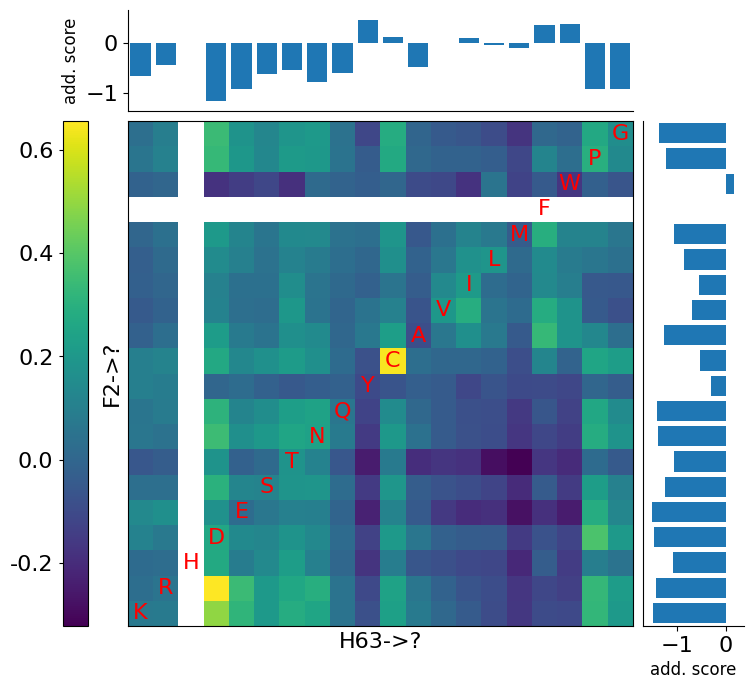

In [92]:
p = df_epistatic.loc[~df_epistatic.index.str.contains(':')]
p = p.loc[p['code']=='6M3N']
p['mutation'] = p['mut_type'].apply(lambda x: x[-1])

PA = p.loc[p['mut_type'].apply(lambda x: int(x[1:-1]))==2]
PA = PA.set_index('mutation')
PA.loc['F', :] = np.nan
PA = PA.loc[AA]

PB = p.loc[p['mut_type'].apply(lambda x: int(x[1:-1]))==63]
PB = PB.set_index('mutation')
PB.loc['H', :] = np.nan
PB = PB.loc[AA]

p_test_double = pt.loc[('6M3N', 2, 63), ('ESM-MSR_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['ESM-MSR_1']
pb = PB['ESM-MSR_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

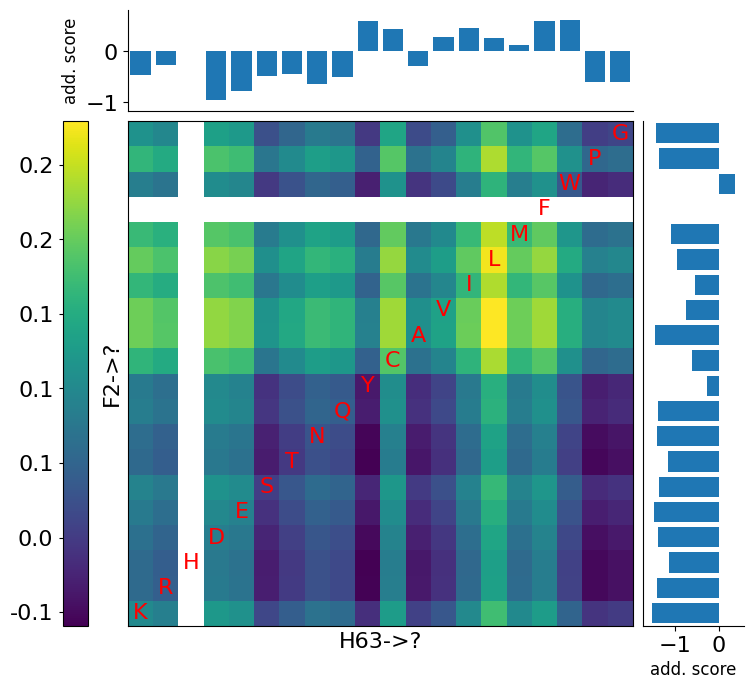

In [93]:
p = df_epistatic.loc[~df_epistatic.index.str.contains(':')]
p = p.loc[p['code']=='6M3N']
p['mutation'] = p['mut_type'].apply(lambda x: x[-1])

PA = p.loc[p['mut_type'].apply(lambda x: int(x[1:-1]))==2]
PA = PA.set_index('mutation')
PA.loc['F', :] = np.nan
PA = PA.loc[AA]

PB = p.loc[p['mut_type'].apply(lambda x: int(x[1:-1]))==63]
PB = PB.set_index('mutation')
PB.loc['H', :] = np.nan
PB = PB.loc[AA]

p_test_double = pt.loc[('6M3N', 2, 63), ('ESM-MSR_masked_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['ESM-MSR_masked_1']
pb = PB['ESM-MSR_masked_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

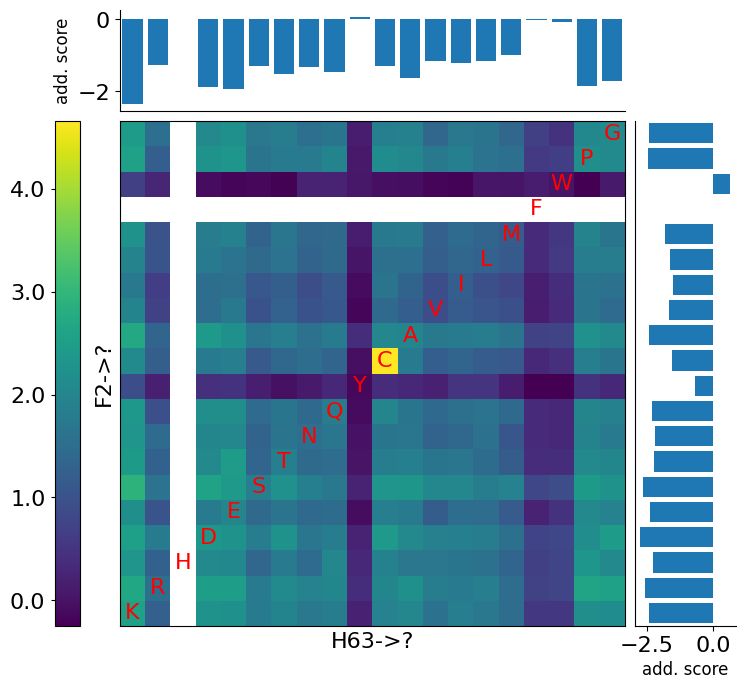

In [94]:
p_test_double = pt.loc[('6M3N', 2, 63), ('ddG_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['ddG']
pb = PB['ddG']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

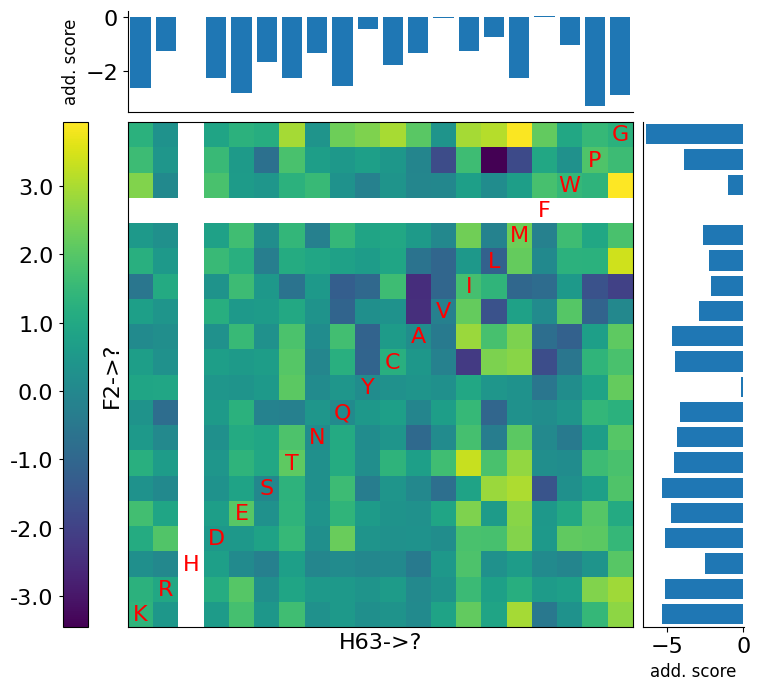

In [95]:
p_test_double = pt.loc[('6M3N', 2, 63), ('Rosetta Cartesian DDG_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['Rosetta Cartesian DDG_1']
pb = PB['Rosetta Cartesian DDG_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

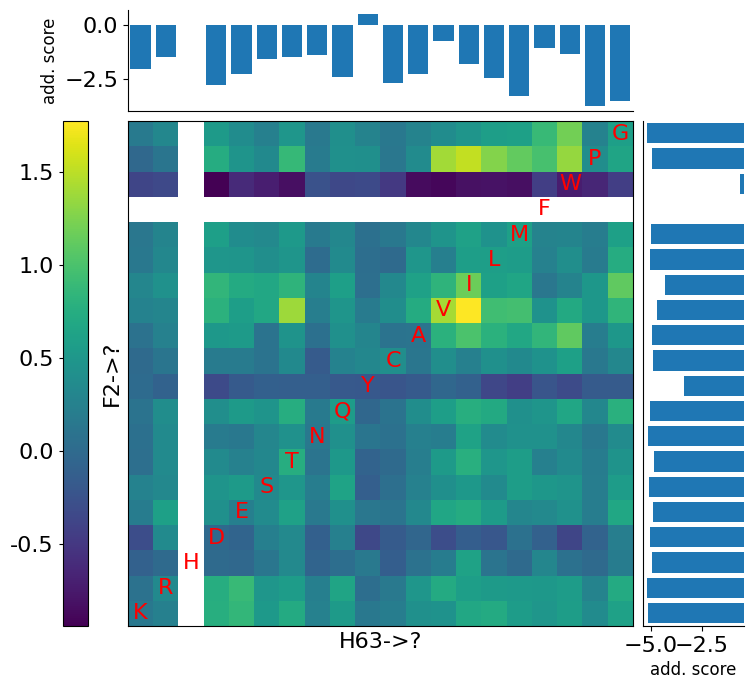

In [96]:
p_test_double = pt.loc[('6M3N', 2, 63), ('ProteinMPNN_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['ProteinMPNN']
pb = PB['ProteinMPNN']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

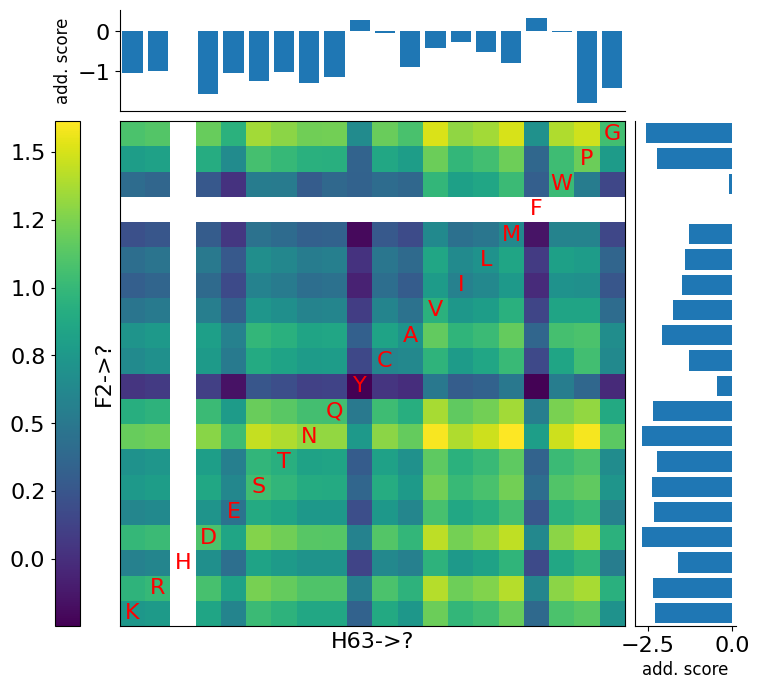

In [97]:
p_test_double = pt.loc[('6M3N', 2, 63), ('ThermoMPNN(-D)_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['ThermoMPNN(-D)_1']
pb = PB['ThermoMPNN(-D)_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

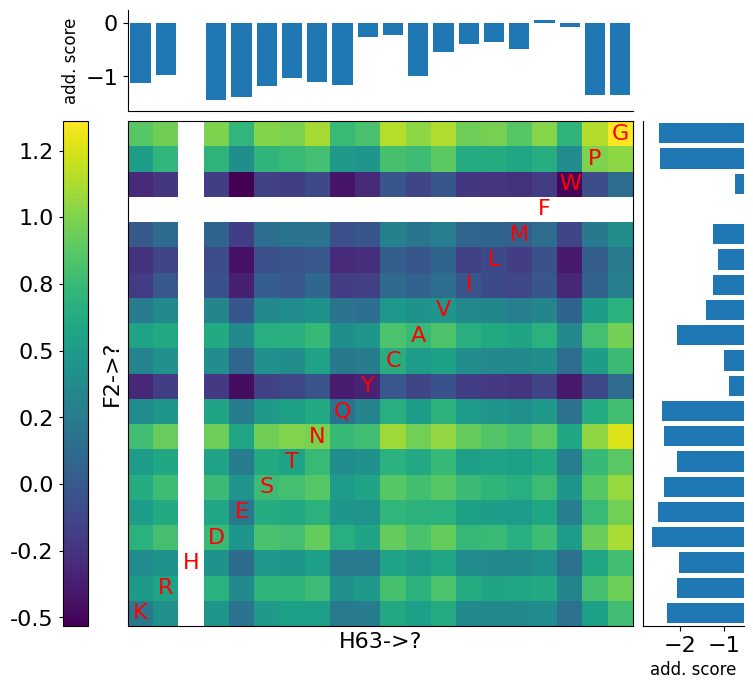

In [98]:
p_test_double = pt.loc[('6M3N', 2, 63), ('SPURS_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['SPURS_1']
pb = PB['SPURS_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

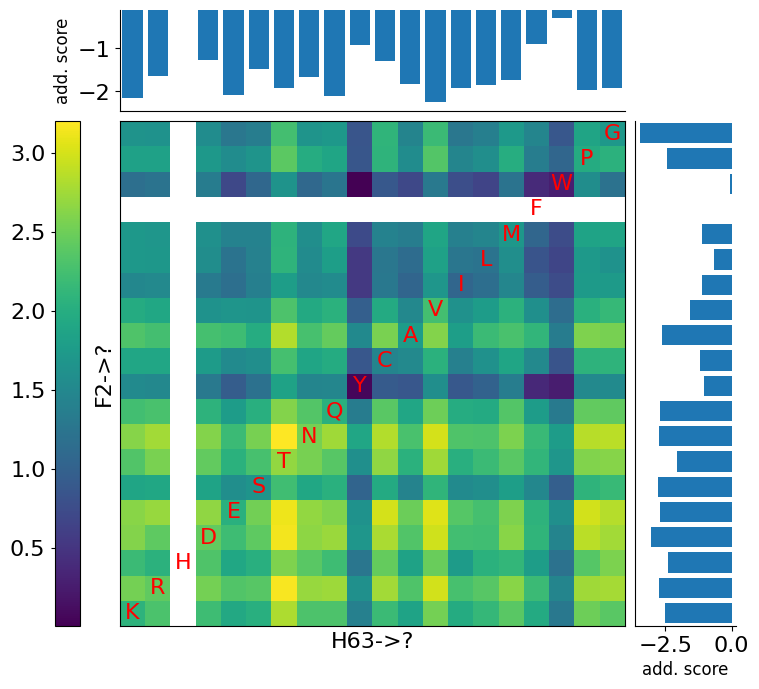

In [99]:
p_test_double = pt.loc[('6M3N', 2, 63), ('MutateEverything_1_dddG', slice(None))]
p_test_double = p_test_double.T.reset_index(level=0, drop=True).T
p_test_double.loc['F', :] = np.nan
p_test_double

AA = ['K', 'R', 'H', 'D', 'E', 'S', 'T', 'N', 'Q', 'Y', 'C', 'A', 'V', 'I', 'L', 'M', 'F', 'W', 'P', 'G']
p_test_double = p_test_double.loc[AA, AA]
#pa = p_test_double.mean(axis=1)
#pb = p_test_double.mean(axis=0)
pa = PA['MutateEverything_1']
pb = PB['MutateEverything_1']
_ = plot_joint_with_marginals(p_test_double, pa, pb, aa_labels=AA, pos1='F2->?', pos2='H63->?')

In [100]:
# Extract the part of 'code' after the last underscore.
# If no underscore, it takes the whole string.
# If 'code' is NaN, this will result in NaN.
part_after_last_underscore = df['code'].str.rsplit('_', n=1).str[-1]

# Regex for: one letter, two digits, one letter.
# ^ and $ ensure the entire extracted part matches this pattern.
# na=False ensures that if part_after_last_underscore is NaN, it evaluates to False.
regex_suffix_pattern = r'^[a-zA-Z]\d{2}[a-zA-Z]$'
condition2 = part_after_last_underscore.str.fullmatch(regex_suffix_pattern, na=False)

df_destab = df.loc[condition2]
df_no_destab = df.drop(df_destab.index)

# 1. Extract the part of 'code' before the first underscore.
#    If no underscore, it takes the whole string.
code_prefix = df['code'].str.split('_', n=1).str[0]

# 2. Define the regex to match strings containing only A, E, G, H, X.
#    ^ asserts position at start of the string.
#    [AEGHX] matches any character from the set A, E, G, H, X.
#    * matches the previous token between zero and unlimited times.
#    $ asserts position at the end of the string.
regex_pattern = r'^[AEGHX]*$'

# 3. Create a boolean Series by checking if the extracted prefix fully matches the regex.
#    .str.fullmatch() checks if the entire string matches the pattern.
#    .fillna(False) handles any NaN values that might result from NaN 'code' values
#    or if 'code' wasn't a string type initially for some rows.
matches = code_prefix.str.fullmatch(regex_pattern).fillna(False)
matches2 = df.loc[df['code'].str.contains('TrROS')].index

# 4. Use the boolean Series to filter the original DataFrame.
df_synthetic = df.loc[matches | df['code'].str.contains('TrROS', na=False, regex=False)]
df_natural = df.drop(df_synthetic.index)

df_singles = df.loc[~df['mut_type'].str.contains(':')]
df_doubles = df.loc[df['mut_type'].str.contains(':')]

# All raw predictions
df

,ThermoMPNN_1,ThermoMPNN(-D)_1,ThermoMPNN_2,ThermoMPNN(-D)_2,ThermoMPNN_3,ThermoMPNN(-D)_3,ThermoMPNN(-D)_additive_1,ThermoMPNN(-D)_additive_2,ThermoMPNN(-D)_additive_3,ddG_ML_thermo,...,ESM-MSR_chain_3,ESM-MSR_chain_additive_3,ESM3-small-open_chain,ESM3-small-open_chain_additive,random_1,random_2,random_3,ddG_1,ddG_2,ddG_3
uid,,,,,,,,,,,,,,,,,,,,,
1UFM_A11C,0.182458,0.182458,0.229011,0.229011,0.112110,0.112110,0.182458,0.229011,0.112110,0.004061,...,-0.008952,NaN,-3.500977,-3.500977,0.913376,0.459968,0.522266,-0.235782,0.148527,-0.259609
1UFM_A11D,-0.534806,-0.534806,-0.776187,-0.776187,-0.690362,-0.690362,-0.534806,-0.776187,-0.690362,-0.023454,...,-0.349982,NaN,-3.756836,-3.756836,0.789406,0.021178,0.182810,0.054258,0.337181,0.090922
1UFM_A11E,-0.127483,-0.127483,-0.176427,-0.176427,-0.169683,-0.169683,-0.127483,-0.176427,-0.169683,0.111864,...,-0.195433,NaN,-2.891602,-2.891602,0.181044,0.520047,0.516503,-0.058088,0.349476,0.211738
1UFM_A11F,-0.037749,-0.037749,-0.077629,-0.077629,-0.115784,-0.115784,-0.037749,-0.077629,-0.115784,-0.153650,...,-0.200250,NaN,-0.421875,-0.421875,0.216366,0.684693,0.749177,-0.168374,-0.247009,-0.118257
1UFM_A11G,-0.565192,-0.565192,-0.628311,-0.628311,-0.642682,-0.642682,-0.565192,-0.628311,-0.642682,-0.393182,...,-0.567176,NaN,-1.704346,-1.704346,0.088720,0.325236,0.152944,-0.406772,-0.330492,-0.333012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_R10Y:E36S,-1.687004,-0.557682,-1.533284,-1.408043,-1.497178,-0.774565,-1.687004,-1.533284,-1.497178,NaN,...,-1.184945,-1.764554,-6.273010,-8.136230,0.787544,0.009920,0.102083,-0.286645,-0.343389,-0.171350
HHH_rd1_0949_R10Y:E36T,-1.304661,-0.486829,-1.297930,-1.210776,-1.352677,-0.265816,-1.304661,-1.297930,-1.352677,NaN,...,-0.959004,-1.458845,-6.709229,-8.262451,0.067830,0.303121,0.814651,-0.302571,-0.494908,-0.517258
HHH_rd1_0949_R10Y:E36V,-0.525491,-0.274588,-0.531802,-0.501731,-0.583954,0.229817,-0.525491,-0.531802,-0.583954,NaN,...,-0.217062,-1.098734,-4.707153,-6.614746,0.053952,0.155416,0.064688,0.290594,0.451192,0.274116


In [101]:
df_destab

,ThermoMPNN_1,ThermoMPNN(-D)_1,ThermoMPNN_2,ThermoMPNN(-D)_2,ThermoMPNN_3,ThermoMPNN(-D)_3,ThermoMPNN(-D)_additive_1,ThermoMPNN(-D)_additive_2,ThermoMPNN(-D)_additive_3,ddG_ML_thermo,...,ESM-MSR_chain_3,ESM-MSR_chain_additive_3,ESM3-small-open_chain,ESM3-small-open_chain_additive,random_1,random_2,random_3,ddG_1,ddG_2,ddG_3
uid,,,,,,,,,,,,,,,,,,,,,
2K5H_G11S_A16C,0.046979,0.046979,0.249217,0.249217,0.076645,0.076645,0.046979,0.249217,0.076645,-0.213358,...,-0.127358,NaN,-4.082031,-4.082031,0.250601,0.004705,0.436844,-0.278691,-0.320639,-0.281729
2K5H_G11S_A16D,-1.036003,-1.036003,-0.852490,-0.852490,-1.009371,-1.009371,-1.036003,-0.852490,-1.009371,-2.029711,...,-0.919783,NaN,-2.433594,-2.433594,0.479127,0.941253,0.363692,-2.012858,-1.992412,-2.326532
2K5H_G11S_A16E,-0.587239,-0.587239,-0.503795,-0.503795,-0.641665,-0.641665,-0.587239,-0.503795,-0.641665,-1.146346,...,-0.429852,NaN,-0.200195,-0.200195,0.880821,0.866916,0.660296,-1.172746,-1.094036,-1.196475
2K5H_G11S_A16F,-0.024102,-0.024102,0.287125,0.287125,-0.126980,-0.126980,-0.024102,0.287125,-0.126980,-0.681503,...,-0.523631,NaN,-2.895508,-2.895508,0.768949,0.634952,0.612814,-0.647035,-0.689371,-0.764420
2K5H_G11S_A16G,-0.708306,-0.708306,-0.459338,-0.459338,-0.631421,-0.631421,-0.708306,-0.459338,-0.631421,-0.894964,...,-0.554826,NaN,-2.598633,-2.598633,0.000381,0.078794,0.776859,-0.762475,-1.147457,-1.009054
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2K5H_G23A_W32I,-1.067356,-1.067356,-0.905483,-0.905483,-1.144713,-1.144713,-1.067356,-0.905483,-1.144713,-2.467404,...,-1.256215,NaN,-11.465332,-11.465332,0.765735,0.541513,0.346740,-2.642083,-2.541817,-2.439619
2K5H_G23A_W32L,-0.775358,-0.775358,-0.826621,-0.826621,-1.234344,-1.234344,-0.775358,-0.826621,-1.234344,-1.535847,...,-1.303674,NaN,-9.309570,-9.309570,0.514429,0.340844,0.543863,-1.457797,-1.302714,-1.387792
2K5H_G23A_W32M,-1.115607,-1.115607,-1.004328,-1.004328,-1.199729,-1.199729,-1.115607,-1.004328,-1.199729,-1.658541,...,-1.275073,NaN,-9.964844,-9.964844,0.136183,0.102624,0.300545,-1.777603,-1.790224,-1.501191


In [102]:
df_synthetic

,ThermoMPNN_1,ThermoMPNN(-D)_1,ThermoMPNN_2,ThermoMPNN(-D)_2,ThermoMPNN_3,ThermoMPNN(-D)_3,ThermoMPNN(-D)_additive_1,ThermoMPNN(-D)_additive_2,ThermoMPNN(-D)_additive_3,ddG_ML_thermo,...,ESM-MSR_chain_3,ESM-MSR_chain_additive_3,ESM3-small-open_chain,ESM3-small-open_chain_additive,random_1,random_2,random_3,ddG_1,ddG_2,ddG_3
uid,,,,,,,,,,,,,,,,,,,,,
EA_run3_0321_0005_A17C,-0.830232,-0.830232,-0.766644,-0.766644,-0.724406,-0.724406,-0.830232,-0.766644,-0.724406,-1.642537,...,-0.464985,NaN,-9.240234,-9.240234,0.656996,0.168981,0.724606,-1.424462,-1.898644,-1.396660
EA_run3_0321_0005_A17D,-2.164598,-2.164598,-2.033794,-2.033794,-2.250737,-2.250737,-2.164598,-2.033794,-2.250737,-1.047616,...,-2.072132,NaN,-13.870117,-13.870117,0.201126,0.135700,0.779010,-1.148262,-0.832019,-0.976444
EA_run3_0321_0005_A17E,-2.029873,-2.029873,-1.955475,-1.955475,-2.051458,-2.051458,-2.029873,-1.955475,-2.051458,-1.141996,...,-2.076048,NaN,-13.519531,-13.519531,0.160607,0.318717,0.809987,-1.146384,-1.262044,-1.293976
EA_run3_0321_0005_A17F,-1.202985,-1.202985,-1.222521,-1.222521,-1.385140,-1.385140,-1.202985,-1.222521,-1.385140,-0.086403,...,-1.048928,NaN,-16.625000,-16.625000,0.464142,0.691414,0.609311,-0.136027,-0.167037,0.113191
EA_run3_0321_0005_A17G,-1.583284,-1.583284,-1.513969,-1.513969,-1.603062,-1.603062,-1.583284,-1.513969,-1.603062,-0.826196,...,-1.572290,NaN,-7.304688,-7.304688,0.371230,0.969540,0.776288,-0.789604,-1.022071,-0.919607
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
HHH_rd1_0949_R10Y:E36S,-1.687004,-0.557682,-1.533284,-1.408043,-1.497178,-0.774565,-1.687004,-1.533284,-1.497178,NaN,...,-1.184945,-1.764554,-6.273010,-8.136230,0.787544,0.009920,0.102083,-0.286645,-0.343389,-0.171350
HHH_rd1_0949_R10Y:E36T,-1.304661,-0.486829,-1.297930,-1.210776,-1.352677,-0.265816,-1.304661,-1.297930,-1.352677,NaN,...,-0.959004,-1.458845,-6.709229,-8.262451,0.067830,0.303121,0.814651,-0.302571,-0.494908,-0.517258
HHH_rd1_0949_R10Y:E36V,-0.525491,-0.274588,-0.531802,-0.501731,-0.583954,0.229817,-0.525491,-0.531802,-0.583954,NaN,...,-0.217062,-1.098734,-4.707153,-6.614746,0.053952,0.155416,0.064688,0.290594,0.451192,0.274116


In [103]:
df_scores_singles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_singles = df_scores_singles.iloc[:, -6:].dropna(how='all')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_singles = assess_grouped_spearman(df_singles, df_scores_singles, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_singles

df_scores_doubles = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_doubles = df_scores_doubles.iloc[:, -6:].dropna(how='all')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_doubles = assess_grouped_spearman(df_doubles, df_scores_doubles, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_doubles

df_scores_destab = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_destab = df_scores_destab.iloc[:, -6:].dropna(how='all')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_destab = assess_grouped_spearman(df_destab, df_scores_destab, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_destab

df_scores_no_destab = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_no_destab = df_scores_no_destab.iloc[:, -6:].dropna(how='all')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_no_destab = assess_grouped_spearman(df_no_destab, df_scores_no_destab, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_no_destab

df_scores_synthetic = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_synthetic = df_scores_synthetic.iloc[:, -6:].dropna(how='all')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_synthetic = assess_grouped_spearman(df_synthetic, df_scores_synthetic, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_synthetic

df_scores_natural = pd.DataFrame(index=pd.MultiIndex.from_product([['hyperopt_splits-test'], ['ungrouped', 'grouped']]))

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM-MSR_1', 'hyperopt_splits-test', pred_col='ESM-MSR_1', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM-MSR_2', 'hyperopt_splits-test', pred_col='ESM-MSR_2', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM-MSR_3', 'hyperopt_splits-test', pred_col='ESM-MSR_3', label='ddG')
df_scores_natural = df_scores_natural.iloc[:, -6:].dropna(how='all')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'SPURS_1', 'hyperopt_splits-test', pred_col='SPURS_1', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'SPURS_2', 'hyperopt_splits-test', pred_col='SPURS_2', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'SPURS_3', 'hyperopt_splits-test', pred_col='SPURS_3', label='ddG')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ThermoMPNN(-D)_1', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_1', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ThermoMPNN(-D)_2', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_2', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ThermoMPNN(-D)_3', 'hyperopt_splits-test', pred_col='ThermoMPNN(-D)_3', label='ddG')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'MutateEverything_1', 'hyperopt_splits-test', pred_col='MutateEverything_1', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'MutateEverything_2', 'hyperopt_splits-test', pred_col='MutateEverything_2', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'MutateEverything_3', 'hyperopt_splits-test', pred_col='MutateEverything_3', label='ddG')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM3-small-open', 'hyperopt_splits-test', pred_col='ESM3-small-open', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM3-small', 'hyperopt_splits-test', pred_col='ESM3-small', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM3-medium', 'hyperopt_splits-test', pred_col='ESM3-medium', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ESM3-large', 'hyperopt_splits-test', pred_col='ESM3-large', label='ddG')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'Rosetta Cartesian DDG_1', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_1', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'Rosetta Cartesian DDG_2', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_2', label='ddG')
df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'Rosetta Cartesian DDG_3', 'hyperopt_splits-test', pred_col='Rosetta Cartesian DDG_3', label='ddG')

df_scores_natural = assess_grouped_spearman(df_natural, df_scores_natural, 'ProteinMPNN', 'hyperopt_splits-test', pred_col='ProteinMPNN', label='ddG')

df_scores_natural

ESM-MSR_2  ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-test ungrouped   0.696444    18107.000               NaN   
                     grouped     0.814881     2263.375               8.0   

                                ESM-MSR_3  ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-test ungrouped   0.734315    18107.000               NaN   
                     grouped     0.828847     2263.375               8.0   

                                 SPURS_1  SPURS_1_n  SPURS_1_groups   SPURS_2  \
hyperopt_splits-test ungrouped  0.726755  18107.000             NaN  0.742205   
                     grouped    0.695642   2263.375             8.0  0.696805   

                                ...  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-test ungrouped  ...                             NaN   
                     grouped    ...                             8.0   

                                Rosetta Cartesian DDG_2  \
hyperopt_splits-test ungrouped                 0.687543   
                     grouped                   0.654939   

                                Rosetta Cartesian DDG_2_n  \
hyperopt_splits-test ungrouped                  18107.000   
                     grouped                     2263.375   

                                Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-test ungrouped                             NaN   
                     grouped                               8.0   

                                Rosetta Cartesian DDG_3  \
hyperopt_splits-test ungrouped                 0.688157   
                     grouped                   0.655726   

                                Rosetta Cartesian DDG_3_n  \
hyperopt_splits-test ungrouped                  18107.000   
                     grouped                     2263.375   

                                Rosetta Cartesian DDG_3_groups  ProteinMPNN  \
hyperopt_splits-test ungrouped                             NaN     0.574080   
                     grouped                               8.0     0.609302   

                                ProteinMPNN_n  ProteinMPNN_groups  
hyperopt_splits-test ungrouped      18107.000                 NaN  
                     grouped         2263.375                 8.0  

[2 rows x 57 columns]

In [104]:
df_scores_no_destab

ESM-MSR_2   ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-test ungrouped   0.710441  41398.000000               NaN   
                     grouped     0.802702   1217.588235              34.0   

                                ESM-MSR_3   ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-test ungrouped   0.730003  41398.000000               NaN   
                     grouped     0.800651   1217.588235              34.0   

                                 SPURS_1     SPURS_1_n  SPURS_1_groups  \
hyperopt_splits-test ungrouped  0.713068  41398.000000             NaN   
                     grouped    0.648094   1217.588235            34.0   

                                 SPURS_2  ...  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-test ungrouped  0.723446  ...                             NaN   
                     grouped    0.606036  ...                            34.0   

                                Rosetta Cartesian DDG_2  \
hyperopt_splits-test ungrouped                 0.656900   
                     grouped                   0.631244   

                                Rosetta Cartesian DDG_2_n  \
hyperopt_splits-test ungrouped               41398.000000   
                     grouped                  1217.588235   

                                Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-test ungrouped                             NaN   
                     grouped                              34.0   

                                Rosetta Cartesian DDG_3  \
hyperopt_splits-test ungrouped                 0.656627   
                     grouped                   0.630218   

                                Rosetta Cartesian DDG_3_n  \
hyperopt_splits-test ungrouped               41398.000000   
                     grouped                  1217.588235   

                                Rosetta Cartesian DDG_3_groups  ProteinMPNN  \
hyperopt_splits-test ungrouped                             NaN     0.592264   
                     grouped                              34.0     0.520064   

                                ProteinMPNN_n  ProteinMPNN_groups  
hyperopt_splits-test ungrouped   41398.000000                 NaN  
                     grouped      1217.588235                34.0  

[2 rows x 57 columns]

In [105]:
df_scores_destab

ESM-MSR_2  ESM-MSR_2_n  ESM-MSR_2_groups  \
hyperopt_splits-test ungrouped   0.857670       2302.0               NaN   
                     grouped     0.861254       1151.0               2.0   

                                ESM-MSR_3  ESM-MSR_3_n  ESM-MSR_3_groups  \
hyperopt_splits-test ungrouped   0.897297       2302.0               NaN   
                     grouped     0.903501       1151.0               2.0   

                                 SPURS_1  SPURS_1_n  SPURS_1_groups   SPURS_2  \
hyperopt_splits-test ungrouped  0.679272     2302.0             NaN  0.693324   
                     grouped    0.687327     1151.0             2.0  0.699201   

                                ...  Rosetta Cartesian DDG_1_groups  \
hyperopt_splits-test ungrouped  ...                             NaN   
                     grouped    ...                             2.0   

                                Rosetta Cartesian DDG_2  \
hyperopt_splits-test ungrouped                 0.682457   
                     grouped                   0.689193   

                                Rosetta Cartesian DDG_2_n  \
hyperopt_splits-test ungrouped                     2302.0   
                     grouped                       1151.0   

                                Rosetta Cartesian DDG_2_groups  \
hyperopt_splits-test ungrouped                             NaN   
                     grouped                               2.0   

                                Rosetta Cartesian DDG_3  \
hyperopt_splits-test ungrouped                 0.681398   
                     grouped                   0.687582   

                                Rosetta Cartesian DDG_3_n  \
hyperopt_splits-test ungrouped                     2302.0   
                     grouped                       1151.0   

                                Rosetta Cartesian DDG_3_groups  ProteinMPNN  \
hyperopt_splits-test ungrouped                             NaN     0.686885   
                     grouped                               2.0     0.689380   

                                ProteinMPNN_n  ProteinMPNN_groups  
hyperopt_splits-test ungrouped         2302.0                 NaN  
                     grouped           1151.0                 2.0  

[2 rows x 57 columns]

(<Figure size 1600x1000 with 1 Axes>,
 <Axes: title={'center': 'Singles vs. Doubles'}, ylabel="Average Spearman's ρ">)

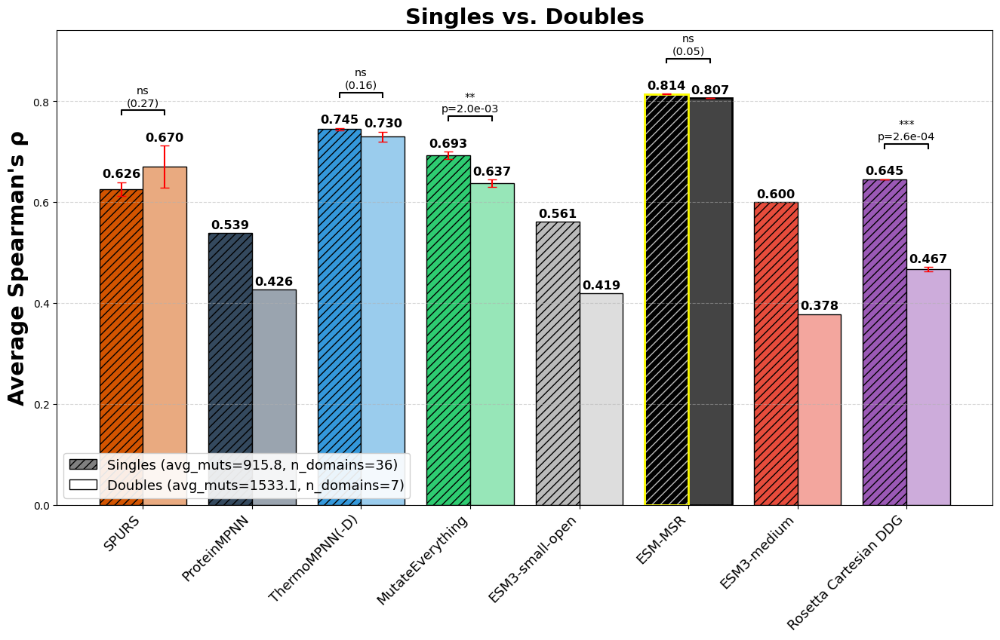

In [106]:
import importlib
importlib.reload(analysis_utils_msr)

analysis_utils_msr.create_metric_comparison_chart_epistatic(df_scores_singles.loc[('hyperopt_splits-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], highlighted_model='ESM-MSR', title='Singles vs. Doubles', y_label='Average Spearman\'s ρ',
                                             series2=df_scores_doubles.loc[('hyperopt_splits-test', 'grouped')], series_names=('Singles', 'Doubles'), fontsize_multiplier=1.3, figsize=(16,10), legend_loc='lower left') #'ESM3-small', 'ESM3-large',

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Native vs. Destabilized'}, ylabel="Average Spearman's ρ">)

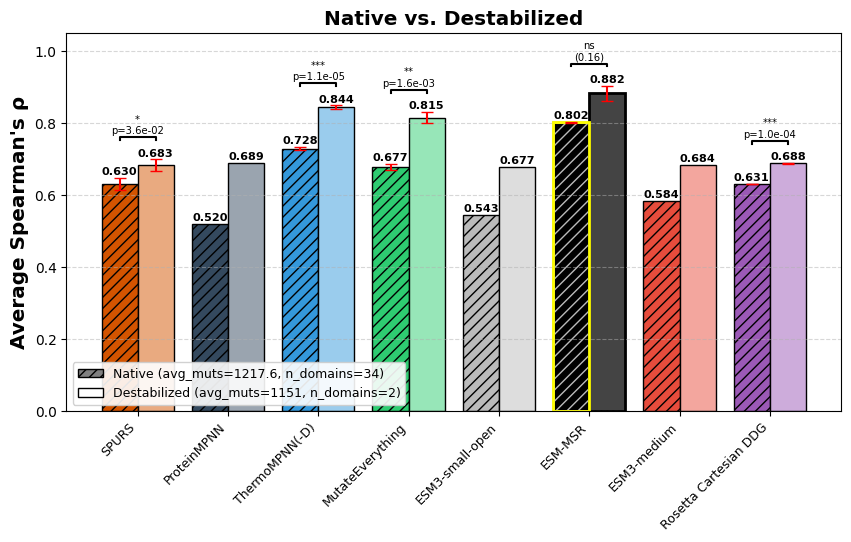

In [107]:
analysis_utils_msr.create_metric_comparison_chart_epistatic(df_scores_no_destab.loc[('hyperopt_splits-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], highlighted_model='ESM-MSR', title='Native vs. Destabilized', y_label='Average Spearman\'s ρ',
                                             series2=df_scores_destab.loc[('hyperopt_splits-test', 'grouped')], series_names=('Native', 'Destabilized'), fontsize_multiplier=.9, figsize=(10,6), legend_loc='lower left', ylim=(0,1.05))

(<Figure size 1000x600 with 1 Axes>,
 <Axes: title={'center': 'Natural vs. Synthetic'}, ylabel="Average Spearman's ρ">)

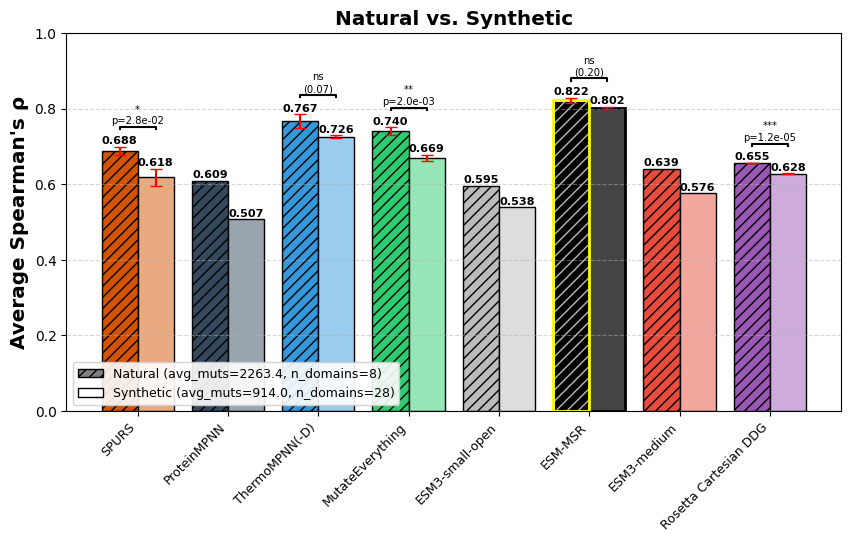

In [108]:
analysis_utils_msr.create_metric_comparison_chart_epistatic(df_scores_natural.loc[('hyperopt_splits-test', 'grouped')], ['SPURS', 'ProteinMPNN', 'ThermoMPNN(-D)', 'MutateEverything', 'ESM3-small-open', 'ESM-MSR', 'ESM3-medium', 'Rosetta Cartesian DDG'], highlighted_model='ESM-MSR', title='Natural vs. Synthetic', y_label='Average Spearman\'s ρ',
                                             series2=df_scores_synthetic.loc[('hyperopt_splits-test', 'grouped')], series_names=('Natural', 'Synthetic'), fontsize_multiplier=.9, figsize=(10,6), legend_loc='lower left', ylim=(0,1))